# 10 — Max μ-LJ isolation × |Δφ| (4μ)

기존 6D 히스토그램에서 전임 연구의 축 조합을 구성하고 네 가지 cut/WP 조합을 검진한다. 현재 isolation 정의를 사용하며 전임 PF-cone isolation과 전체 분석 선택을 재현하는 것은 아니다.

행은 **max(iso0,iso1) 경계 0.25 / 0.50**, 열은 **|Δφ| 경계 2.0 / 1.5**다. 개별 μ-LJ isolation에 별도 상한 사전 cut을 적용하지 않는다. 네 패널의 분포는 같으며 ABCD 경계만 다르다.

M(LJ,LJ) ≥150 GeV와 05–08의 SR/VR displacement 정의를 유지한다. A가 낮은 isolation·큰 |Δφ| 사분면이고 Â=BC/D, κ=A/Â다. 전임 AN의 신호 사분면 D는 이 노트북의 A에 해당한다.

DATA는 기존 네 displaced signal reference의 SR leakage 조건을 다시 계산한 뒤 허용된 VR 지점만 평가한다. SR DATA는 투영·적분·표시·저장하지 않는다. 결과가 좋지 않거나 통계가 부족한 조합도 그대로 표시한다.


In [1]:
from pathlib import Path
import ast
import gc
import hashlib
import json
import sys
from datetime import datetime, timezone

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from within the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
STUDIES_DIR = SIDM_DIR / "studies"

# Import coffea/pyarrow before registering NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42})
pd.set_option("display.max_columns", 20)


## 입력과 네 가지 조합

max-isolation 경계 두 개와 각도 경계 두 개를 교차한다. `ROW_ISO_VALUES`는 ABCD 경계이며 이벤트 사전 선택이 아니다.

모든 경계는 저장된 bin edge와 정확히 일치해야 한다. bin 내부 보간은 사용하지 않는다. 출력은 이 노트북 전용 디렉토리에 저장한다.


In [2]:
TOPOLOGY = '4mu'
NOTEBOOK_NAME = '10_MaxIso_DPhi_4mu_6D_comparison.ipynb'
TIGHT_BOUNDARY = {"dphi": 2.0}
LOOSE_BOUNDARY = {"dphi": 1.5}
PLANE_KIND = 'max_mu_iso'
ROW_ISO_VALUES = {"p025": .25, "p050": .5}
MASS_MIN = 150.0
SR_YIELD_YLIM = None
MAX_SIGNAL_FRACTION = .10  # Contamination diagnostic only.
GATE_MODE = "leakage"
LEAKAGE_LIMIT = .15
LEAKAGE_CONTEXTS = ("SR",)
SHAPE_SIGNAL_SCALE = {}  # Independent optional shape overrides; empty means raw stored weights.
SIGNAL_REFERENCES = {'mA200': '4Mu_200GeV_0p25GeV_1p0mm', 'mA500': '4Mu_500GeV_0p25GeV_0p4mm', 'mA800': '4Mu_800GeV_0p25GeV_0p25mm', 'mA1000': '4Mu_1000GeV_0p25GeV_0p2mm'}
SIGNAL_SCALE = {}
RUN_DATA = True
SAVE_FIGURES = True
EXPORT_TABLES = True
OUTPUT_DIR = NOTEBOOK_DIR / '10_MaxIso_DPhi_4mu_6D_comparison_outputs'
CONFIG = {
    "topology": TOPOLOGY,
    "current_dir": NOTEBOOK_DIR / "ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1",
    "bkg_dir": NOTEBOOK_DIR / "ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1",
    "signal_dir": NOTEBOOK_DIR / "ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1",
    "data_dir": NOTEBOOK_DIR / "ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1",
    "current_hist": "abcd6d_"+TOPOLOGY,
    "expected_current_channel": "abcd6d_inclusive_"+TOPOLOGY+"_dxySpread_cosAlpha_mu_veto_eHEM",
    "tight_boundary": TIGHT_BOUNDARY,
    "loose_boundary": LOOSE_BOUNDARY,
    "plane_kind": PLANE_KIND,
    "row_iso_values": ROW_ISO_VALUES,
    "mass_min": MASS_MIN,
    "pixel_max": 2,
    "lost_min": 1,
    "iso_scan_max": 1.0,
    "iso_grid": np.array([.05,.10,.15,.20,.25,.30,.40,.50]),
    "dphi_grid": np.array([1.0,1.5,2.0,2.2,2.4,2.6,2.8,3.0]),
    "signal_references": SIGNAL_REFERENCES,
    "signal_scale": SIGNAL_SCALE,
    "max_signal_fraction": MAX_SIGNAL_FRACTION,
    "gate_mode": GATE_MODE, "leakage_limit": LEAKAGE_LIMIT, "leakage_contexts": LEAKAGE_CONTEXTS,
    "shape_signal_scale": SHAPE_SIGNAL_SCALE,
    "min_neff": 10.,
    "expected_background_count": 18,
    "expected_data_count": 68,
    "run_data": RUN_DATA,
    "source_label": "MC",
    "yield_ylim_by_context": {},
    "x_label": 'Max mu-LJ isolation',
    "y_label": "|Δφ| [rad]",
}
print("Tight boundary:", TIGHT_BOUNDARY, "loose boundary:", LOOSE_BOUNDARY)
print("Isolation row settings:", ROW_ISO_VALUES, "; M(LJ,LJ) >=", MASS_MIN, "GeV")
print("Delta phi is an ABCD axis: no delta-phi event preselection is applied.")

PRIOR_NOTEBOOK_OUTPUT = '08_MuIso_DPhi_4mu_6D_comparison_outputs'


Tight boundary: {'dphi': 2.0} loose boundary: {'dphi': 1.5}
Isolation row settings: {'p025': 0.25, 'p050': 0.5} ; M(LJ,LJ) >= 150.0 GeV
Delta phi is an ABCD axis: no delta-phi event preselection is applied.


## 평면 재구성과 공통 계산

원본 축 순서는 iso0, iso1, disp0, disp1, abs_dphi, ljlj_mass다. 두 개별 isolation underflow를 먼저 제외한다. 허용된 isolation overflow와 Δφ 양쪽 flow는 유지하며 mass overflow도 포함한다.

2μ2e는 μ isolation 사전 cut 후 iso1–abs_dphi로 투영한다. 4μ는 두 iso의 공동 분포를 max bin으로 합치며 대각선은 한 번만 더한다. 각 투영에서 선택된 sumw와 sumw² 보존을 검사한다.

SR: 2μ2e는 mu pixel≤2 AND EGM lost≥1, 4μ는 두 mu pixel≤2. VR: 2μ2e는 mu pixel>2 AND EGM lost<1, 4μ는 두 mu pixel>2로 두 조건을 모두 반전한다. 05–08과 동일한 통계 계산 및 저통계 표시를 사용한다.


In [3]:
"""Current-6D EGM/max isolation versus absolute delta-phi ABCD comparison.

Standalone MC preparation and late, point-gated DATA VR evaluation.
EGM uses a muon-isolation precut; max isolation has no partner upper cut. Both displayed plane axes retain pass/fail sides:
x passes below its isolation boundary, y passes above its angle boundary.
"""
from pathlib import Path
from datetime import datetime, timezone
import copy
import gc
import hashlib
import json
import sys

import coffea.util
import numpy as np
import pandas as pd
import yaml

if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)

PLANE_PROFILE_VALUES = dict(CONFIG["row_iso_values"])
PLANE_BENCHMARKS = ("p025_tight", "p025_loose", "p050_tight", "p050_loose")
PLANE_CONTEXTS = ("SR", "VR")
PLANE_COMPONENTS = ("QCD", "DY", "TTJets", "Diboson")
COMPARISON_VARIABLES = ("iso0", "iso1", "disp0", "disp1", "abs_dphi", "ljlj_mass")


def _comparison_json(value):
    def convert(item):
        if isinstance(item, (set, frozenset)):
            return sorted(item, key=str)
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, np.ndarray):
            return item.tolist()
        if isinstance(item, Path):
            return str(item)
        return str(item)
    return json.dumps(value, sort_keys=True, default=convert)


def _comparison_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _comparison_group(sample):
    if sample.startswith("QCD_"):
        return "QCD"
    if sample.startswith("DYJetsTo"):
        return "DY"
    if sample == "TTJets":
        return "TTJets"
    if sample in {"WW", "WZ", "ZZ"}:
        return "Diboson"
    raise ValueError(f"Unexpected MC background sample: {sample}")


def _comparison_split(edges, threshold):
    matches = np.flatnonzero(np.isclose(edges, float(threshold), rtol=0, atol=1e-12))
    if len(matches) != 1:
        raise ValueError(f"A requested threshold is not a unique stored bin edge: {threshold}")
    return int(matches[0]) + 1  # Numeric underflow is index zero.


def _comparison_validate_arrays(values, variances):
    if variances is None or values.shape != variances.shape:
        raise ValueError("Weighted values and sumw2 must have the same shape.")
    if not np.isfinite(values).all() or not np.isfinite(variances).all():
        raise ValueError("The selected histogram contains nonfinite weights or sumw2.")
    if np.any(variances < 0):
        raise ValueError("The selected histogram contains negative sumw2.")


def _comparison_plane(values, variances, xedges, yedges):
    values = np.asarray(values, dtype=float).copy()
    variances = np.asarray(variances, dtype=float).copy()
    _comparison_validate_arrays(values, variances)
    xedges = np.asarray(xedges, dtype=float).copy()
    yedges = np.asarray(yedges, dtype=float).copy()
    if values.shape != (len(xedges) + 1, len(yedges) + 1):
        raise ValueError("The 2D plane must contain both numeric flow bins on each axis.")
    return dict(values=values, variances=variances, xedges=xedges, yedges=yedges)


def _comparison_add(target, incoming, component):
    if target is None:
        target = _comparison_plane(incoming["values"], incoming["variances"],
                                   incoming["xedges"], incoming["yedges"])
        target["values"][:] = 0
        target["variances"][:] = 0
        target["components"] = {}
    if not all(np.array_equal(target[key], incoming[key]) for key in ("xedges", "yedges")):
        raise ValueError("Cannot combine planes with different numeric bin edges.")
    target["values"] += incoming["values"]
    target["variances"] += incoming["variances"]
    if component not in target["components"]:
        target["components"][component] = dict(
            values=np.zeros_like(incoming["values"]),
            variances=np.zeros_like(incoming["variances"]))
    target["components"][component]["values"] += incoming["values"]
    target["components"][component]["variances"] += incoming["variances"]
    return target


def _comparison_payload(path, source):
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"The payload sample identity does not match its file name: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", ())) != {False}:
        raise ValueError(f"Only explicitly identified MC backgrounds may be loaded: {path}")
    if set(metadata.get("unweighted_hist", ())) != {False}:
        raise ValueError(f"A weighted production is required: {path}")
    if {str(value) for value in metadata.get("year", ())} != {"2018"}:
        raise ValueError(f"The payload must have a unique 2018 year: {path}")
    if "hists" not in payload or "cutflow" not in payload:
        raise ValueError(f"Missing histograms or production cutflows: {path}")
    return loaded, payload


def _comparison_validate_hist(histogram, path):
    if histogram.storage_type.__name__ != "Weight":
        raise ValueError(f"Weight storage is required: {path}")
    for axis in histogram.axes:
        if not axis.traits.discrete and not (axis.traits.underflow and axis.traits.overflow):
            raise ValueError(f"Numeric flow bins are required: {path}/{axis.name}")


def _comparison_current_cube(payload, path, config):
    expected_hists = {f"abcd6d_{topology}" for topology in ("2mu2e", "4mu")} | {
        f"abcd6d_ref_{topology}_{pair}" for topology in ("2mu2e", "4mu")
        for pair in ("iso0_vs_iso1", "iso0_vs_abs_dphi", "disp0_vs_disp1")}
    if set(payload["hists"]) != expected_hists:
        raise ValueError(f"The current 6D campaign histogram schema differs: {path}")
    histogram = payload["hists"][config["current_hist"]]
    _comparison_validate_hist(histogram, path)
    if tuple(axis.name for axis in histogram.axes) != ("channel",) + COMPARISON_VARIABLES:
        raise ValueError(f"Current 6D axis order mismatch: {path}")
    channel_axis = histogram.axes["channel"]
    if (list(channel_axis) != [config["expected_current_channel"]]
            or not channel_axis.traits.discrete
            or channel_axis.traits.underflow or channel_axis.traits.overflow):
        raise ValueError(f"Current topology channel identity/flow mismatch: {path}")
    expected_edges = {
        "iso0": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "iso1": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "disp0": np.arange(-.5, 12, 1),
        "disp1": np.arange(-.5, 10 if config["topology"] == "2mu2e" else 12, 1),
        "abs_dphi": [0, .5, 1, 1.5, 2, 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3, 3.05, 3.1, np.pi],
        "ljlj_mass": [0, 50, 100, 150, 200, 300, 400, 600, 800, 1000, 1500, 2500],
    }
    edges = {name: np.asarray(histogram.axes[name].edges, dtype=float) for name in COMPARISON_VARIABLES}
    for name in COMPARISON_VARIABLES:
        expected = np.asarray(expected_edges[name], dtype=float)
        if edges[name].shape != expected.shape or not np.allclose(edges[name], expected, rtol=0, atol=1e-12):
            raise ValueError(f"Current campaign stored bin edges differ: {path}/{name}")
    weights, variances = histogram.values(flow=True), histogram.variances(flow=True)
    expected_shape = (1,) + tuple(len(edges[name]) + 1 for name in COMPARISON_VARIABLES)
    if variances is None or weights.shape != expected_shape or variances.shape != expected_shape:
        raise ValueError(f"Current 6D weighted values/variance shape mismatch: {path}")
    return weights[0], variances[0], edges


def plane_statistics(plane, tx, ty, include_iso_underflow=False, min_neff=10.):
    """Match ABCD_Study/10 prediction/closure conventions; annotate edge cases.

    B, C and D are total background sums. No negative sumw is clipped. The
    relative-error formula intentionally reproduces ABCD_Study/10's zero-sideband
    uncertainty convention; its mathematical limitation is flagged in status.
    """
    regions = _comparison_regions(plane, tx, ty, include_iso_underflow)
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan,
               status="UNDEFINED_PREDICTION", kappa_status="UNDEFINED_PREDICTION")
    for name, item in regions.items():
        row.update({name: item["value"], "var_" + name: item["variance"],
                    name + "_error": item["error"], "neff_" + name: item["neff"]})
    neffs = np.array([regions[name]["neff"] for name in "ABCD"])
    row.update(neff_min=float(np.min(neffs)), min_neff=float(np.min(neffs)),
               min_sideband_neff=float(np.min(neffs[1:])),
               low_stat=bool(not np.all(np.isfinite(neffs) & (neffs >= min_neff))))
    a, b, c, d = (regions[name]["value"] for name in "ABCD")
    ea, eb, ec, ed = (regions[name]["error"] for name in "ABCD")
    if d <= 0 or not np.all(np.isfinite([b, eb, c, ec, d, ed])):
        row["status"] = "NONPOSITIVE_D_OR_NONFINITE_SIDEBAND"
        row["kappa_status"] = row["status"]
        return row
    pred = b * c / d
    terms = [(eb / b)**2 if b else 0., (ec / c)**2 if c else 0., (ed / d)**2]
    epred = abs(pred) * np.sqrt(sum(terms))
    row.update(pred=pred, pred_error=epred)
    if b == 0 or c == 0:
        row["status"] = "ZERO_SIDEBAND_LEGACY_ZERO_PREDICTION_ERROR"
    elif b < 0 or c < 0:
        row["status"] = "NEGATIVE_SIDEBAND_RETAINED"
    else:
        row["status"] = "LOW_STAT_SIDEBAND" if not np.all(
            np.isfinite(neffs[1:]) & (neffs[1:] >= min_neff)) else "OK"
    if np.isfinite(a) and pred > 0:
        row["kappa"] = a / pred
        if a > 0:
            row["kappa_error"] = abs(row["kappa"]) * np.sqrt((ea / a)**2 + (epred / pred)**2)
            row["kappa_status"] = "LOW_STAT" if row["low_stat"] else "OK"
        else:
            row["kappa_status"] = "NONPOSITIVE_A_LEGACY_KAPPA_ERROR_UNDEFINED"
    else:
        row["kappa_status"] = "NONPOSITIVE_PREDICTION_OR_NONFINITE_A"
    if np.isfinite(a) and ea**2 + epred**2 > 0:
        row["pull"] = (a - pred) / np.sqrt(ea**2 + epred**2)
    return row


def _comparison_cutflow_rows(payload, path, source, config):
    channels = {"Inclusive": config["expected_current_channel"]}
    rows = []
    for context, channel in channels.items():
        flow = payload["cutflow"].get(channel)
        if flow is None or not isinstance(getattr(flow, "rows", None), dict):
            raise ValueError(f"An auditable SimpleCutflow is missing: {path}/{channel}")
        for sequence, (cut, counts) in enumerate(flow.rows.items()):
            rows.append(dict(source=source, sample=path.stem, component=_comparison_group(path.stem),
                             context=context, channel=channel, sequence=sequence, cut=cut,
                             raw=float(counts["raw"]), weighted=float(counts["weighted"]),
                             interpretation="Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently"))
    return rows


def _extension_reference_metadata(config):
    """Validate the four displaced mass references and describe their physical points."""
    expected = {"mA200": (200., 1.), "mA500": (500., .4),
                "mA800": (800., .25), "mA1000": (1000., .2)}
    references = config["signal_references"]
    if set(references) != set(expected) or len(set(references.values())) != 4:
        raise ValueError("Exactly four distinct displaced references for mA=200, 500, 800 and 1000 GeV are required.")
    prefix = "2Mu2E" if config["topology"] == "2mu2e" else "4Mu"
    physical = {}
    for role, (mass, lifetime) in expected.items():
        sample = references[role]
        parts = sample.split("_")
        try:
            if len(parts) != 4 or parts[0] != prefix:
                raise ValueError("Topology/sample naming mismatch")
            mA = float(parts[1].removesuffix("GeV").replace("p", "."))
            mZd = float(parts[2].removesuffix("GeV").replace("p", "."))
            ctau = float(parts[3].removesuffix("mm").replace("p", "."))
        except (ValueError, AttributeError) as error:
            raise ValueError(f"Invalid named displaced reference: {role}/{sample}") from error
        if not all(np.isclose(actual, required, rtol=0, atol=1e-12)
                   for actual, required in ((mA, mass), (mZd, .25), (ctau, lifetime))):
            raise ValueError(f"Displaced reference {role} must have mA={mass:g} GeV, mZd=0.25 GeV and ctau={lifetime:g} mm.")
        supplied = config.get("signal_reference_metadata", {}).get(role, {})
        for key, actual in (("mA_GeV", mA), ("mZd_GeV", mZd), ("ctau_mm", ctau)):
            if key in supplied and not np.isclose(float(supplied[key]), actual, rtol=0, atol=1e-12):
                raise ValueError(f"Reference metadata contradict the sample identity: {role}/{key}")
        if supplied.get("reference_kind", "displaced") != "displaced":
            raise ValueError(f"Every named reference must be displaced: {role}")
        average = float(supplied.get("avg_transverse_cm", 30.))
        if not np.isfinite(average) or not np.isclose(average, 30., rtol=0, atol=1e-12):
            raise ValueError("The selected four-reference comparison uses a nominal average transverse displacement of 30 cm.")
        physical[role] = dict(mA_GeV=mA, mZd_GeV=mZd, ctau_mm=ctau,
                              reference_kind="displaced", avg_transverse_cm=average,
                              displacement_metadata="Nominal signal-grid average transverse decay length; not an event-level requirement")
    return physical


def _extension_coarsen_regular(plane, ex, ey, key):
    """Exclude flow and regular bins outside the common support; never fold tails."""
    native_x, native_y = plane["xedges"], plane["yedges"]
    values = np.asarray(plane[key], dtype=float)[1:-1, 1:-1]
    selected_x = (native_x[:-1] >= ex[0] - 1e-12) & (native_x[1:] <= ex[-1] + 1e-12)
    selected_y = (native_y[:-1] >= ey[0] - 1e-12) & (native_y[1:] <= ey[-1] + 1e-12)
    low_x, low_y = native_x[:-1][selected_x].copy(), native_y[:-1][selected_y].copy()
    for edge in ex:
        low_x[np.isclose(low_x, edge, rtol=0, atol=1e-12)] = edge
    for edge in ey:
        low_y[np.isclose(low_y, edge, rtol=0, atol=1e-12)] = edge
    ix, iy = np.searchsorted(ex, low_x, side="right") - 1, np.searchsorted(ey, low_y, side="right") - 1
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    output = np.zeros((len(ex) - 1, len(ey) - 1), dtype=float)
    np.add.at(output, (xx.ravel(), yy.ravel()), values[np.ix_(selected_x, selected_y)].ravel())
    return output


def extension_correlations(plane, tx, ty, ex, ey, min_neff=10.):
    """Weighted Pearson in All/A/B/C/D at centers of shared coarsened bins."""
    regions = ("All", "A", "B", "C", "D")
    if plane is None:
        return [dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan,
                     status="GATE_BLOCKED", sumw=np.nan, sumw2=np.nan, negative_bins=np.nan,
                     display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                     support="Native regular-bin support only; both plane flow axes excluded")
                for region in regions]
    values = _extension_coarsen_regular(plane, ex, ey, "values")
    variances = _extension_coarsen_regular(plane, ex, ey, "variances")
    negative_plane = dict(plane, values=(plane["values"] < 0).astype(float))
    native_negative = _extension_coarsen_regular(negative_plane, ex, ey, "values")
    xx, yy = np.broadcast_arrays(((ex[:-1] + ex[1:]) / 2)[:, None], ((ey[:-1] + ey[1:]) / 2)[None, :])
    xpass, ypass = xx < tx, yy >= ty
    masks = (np.ones(xx.shape, bool), xpass & ypass, ~xpass & ypass, xpass & ~ypass, ~xpass & ~ypass)
    rows = []
    for region, mask in zip(regions, masks):
        weights, vars_ = values[mask], variances[mask]
        row = dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan, status="EMPTY",
                   sumw=float(weights.sum()), sumw2=float(vars_.sum()), negative_bins=int(np.sum(weights < 0)),
                   native_negative_bins=int(native_negative[mask].sum()),
                   display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                   support="Native regular-bin support only; both plane flow axes excluded")
        if not np.isfinite(weights).all() or not np.isfinite(vars_).all() or np.any(vars_ < 0):
            row["status"] = "INVALID_WEIGHT_OR_VARIANCE"
        elif np.any(weights < 0) or row["native_negative_bins"] > 0:
            row["status"] = "NEGATIVE_BINS_NOT_A_PROBABILITY_DISTRIBUTION"
        elif row["sumw"] > 0 and row["sumw2"] > 0:
            row["neff"] = row["sumw"]**2 / row["sumw2"]
            xs, ys = xx[mask], yy[mask]
            mx, my = np.dot(weights, xs) / row["sumw"], np.dot(weights, ys) / row["sumw"]
            vx = np.dot(weights, (xs - mx)**2) / row["sumw"]
            vy = np.dot(weights, (ys - my)**2) / row["sumw"]
            if vx <= 0 or vy <= 0:
                row["status"] = "NO_SPREAD"
            else:
                rho = float(np.dot(weights, (xs - mx) * (ys - my)) / row["sumw"] / np.sqrt(vx * vy))
                if not np.isfinite(rho) or abs(rho) > 1 + 1e-10:
                    row["status"] = "INVALID_MOMENTS"
                else:
                    row.update(rho=float(np.clip(rho, -1, 1)), correlation=float(np.clip(rho, -1, 1)),
                               status="LOW_STAT" if row["neff"] < min_neff else "OK")
        elif row["sumw"] > 0:
            row["status"] = "ZERO_VARIANCE_UNSUPPORTED"
        rows.append(row)
    return rows


def _extension_manifest(path, source, kind, role=None, loaded=True):
    row = dict(source=source, kind=kind, sample=path.stem, reference_role=role,
               file=str(path.resolve()), bytes=path.stat().st_size, loaded=bool(loaded), extra_scale=1.)
    if not loaded:
        row["status"] = "NO_APPROVED_MC_GATE_POINT_NOT_OPENED"
        return row
    metadata_path = path.with_suffix(".meta.yaml")
    if not metadata_path.is_file():
        raise FileNotFoundError(f"Input metadata are required: {metadata_path}")
    with metadata_path.open() as handle:
        metadata = yaml.safe_load(handle)
    matching = [sample for sample in metadata.get("samples", []) if sample["name"] == path.stem]
    if len(matching) != 1 or metadata.get("n_samples") != 1 or metadata.get("unweighted_hist") is not False:
        raise ValueError(f"Weighted single-sample metadata mismatch: {metadata_path}")
    sample = matching[0]
    uris = tuple(str(uri) for uri in sample.get("files", []))
    if len(uris) != sample["n_files"] or len(set(uris)) != len(uris) or not uris:
        raise ValueError(f"Invalid input URI metadata: {metadata_path}")
    row.update(metadata_file=str(metadata_path.resolve()), metadata_sha256=_comparison_hash(metadata_path),
               sha256=_comparison_hash(path), sidm_commit=metadata.get("sidm_commit"),
               coffea_version=metadata.get("coffea_version"), created_utc=metadata.get("created_utc"),
               n_input_files=len(uris), xsec_pb=sample.get("xsec_pb"),
               input_uri_sha256=hashlib.sha256(_comparison_json(sorted(uris)).encode()).hexdigest(), status="LOADED")
    return row


def _extension_data_payload(path):
    """Validate DATA identity without inspecting any DATA SR selection or values."""
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"DATA payload sample identity mismatch: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", [])) != {True}:
        raise ValueError(f"Explicit DATA metadata are required: {path}")
    if set(metadata.get("unweighted_hist", [])) != {False}:
        raise ValueError(f"Expected weighted DATA storage configuration: {path}")
    if {str(value) for value in metadata.get("year", [])} != {"2018"}:
        raise ValueError(f"Expected unique 2018 DATA metadata: {path}")
    return loaded, payload


def _extension_signal_statistics(signal, background, tx, ty, min_neff):
    stats = _comparison_regions(signal, tx, ty)
    bkg = _comparison_regions(background, tx, ty)
    row = dict(tx=float(tx), ty=float(ty), s_over_b=np.nan, s_over_b_error=np.nan,
               signal_to_background=np.nan, leakage=np.nan, leakage_error=np.nan,
               leakage_percent=np.nan, signal_total=np.nan, status="UNSUPPORTED", signal_status="UNSUPPORTED")
    for region in "ABCD":
        row.update({"signal_" + region: stats[region]["value"],
                    "signal_var_" + region: stats[region]["variance"],
                    "var_signal_" + region: stats[region]["variance"],
                    "signal_neff_" + region: stats[region]["neff"],
                    "background_" + region: bkg[region]["value"]})
    values = np.array([stats[region]["value"] for region in "ABCD"])
    if not np.isfinite(values).all() or np.any(values < 0):
        row.update(status="NEGATIVE_OR_UNDEFINED_SIGNAL", signal_status="NEGATIVE_OR_UNDEFINED_SIGNAL")
        return row
    a, va = values[0], stats["A"]["variance"]
    ba, bva = bkg["A"]["value"], bkg["A"]["variance"]
    row["s_over_b_status"] = "OK" if np.isfinite(ba) and ba > 0 else "NONPOSITIVE_OR_UNDEFINED_BACKGROUND_A"
    if np.isfinite(ba) and ba > 0:
        row.update(s_over_b=a / ba, signal_to_background=a / ba,
                   s_over_b_error=np.sqrt(va / ba**2 + a**2 * bva / ba**4))
    neffs = np.array([stats[region]["neff"] for region in "ABCD"])
    row["signal_neff_min"] = float(np.min(neffs))
    total = float(values.sum())
    row["signal_total"] = total
    if total <= 0:
        row.update(status="EMPTY_SIGNAL", signal_status="EMPTY_SIGNAL")
        return row
    leakage_yield = float(values[1:].sum())
    vl = sum(stats[region]["variance"] for region in "BCD")
    row.update(leakage=leakage_yield / total, leakage_percent=100 * leakage_yield / total,
               leakage_error=np.sqrt((a**2 * vl + leakage_yield**2 * va) / total**4))
    status = "OK" if np.all(np.isfinite(neffs) & (neffs >= min_neff)) else "LOW_STAT"
    row.update(status=status, signal_status=status)
    return row


def extension_gate(background, signal_planes, tx, ty, limit=.10, *,
                   gate_mode="leakage", leakage_limit=.15, leakage_contexts=("SR",)):
    """Apply the configured criteria separately to every named signal hypothesis."""
    mode, leakage_limit, leakage_contexts = _gate_policy_options(gate_mode, leakage_limit, leakage_contexts)
    limit = float(limit)
    if not np.isfinite(limit) or not 0 < limit < 1:
        raise ValueError("A finite contamination limit strictly between zero and one is required.")
    contamination_reasons, fractions, vr_reasons, vr_fractions, contamination_candidates = [], [], [], [], []
    for context, regions in (("SR", "BCD"), ("VR", "ABCD")):
        bkg = _comparison_regions(background[context], tx, ty)
        for role in signal_planes:
            signal = _comparison_regions(signal_planes[role][context], tx, ty)
            for region in regions:
                b, s = bkg[region]["value"], signal[region]["value"]
                label = f"{role}_{context}_{region}"
                if not np.isfinite(b) or b <= 0:
                    reason = label + ":nonpositive_or_undefined_MC_background"
                    contamination_reasons.append(reason)
                    if context == "VR":
                        vr_reasons.append(reason)
                elif not np.isfinite(s) or s < 0:
                    reason = label + ":negative_or_undefined_signal"
                    contamination_reasons.append(reason)
                    if context == "VR":
                        vr_reasons.append(reason)
                else:
                    fraction = s / (s + b)
                    fractions.append((fraction, label))
                    contamination_candidates.append((fraction / limit, label, role, context, region, "contamination"))
                    if context == "VR":
                        vr_fractions.append((fraction, label))
                    if fraction > limit and not np.isclose(fraction, limit, rtol=0, atol=2 * np.finfo(float).eps):
                        reason = label + ":signal_fraction_exceeds_limit"
                        contamination_reasons.append(reason)
                        if context == "VR":
                            vr_reasons.append(reason)
    leakage_reasons, leakages, leakage_candidates = [], [], []
    for role, context_planes in signal_planes.items():
        for context in leakage_contexts:
            result = _reference_leakage_requirement(context_planes[context], tx, ty, leakage_limit)
            label = f"{role}_{context}"
            if not result["passed"]:
                leakage_reasons.append(label + ":" + result["reason"])
            if np.isfinite(result["leakage"]):
                leakages.append((result["leakage"], label))
                leakage_candidates.append((result["leakage"] / leakage_limit, label, role, context, "BCD/ABCD", "leakage"))
    reasons, candidates = [], []
    if mode in {"contamination", "both"}:
        reasons.extend(contamination_reasons)
        candidates.extend(contamination_candidates)
    if mode in {"leakage", "both"}:
        reasons.extend(leakage_reasons)
        candidates.extend(leakage_candidates)
    passed = not reasons
    worst = max(candidates) if candidates else (np.nan, "UNDEFINED", "UNDEFINED", "UNDEFINED", "UNDEFINED", mode)
    worst_limit = limit if worst[5] == "contamination" else leakage_limit if worst[5] == "leakage" else np.nan
    active_fraction = worst[0] * worst_limit if np.isfinite(worst[0]) else np.nan
    active_rule = {"contamination": "SR BCD and VR ABCD contamination <= limit",
                   "leakage": "Signal leakage strictly < limit in configured contexts",
                   "both": "Both contamination and strict signal leakage requirements"}[mode]
    return dict(approved=passed, gate_passed=passed, gate_reason="; ".join(reasons),
                gate_max_fraction=max(fractions)[0] if fractions else np.nan,
                gate_worst=worst[1], gate_worst_reference=worst[2], gate_worst_context=worst[3],
                gate_worst_region=worst[4], gate_worst_criterion=worst[5],
                gate_active_fraction=active_fraction, gate_active_limit=worst_limit,
                gate_worst_ratio_to_limit=worst[0],
                gate_mode=mode, gate_criterion=active_rule, max_signal_fraction=limit,
                contamination_gate_passed=not contamination_reasons,
                contamination_gate_reason="; ".join(contamination_reasons),
                contamination_gate_worst=max(fractions)[1] if fractions else "UNDEFINED",
                leakage_gate_passed=not leakage_reasons, leakage_gate_reason="; ".join(leakage_reasons),
                gate_max_leakage=max(leakages)[0] if leakages else np.nan,
                leakage_gate_worst=max(leakages)[1] if leakages else "UNDEFINED",
                leakage_limit=leakage_limit, leakage_contexts="+".join(leakage_contexts),
                leakage_comparison="strict <; equality fails",
                vr_only_gate_passed=not vr_reasons,
                vr_only_gate_reason="; ".join(vr_reasons),
                vr_only_gate_max_fraction=max(vr_fractions)[0] if vr_fractions else np.nan,
                vr_only_gate_worst=max(vr_fractions)[1] if vr_fractions else "UNDEFINED",
                vr_only_gate_policy="Hypothetical contamination diagnostic only; not the active DATA criterion",
                reference_count=len(signal_planes), gate_reference_mode="Each named displaced mass reference independently",
                envelope_policy="Maximum fraction is an audit summary only; reference signals are not summed",
                signal_normalization_verified=False,
                policy=f"Conditional four-reference {mode} gate; full signal-grid safety and normalization are not established")


def _extension_gate_region_rows(background, signal_planes, tx, ty, limit=.10, *,
                                gate_mode="leakage", leakage_limit=.15, leakage_contexts=("SR",)):
    """Record criterion types and active requirements; diagnostics never veto alone."""
    mode, leakage_limit, leakage_contexts = _gate_policy_options(gate_mode, leakage_limit, leakage_contexts)
    limit = float(limit)
    if not np.isfinite(limit) or not 0 < limit < 1:
        raise ValueError("A finite contamination limit strictly between zero and one is required.")
    rows = []
    for context in ("SR", "VR"):
        bkg = _comparison_regions(background[context], tx, ty)
        for role in signal_planes:
            signals = _comparison_regions(signal_planes[role][context], tx, ty)
            for region in "ABCD":
                b, s = bkg[region]["value"], signals[region]["value"]
                fraction, passed, status = np.nan, False, "UNSUPPORTED"
                if not np.isfinite(b) or b <= 0:
                    status = "NONPOSITIVE_OR_UNDEFINED_MC_BACKGROUND"
                elif not np.isfinite(s) or s < 0:
                    status = "NEGATIVE_OR_UNDEFINED_SIGNAL"
                else:
                    fraction = s / (s + b)
                    passed = bool(fraction <= limit or np.isclose(fraction, limit, rtol=0, atol=2 * np.finfo(float).eps))
                    status = ("ZERO_SIGNAL_PASS_PROVISIONAL" if s == 0 else "PASS") if passed else "SIGNAL_FRACTION_EXCEEDS_LIMIT"
                contamination_required = context == "VR" or region in "BCD"
                required = contamination_required and mode in {"contamination", "both"}
                rows.append(dict(mc_context=context, region=region, reference_role=role, role=role,
                                 criterion_type="contamination", gate_mode=mode, comparison="<=", criterion_limit=limit,
                                 background=b, signal=s, fraction=fraction, signal_fraction=fraction,
                                 background_variance=bkg[region]["variance"], signal_variance=signals[region]["variance"],
                                 background_neff=bkg[region]["neff"], signal_neff=signals[region]["neff"],
                                 status=status, passes_requirement=passed,
                                 required_for_current_gate=required, required_for_vr_only_gate=context == "VR",
                                 required_for_contamination_gate=contamination_required,
                                 max_signal_fraction=limit, signal_normalization_verified=False))
    for role, context_planes in signal_planes.items():
        for context in leakage_contexts:
            item = _reference_leakage_requirement(context_planes[context], tx, ty, leakage_limit)
            rows.append(dict(mc_context=context, region="BCD/ABCD", reference_role=role, role=role,
                             criterion_type="leakage", gate_mode=mode, comparison="strict <", criterion_limit=leakage_limit,
                             background=np.nan, signal=item["signal_BCD"], fraction=item["leakage"],
                             signal_fraction=np.nan, background_variance=np.nan, signal_variance=item["signal_BCD_variance"],
                             background_neff=np.nan, signal_neff=item["signal_total_neff"],
                             status=item["status"], passes_requirement=item["passed"],
                             required_for_current_gate=mode in {"leakage", "both"},
                             required_for_contamination_gate=False, required_for_vr_only_gate=False,
                             leakage=item["leakage"], leakage_error=item["leakage_error"],
                             signal_total=item["signal_total"], signal_BCD=item["signal_BCD"],
                             signal_total_variance=item["signal_total_variance"], signal_BCD_variance=item["signal_BCD_variance"],
                             supported=item["supported"], leakage_limit=leakage_limit,
                             leakage_contexts="+".join(leakage_contexts), max_signal_fraction=limit,
                             signal_normalization_verified=False))
    return rows


def _extension_blank_statistics(tx, ty, reason="GATE_BLOCKED"):
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan, neff_min=np.nan, min_neff=np.nan,
               min_sideband_neff=np.nan, low_stat=True, status=reason, kappa_status=reason)
    for region in "ABCD":
        row.update({region: np.nan, "var_" + region: np.nan, region + "_error": np.nan, "neff_" + region: np.nan})
    return row


def _extension_data_scan_status(scan_rows):
    """Classify missing DATA points using only permitted, already evaluated metrics."""
    rows = []
    for item in scan_rows:
        row = dict(benchmark=item["benchmark"], context="VR", direction=item["scan_axis"],
                   scan_axis=item["scan_axis"], threshold=item["threshold"], fixed_threshold=item["fixed_threshold"],
                   tx=item["tx"], ty=item["ty"], approved=bool(item["approved"]),
                   gate_passed=bool(item["gate_passed"]), worst=item["gate_worst"],
                   gatefraction=item.get("gate_active_fraction", item["gate_max_fraction"]),
                   gate_max_fraction=item["gate_max_fraction"],
                   vr_only_gate_passed=bool(item["vr_only_gate_passed"]),
                   vr_only_gate_policy="Hypothetical contamination diagnostic; does not set the active DATA criterion",
                   A=item["A"], pred=item["pred"], kappa=item["kappa"],
                   data_A=item["A"], data_pred=item["pred"], data_kappa=item["kappa"],
                   data_A_available=bool(np.isfinite(item["A"])),
                   data_prediction_available=bool(np.isfinite(item["pred"])),
                   data_kappa_available=bool(np.isfinite(item["kappa"])),
                   raw_status=item["status"], raw_kappa_status=item["kappa_status"],
                   signal_normalization_verified=False)
        row.update({key: item.get(key) for key in (
            "gate_mode", "gate_criterion", "gate_max_leakage", "leakage_limit", "leakage_contexts",
            "gate_active_fraction", "gate_active_limit", "gate_worst_ratio_to_limit",
            "gate_worst_reference", "gate_worst_context", "gate_worst_region", "gate_worst_criterion",
            "contamination_gate_passed", "contamination_gate_reason", "leakage_gate_passed", "leakage_gate_reason")})
        if not item["approved"]:
            row.update(status="GATE_BLOCKED", reason=item["gate_reason"])
        elif item["status"] == "DATA_NOT_LOADED":
            row.update(status="DATA_NOT_LOADED", reason="MC gate approved, but the VR DATA source was not loaded")
        elif np.isfinite(item["D"]) and item["D"] <= 0:
            row.update(status="NONPOSITIVE_D", reason="Approved VR DATA has D <= 0, so BC/D is undefined")
        elif not np.isfinite(item["pred"]):
            row.update(status="UNDEFINED_PREDICTION", reason=item["status"])
        elif not np.isfinite(item["kappa"]):
            row.update(status="UNDEFINED_KAPPA", reason=item["kappa_status"])
        elif not np.isfinite(item["kappa_error"]):
            row.update(status="UNDEFINED_KAPPA_ERROR", reason=item["kappa_status"])
        else:
            row.update(status="AVAILABLE_LOW_STAT" if item["low_stat"] else "AVAILABLE", reason=item["status"])
        rows.append(row)
    return pd.DataFrame(rows)


def _plane_configuration(config):
    config = copy.deepcopy(config)
    if "current_dir" not in config and "bkg_dir" in config:
        config["current_dir"] = config["bkg_dir"]
    if Path(config["bkg_dir"]).resolve() != Path(config["current_dir"]).resolve():
        raise ValueError("current_dir and bkg_dir must identify the same production.")
    expected_kind = {"2mu2e": "egm_iso", "4mu": "max_mu_iso"}
    if config.get("plane_kind") != expected_kind.get(config["topology"]):
        raise ValueError("The reconstructed topology and plane definition do not match.")
    if config["row_iso_values"] != PLANE_PROFILE_VALUES:
        raise ValueError("Row settings changed after helper setup; rerun the helper cells.")
    if len(config["row_iso_values"]) != 2 or any(
            not np.isfinite(v) or v <= 0 for v in config["row_iso_values"].values()):
        raise ValueError("Exactly two positive finite isolation row settings are required.")
    for key, expected in dict(mass_min=150., pixel_max=2., lost_min=1.).items():
        if not np.isclose(float(config[key]), expected, rtol=0, atol=1e-12):
            raise ValueError(f"This comparison fixes {key}={expected:g}.")
        config[key] = float(config[key])
    if not 0 < float(config["max_signal_fraction"]) < 1:
        raise ValueError("The per-reference contamination diagnostic limit must lie in (0,1).")
    if not np.isfinite(config["iso_scan_max"]) or config["iso_scan_max"] <= 0:
        raise ValueError("A positive finite native isolation scan maximum is required.")
    for benchmark in PLANE_BENCHMARKS:
        tx, ty = _plane_boundary(benchmark, config)
        if not (np.isfinite(tx) and np.isfinite(ty) and tx > 0 and 0 < ty <= np.pi):
            raise ValueError("Finite physical ABCD boundaries are required.")
    config.setdefault("signal_reference_metadata", {})
    _extension_reference_metadata(config)
    config.update(_gate_config_kwargs(config))
    config["gate_policy_label"] = _plane_gate_policy_label(config)
    return config


def _plane_scientific_signature(config):
    keys = ("topology", "current_dir", "signal_dir", "data_dir", "current_hist", "expected_current_channel",
            "tight_boundary", "loose_boundary", "row_iso_values", "mass_min", "pixel_max", "lost_min",
            "iso_scan_max", "iso_grid", "dphi_grid", "min_neff", "max_signal_fraction", "signal_scale",
            "signal_references", "signal_reference_metadata", "expected_background_count", "expected_data_count")
    keys += ("plane_kind", "gate_mode", "leakage_limit", "leakage_contexts")
    scientific = {key: config.get(key) for key in keys}
    return hashlib.sha256(_comparison_json(scientific).encode()).hexdigest()


def _plane_repository_import(directory):
    path = Path(directory).resolve()
    sidm = next((p for p in (path, *path.parents) if p.name == "sidm"), None)
    if sidm is not None and str(sidm.parent) not in sys.path:
        sys.path.insert(0, str(sidm.parent))


def _plane_boundary(benchmark, config):
    profile = _plane_profile(benchmark)
    column = benchmark.rsplit("_", 1)[-1]
    if column not in {"tight", "loose"}:
        raise ValueError(f"Unknown working-point column: {benchmark}")
    setting = config[column + "_boundary"]
    iso = config["row_iso_values"][profile] if config["plane_kind"] == "max_mu_iso" else setting["iso"]
    return float(iso), float(setting["dphi"])


def _plane_gate_policy_label(config):
    contexts = "+".join(config.get("leakage_contexts", ("SR",)))
    leakage = f"Signal leakage < {100 * float(config.get('leakage_limit', .15)):g}% in {contexts} (strict)"
    contamination = f"MC SR BCD + VR ABCD contamination <= {100 * float(config.get('max_signal_fraction', .10)):g}%"
    mode = config.get("gate_mode", "leakage")
    return "Each displaced reference: " + (leakage if mode == "leakage" else contamination if mode == "contamination" else contamination + "; " + leakage)


def _plane_profile(benchmark):
    profile = benchmark.split("_", 1)[0]
    if profile not in PLANE_PROFILE_VALUES:
        raise ValueError(f"Unknown isolation row profile: {benchmark}")
    return profile


def _plane_add_profile_metadata(tables, config):
    for table in tables.values():
        if not isinstance(table, pd.DataFrame):
            continue
        table["plane_kind"] = config["plane_kind"]
        table["row_meaning"] = "mu_iso0_precut" if config["plane_kind"] == "egm_iso" else "max_iso_boundary"
        if "benchmark" in table:
            table["profile"] = table["benchmark"].map(_plane_profile)
            table["row_iso_value"] = table["profile"].map(config["row_iso_values"])
            table["mu_iso_precut"] = table["row_iso_value"] if config["plane_kind"] == "egm_iso" else np.nan
            table["anchor_iso"] = table["benchmark"].map(lambda b: _plane_boundary(b, config)[0])
            table["anchor_dphi"] = table["benchmark"].map(lambda b: _plane_boundary(b, config)[1])
            table["column"] = table["benchmark"].map(lambda b: b.rsplit("_", 1)[-1])
        else:
            table["row_iso_values"] = _comparison_json(config["row_iso_values"])
    return tables


def plane_native_thresholds(plane, scan_axis, config):
    if scan_axis == "x":
        edges = np.asarray(plane["xedges"], dtype=float)
        return edges[(edges > 0) & (edges <= float(config["iso_scan_max"]))].copy()
    if scan_axis == "y":
        edges = np.asarray(plane["yedges"], dtype=float)
        # Include the terminal pi edge. Unsupported high-angle sidebands remain
        # explicit undefined/blocked points; do not interpolate or omit them.
        return edges[edges > 0].copy()
    raise ValueError(f"Unknown native one-dimensional scan axis: {scan_axis}")


def _comparison_regions(plane, tx, ty, include_iso_underflow=False):
    """A=low isolation/high angle; retain both angle flows and exclude iso UF."""
    if include_iso_underflow:
        raise ValueError("This plane comparison excludes isolation underflow in every ABCD region.")
    ix = _comparison_split(plane["xedges"], tx)
    iy = _comparison_split(plane["yedges"], ty)
    slices = {"A": (slice(1, ix), slice(iy, None)),
              "B": (slice(ix, None), slice(iy, None)),
              "C": (slice(1, ix), slice(None, iy)),
              "D": (slice(ix, None), slice(None, iy))}
    result = {}
    for region, index in slices.items():
        value = float(plane["values"][index].sum())
        variance = float(plane["variances"][index].sum())
        result[region] = dict(value=value, variance=variance, error=np.sqrt(variance),
                              neff=value**2 / variance if variance > 0 else np.nan)
    return result


def _plane_project(weights, variances, edges, context, config, row_value=None):
    if context not in PLANE_CONTEXTS:
        raise ValueError(context)
    pixel = _comparison_split(edges["disp0"], config["pixel_max"] + .5)
    first = slice(None, pixel) if context == "SR" else slice(pixel, None)
    if config["topology"] == "2mu2e":
        lost = _comparison_split(edges["disp1"], config["lost_min"] - .5)
        second = slice(lost, None) if context == "SR" else slice(None, lost)
    else:
        pixel1 = _comparison_split(edges["disp1"], config["pixel_max"] + .5)
        second = slice(None, pixel1) if context == "SR" else slice(pixel1, None)
    mass = slice(_comparison_split(edges["ljlj_mass"], config["mass_min"]), None)
    # Exclude each original isolation underflow before projection or max folding.
    first_iso = slice(1, None)
    if config["plane_kind"] == "egm_iso":
        if row_value is None:
            raise ValueError("The EGM plane needs an explicit muon-isolation precut.")
        first_iso = slice(1, _comparison_split(edges["iso0"], row_value))
    elif config["plane_kind"] != "max_mu_iso":
        raise ValueError(config["plane_kind"])
    selection = (first_iso, slice(1, None), first, second, slice(None), mass)
    selected_w, selected_v = weights[selection], variances[selection]
    _comparison_validate_arrays(selected_w, selected_v)
    projected = []
    for array in (selected_w, selected_v):
        if config["plane_kind"] == "egm_iso":
            reduced = array.sum(axis=(0, 2, 3, 5))
        else:
            if not np.array_equal(edges["iso0"], edges["iso1"]):
                raise ValueError("Exact max-isolation folding requires identical isolation edges.")
            joint = array.sum(axis=(2, 3, 5))
            reduced = np.stack([joint[k, :k + 1].sum(axis=0) + joint[:k, k].sum(axis=0)
                                for k in range(joint.shape[0])])
        # Restore the zero underflow row expected by all downstream flow-aware helpers.
        plane = np.pad(reduced, ((1, 0), (0, 0)))
        np.testing.assert_allclose(plane.sum(), array.sum(), rtol=1e-10, atol=1e-8,
                                   err_msg="Projection must conserve selected sumw and sumw2.")
        projected.append(plane)
    return _comparison_plane(*projected, edges["iso1"], edges["abs_dphi"])


def _plane_gate_key(results, benchmark, tx, ty):
    plane = results["planes"][benchmark]["SR"]
    return (benchmark, _comparison_split(plane["xedges"], tx), _comparison_split(plane["yedges"], ty))


def _plane_selection_audit(config):
    egm = config["plane_kind"] == "egm_iso"
    rows = [
        ("Plane", "iso1 versus abs_dphi" if egm else "max(iso0,iso1) versus abs_dphi", "Current isolation definition; fixed stored LJ pair"),
        ("Isolation event selection", "mu iso0 < row value" if egm else "None beyond excluding each isolation underflow", "No EGM-axis precut" if egm else "No separate leading/subleading upper isolation cut"),
        ("Row values", _comparison_json(config["row_iso_values"]), "Muon precut" if egm else "Max-isolation ABCD boundary, not event selection"),
        ("Anchors", _comparison_json({b: _plane_boundary(b, config) for b in PLANE_BENCHMARKS}), "Exact stored bin edges only"),
        ("Pair mass event cut", "M(LJ,LJ) >= 150 GeV", "Mass overflow retained"),
        ("Angle event preselection", "None", "Both sides of every angle boundary retained"),
        ("Displacement", "SR: mu pixel<=2 AND EGM lost>=1; VR: mu pixel>2 AND EGM lost<1" if egm else "SR: both mu pixel<=2; VR: both mu pixel>2", "Two conditions combined with AND"),
        ("ABCD regions", "A=low iso/high angle; B=high/high; C=low/low; D=high/low", "Ahat=BC/D; original AN signal quadrant D corresponds to this A"),
        ("Numeric flows", "Both original isolation underflows excluded before projection; eligible isolation overflow and both angle flows retained", "Angle underflow in C/D; overflow in A/B"),
        ("Projection validation", "Selected sumw and sumw2 conserved for every projection", "Max fold counts the diagonal once"),
        ("Correlation", "Native regular plane bins only", "Both plane flows excluded; iso[0,5), angle[0,pi)"),
        ("Normalization", "Stored sumw and sumw2", "No added luminosity/xsec factors"),
        ("Reference gate", _plane_gate_policy_label(config), "Four references independently evaluated; DATA VR only"),
        ("Pair/producer baseline", config["expected_current_channel"], "Producer metadata may have definition=<not found>; cuts cannot reselect the LJ pair"),
        ("Historical scope", "Legacy axis choice with current isolation and current SR/VR", "Does not reproduce the AN PF-cone isolation or proxy-muon/b-tag VR"),
    ]
    return pd.DataFrame([dict(selection=name, value=value, explanation=explanation) for name, value, explanation in rows])


def run_plane_mc(config):
    """Stream current MC backgrounds/signals, prepare all gates, and never read DATA."""
    config = _plane_configuration(config)
    _plane_repository_import(config["current_dir"])
    reference_metadata = _extension_reference_metadata(config)
    config["signal_references"] = {role: config["signal_references"][role] for role in reference_metadata}
    paths = sorted(Path(config["current_dir"]).glob("*.coffea"))
    if len(paths) != int(config["expected_background_count"]) or any(path.stat().st_size <= 0 for path in paths):
        raise ValueError("Exactly 18 nonempty current background payloads are required.")
    planes = {b: {context: None for context in PLANE_CONTEXTS} for b in PLANE_BENCHMARKS}
    manifests, cutflow_rows = [], []
    for index, path in enumerate(paths, 1):
        group = _comparison_group(path.stem)
        row = _extension_manifest(path, "current6d", "Background")
        loaded = payload = weights = variances = edges = incoming = None
        try:
            loaded, payload = _comparison_payload(path, "sixd")
            row["payload_metadata"] = _comparison_json(payload["metadata"])
            row["normalization"] = "Stored MC weights; additional scale=1"
            row["component"] = group
            cutflow_rows.extend(_comparison_cutflow_rows(payload, path, "sixd", config))
            weights, variances, edges = _comparison_current_cube(payload, path, config)
            for profile, row_value in PLANE_PROFILE_VALUES.items():
                for context in PLANE_CONTEXTS:
                    incoming = _plane_project(weights, variances, edges, context, config, row_value)
                    for column in ("tight", "loose"):
                        benchmark = profile + "_" + column
                        planes[benchmark][context] = _comparison_add(planes[benchmark][context], incoming, group)
            manifests.append(row)
        finally:
            loaded = payload = weights = variances = edges = incoming = None
            gc.collect()
        print(f"Current MC backgrounds: {index}/{len(paths)}: {path.stem}")
    cutflow = pd.DataFrame(cutflow_rows)
    total_flow = cutflow.groupby(["source", "context", "channel", "sequence", "cut"], as_index=False, sort=False)[["raw", "weighted"]].sum()
    total_flow["sample"], total_flow["component"] = "Total", "Total"
    total_flow["interpretation"] = "Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently"
    cutflow = pd.concat([cutflow, total_flow], ignore_index=True)

    signal_planes = {b: {} for b in PLANE_BENCHMARKS}
    signal_manifest = []
    for role, sample in config["signal_references"].items():
        path = Path(config["signal_dir"]) / (sample + ".coffea")
        if not path.is_file() or path.stat().st_size <= 0:
            raise FileNotFoundError(f"Missing displaced mass reference: {path}")
        scale = float(config["signal_scale"].get(sample, 1.))
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError(f"A finite positive explicit signal scale is required: {sample}")
        row = _extension_manifest(path, "current6d", "Signal", role)
        row.update(**reference_metadata[role], extra_scale=scale, signal_normalization_verified=False)
        loaded = payload = weights = variances = edges = incoming = selected = None
        try:
            loaded, payload = _comparison_payload(path, "sixd")
            row["payload_metadata"] = _comparison_json(payload["metadata"])
            weights, variances, edges = _comparison_current_cube(payload, path, config)
            selected = {profile: {context: _plane_project(weights, variances, edges, context, config, row_value)
                                  for context in PLANE_CONTEXTS} for profile, row_value in PLANE_PROFILE_VALUES.items()}
            for context_planes in selected.values():
                for incoming in context_planes.values():
                    incoming["values"] *= scale
                    incoming["variances"] *= scale**2
            for benchmark in PLANE_BENCHMARKS:
                signal_planes[benchmark][role] = selected[_plane_profile(benchmark)]
            signal_manifest.append(row)
        finally:
            loaded = payload = weights = variances = edges = incoming = selected = None
            gc.collect()
        print(f"Current signal: {role}: {sample}")

    closure_rows, yield_rows, correlation_rows, grid_rows, scan_rows, signal_rows, signal_scan_rows = [], [], [], [], [], [], []
    gates, gate_coordinates = {}, {}
    result = dict(planes=planes)
    def gate_at(benchmark, tx, ty):
        key = _plane_gate_key(result, benchmark, tx, ty)
        if key not in gates:
            gates[key] = extension_gate(planes[benchmark], signal_planes[benchmark], tx, ty, float(config["max_signal_fraction"]),
                                        **_gate_config_kwargs(config))
            gate_coordinates[key] = (float(tx), float(ty))
        return gates[key]
    for benchmark in PLANE_BENCHMARKS:
        wp_x, wp_y = _plane_boundary(benchmark, config)
        gate_at(benchmark, wp_x, wp_y)
        for context in PLANE_CONTEXTS:
            plane = planes[benchmark][context]
            closure_rows.append(dict(benchmark=benchmark, context=context, **plane_statistics(plane, wp_x, wp_y, min_neff=config["min_neff"])))
            for component in ("Total",) + PLANE_COMPONENTS:
                selected = plane if component == "Total" else dict(**plane["components"][component], xedges=plane["xedges"], yedges=plane["yedges"])
                for region, stat in _comparison_regions(selected, wp_x, wp_y).items():
                    yield_rows.append(dict(benchmark=benchmark, context=context, component=component, region=region,
                                           **{"yield": stat["value"]}, variance=stat["variance"], error=stat["error"], neff=stat["neff"]))
                for row in extension_correlations(selected, wp_x, wp_y, plane["xedges"], plane["yedges"], config["min_neff"]):
                    correlation_rows.append(dict(benchmark=benchmark, context=context, component=component, tx=wp_x, ty=wp_y, **row))
            for tx in config["iso_grid"]:
                for ty in config["dphi_grid"]:
                    grid_rows.append(dict(benchmark=benchmark, context=context,
                                          **plane_statistics(plane, tx, ty, min_neff=config["min_neff"]), **gate_at(benchmark, tx, ty)))
            for role, sample in config["signal_references"].items():
                signal_rows.append(dict(benchmark=benchmark, context=context, reference_role=role, role=role, sample=sample,
                                        **reference_metadata[role], **_extension_signal_statistics(signal_planes[benchmark][role][context],
                                            plane, wp_x, wp_y, config["min_neff"]), **gate_at(benchmark, wp_x, wp_y)))
            for scan_axis in ("x", "y"):
                fixed = wp_y if scan_axis == "x" else wp_x
                for threshold in plane_native_thresholds(plane, scan_axis, config):
                    tx, ty = (threshold, fixed) if scan_axis == "x" else (fixed, threshold)
                    identity = dict(benchmark=benchmark, context=context, scan_axis=scan_axis, threshold=float(threshold),
                                    fixed_threshold=fixed, terminal_angle_boundary=bool(scan_axis == "y" and np.isclose(threshold, plane["yedges"][-1], rtol=0, atol=1e-12)))
                    scan_rows.append(dict(**identity, **plane_statistics(plane, tx, ty, min_neff=config["min_neff"]), **gate_at(benchmark, tx, ty)))
                    for role, sample in config["signal_references"].items():
                        signal_scan_rows.append(dict(**identity, reference_role=role, role=role, sample=sample,
                                                     **reference_metadata[role], **_extension_signal_statistics(signal_planes[benchmark][role][context],
                                                        plane, tx, ty, config["min_neff"]), **gate_at(benchmark, tx, ty)))
    gate_rows, audit_rows = [], []
    for key, gate in gates.items():
        benchmark, _, _ = key
        tx, ty = gate_coordinates[key]
        wx, wy = _plane_boundary(benchmark, config)
        gate_rows.append(dict(benchmark=benchmark, tx=tx, ty=ty, anchor=bool(np.isclose(tx, wx) and np.isclose(ty, wy)), **gate))
        for row in _extension_gate_region_rows(planes[benchmark], signal_planes[benchmark], tx, ty, float(config["max_signal_fraction"]),
                                               **_gate_config_kwargs(config)):
            audit_rows.append(dict(benchmark=benchmark, tx=tx, ty=ty, **row, **reference_metadata[row["reference_role"]]))
    gate_table = pd.DataFrame(gate_rows)
    for benchmark in PLANE_BENCHMARKS:
        rows = gate_table.loc[gate_table.benchmark.eq(benchmark)]
        wx, wy = _plane_boundary(benchmark, config)
        print(f"Four-reference MC gate {benchmark}: {int(rows.approved.sum())}/{len(rows)} unique points approved; anchor({wx:g},{wy:g})={gate_at(benchmark, wx, wy)['approved']}")
    tables = dict(manifest=pd.DataFrame(manifests), signal_manifest=pd.DataFrame(signal_manifest), cutflow_audit=cutflow,
                  selection_audit=_plane_selection_audit(config), closure_summary=pd.DataFrame(closure_rows),
                  region_yields=pd.DataFrame(yield_rows), correlation_summary=pd.DataFrame(correlation_rows),
                  kappa_grid=pd.DataFrame(grid_rows), one_d_scan=pd.DataFrame(scan_rows),
                  signal_diagnostics=pd.DataFrame(signal_rows), signal_one_d_scan=pd.DataFrame(signal_scan_rows),
                  data_gate=gate_table, gate_region_audit=pd.DataFrame(audit_rows), data_gate_region_audit=pd.DataFrame(audit_rows))
    tables = _plane_add_profile_metadata(tables, config)
    plane = planes["p025_tight"]["SR"]
    provenance = dict(created_utc=datetime.now(timezone.utc).isoformat(), sources="Current 6D only; no legacy production",
                      data_access="No DATA was opened during MC preparation", normalization="Stored weights; no additional lumi/xsec scale",
                      plane_definition="A low iso/high angle; B high/high; C low/low; D high/low",
                      flow_policy="Each original iso underflow excluded before projection; eligible iso overflow and all angle flows retained",
                      statistical_policy="Sum backgrounds before BC/D; stored sumw2 and ABCD_Study/10 first-order zero/nonpositive flags",
                      signal_policy="Four distinct displaced mass references, each independently gated; no prompt/combined signal",
                      signal_normalization_verified=False, native_scan_policy="Actual edges only; iso through1.0 and angle throughpi, terminal unsupported points retained")
    result.update(tables=tables, signal_planes=signal_planes, settings=config, reference_metadata=reference_metadata,
                  gate_policy_label=config["gate_policy_label"],
                  scientific_signature=_plane_scientific_signature(config), provenance=provenance,
                  display_edges=dict(xedges=plane["xedges"].copy(), yedges=plane["yedges"].copy()))
    return result


def run_plane_data(results, config):
    """Late DATA section; evaluate only VR points already approved by the MC gate."""
    current_config = _plane_configuration(config)
    if _plane_scientific_signature(current_config) != results["scientific_signature"]:
        raise ValueError("Scientific settings changed after MC preparation; recompute MC gates before opening DATA.")
    config = current_config
    gate_table = results["tables"]["data_gate"]
    gate_lookup = {_plane_gate_key(results, row["benchmark"], row["tx"], row["ty"]):
                   {key: value for key, value in row.items() if key not in {"benchmark", "tx", "ty"}}
                   for row in gate_table.to_dict("records")}
    def gate_at(benchmark, tx, ty):
        key = _plane_gate_key(results, benchmark, tx, ty)
        if key not in gate_lookup:
            raise ValueError("No prepared MC gate exists for this DATA point.")
        return gate_lookup[key]
    allowed_profiles = {profile for profile in PLANE_PROFILE_VALUES
                        if bool(gate_table.loc[gate_table.benchmark.str.startswith(profile + "_")].approved.any())}
    allowed = bool(allowed_profiles) and bool(config["run_data"])
    data_sums, manifest_rows = {}, []
    if config["run_data"]:
        paths = sorted(Path(config["data_dir"]).glob("*.coffea"))
        if len(paths) != int(config["expected_data_count"]) or any(path.stat().st_size <= 0 for path in paths):
            raise ValueError("Exactly 68 nonempty current DATA payloads are required.")
        for index, path in enumerate(paths, 1):
            row = _extension_manifest(path, "current6d", "Data", loaded=allowed)
            manifest_rows.append(row)
            if not allowed:
                continue
            loaded = payload = weights = variances = edges = incoming = None
            try:
                loaded, payload = _extension_data_payload(path)
                row["payload_metadata"] = _comparison_json(payload["metadata"])
                weights, variances, edges = _comparison_current_cube(payload, path, config)
                for profile in allowed_profiles:
                    incoming = _plane_project(weights, variances, edges, "VR", config, PLANE_PROFILE_VALUES[profile])
                    data_sums[profile] = _comparison_add(data_sums.get(profile), incoming, "Total")
            finally:
                loaded = payload = weights = variances = edges = incoming = None
                gc.collect()
            if index % 20 == 0 or index == len(paths):
                print(f"Current DATA VR: {index}/{len(paths)} after the four-reference MC gate")
    planes = {b: {} for b in PLANE_BENCHMARKS}
    closure_rows, scan_rows, grid_rows, correlation_rows = [], [], [], []
    def data_stats(benchmark, tx, ty):
        gate = gate_at(benchmark, tx, ty)
        data_sum = data_sums.get(_plane_profile(benchmark))
        if gate["approved"] and data_sum is not None:
            stats = plane_statistics(data_sum, tx, ty, min_neff=config["min_neff"])
        else:
            stats = _extension_blank_statistics(tx, ty, "GATE_BLOCKED" if not gate["approved"] else "DATA_NOT_LOADED")
        return dict(**stats, **gate)
    for benchmark in PLANE_BENCHMARKS:
        wx, wy = _plane_boundary(benchmark, config)
        data_sum = data_sums.get(_plane_profile(benchmark))
        if gate_at(benchmark, wx, wy)["approved"] and data_sum is not None:
            planes[benchmark]["VR"] = data_sum
        closure_rows.append(dict(benchmark=benchmark, context="VR", **data_stats(benchmark, wx, wy)))
        native = results["planes"][benchmark]["VR"]
        for scan_axis in ("x", "y"):
            fixed = wy if scan_axis == "x" else wx
            for threshold in plane_native_thresholds(native, scan_axis, config):
                tx, ty = (threshold, fixed) if scan_axis == "x" else (fixed, threshold)
                scan_rows.append(dict(benchmark=benchmark, context="VR", scan_axis=scan_axis, threshold=float(threshold),
                                      fixed_threshold=fixed, terminal_angle_boundary=bool(scan_axis == "y" and np.isclose(threshold, native["yedges"][-1], rtol=0, atol=1e-12)),
                                      **data_stats(benchmark, tx, ty)))
        for tx in config["iso_grid"]:
            for ty in config["dphi_grid"]:
                grid_rows.append(dict(benchmark=benchmark, context="VR", **data_stats(benchmark, tx, ty)))
        for row in extension_correlations(planes[benchmark].get("VR"), wx, wy, native["xedges"], native["yedges"], config["min_neff"]):
            if not planes[benchmark] and gate_at(benchmark, wx, wy)["approved"]:
                row["status"] = "DATA_NOT_LOADED"
            correlation_rows.append(dict(benchmark=benchmark, context="VR", component="Total", tx=wx, ty=wy, **row, **gate_at(benchmark, wx, wy)))
    signal_scan = results["tables"]["signal_one_d_scan"].loc[lambda rows: rows.context.eq("VR")].copy()
    protected = [column for column in signal_scan if column.startswith(("signal_", "var_signal_", "background_"))
                 and column not in {"signal_status", "signal_normalization_verified"}]
    protected += ["s_over_b", "s_over_b_error", "signal_to_background", "leakage", "leakage_error", "leakage_percent"]
    signal_scan.loc[~signal_scan.approved, protected] = np.nan
    status = _extension_data_scan_status(scan_rows)
    access = pd.DataFrame([dict(source="current6d", data_payloads_opened=68 if allowed else 0,
                                approved_points=int(gate_table.approved.sum()), data_context="VR only",
                                permitted_row_profiles=_comparison_json(sorted(allowed_profiles)),
                                signal_normalization_verified=False, policy=config["gate_policy_label"],
                                gate_mode=config["gate_mode"], leakage_limit=config["leakage_limit"],
                                leakage_contexts=_comparison_json(config["leakage_contexts"]))])
    for (benchmark, direction), rows in status.groupby(["benchmark", "direction"], sort=False):
        print(f"DATA VR scan {benchmark}/{direction}: {len(rows)} native points; {rows.status.value_counts().to_dict()}")
    tables = dict(closure_summary=pd.DataFrame(closure_rows), one_d_scan=pd.DataFrame(scan_rows), kappa_grid=pd.DataFrame(grid_rows),
                  correlation_summary=pd.DataFrame(correlation_rows), signal_one_d_scan=signal_scan,
                  data_gate=gate_table, data_scan_status=status, gate_region_audit=results["tables"]["gate_region_audit"],
                  data_gate_region_audit=results["tables"]["gate_region_audit"], data_manifest=pd.DataFrame(manifest_rows), data_access=access)
    tables = _plane_add_profile_metadata(tables, config)
    results["tables"].update(data_manifest=pd.DataFrame(manifest_rows), data_access=access, data_scan_status=status)
    data_result = dict(planes=planes, tables=tables, settings=dict(config, data_only=True, source="DATA"),
                       gate_policy_label=config["gate_policy_label"],
                       display_edges=copy.deepcopy(results["display_edges"]),
                       provenance=dict(data_access="VR only, anchor-gated distributions/correlations and per-point gated metrics",
                                       signal_normalization_verified=False, DATA_SR_queried=False))
    results["data_result"] = data_result
    return data_result


def _gate_policy_options(gate_mode="leakage", leakage_limit=.15, leakage_contexts=("SR",)):
    mode = str(gate_mode).lower()
    if mode not in {"contamination", "leakage", "both"}:
        raise ValueError("gate_mode must be contamination, leakage, or both.")
    leakage_limit = float(leakage_limit)
    if not np.isfinite(leakage_limit) or not 0 < leakage_limit < 1:
        raise ValueError("A finite leakage limit strictly between zero and one is required.")
    contexts = (leakage_contexts,) if isinstance(leakage_contexts, str) else tuple(leakage_contexts)
    if not contexts or len(set(contexts)) != len(contexts) or set(contexts) - {"SR", "VR"}:
        raise ValueError("Leakage contexts must be SR only or SR plus VR, without duplicates.")
    if "SR" not in contexts:
        raise ValueError("The configured leakage gate requires SR; VR may additionally be included.")
    return mode, leakage_limit, tuple(context for context in ("SR", "VR") if context in contexts)


def _gate_config_kwargs(config):
    mode, limit, contexts = _gate_policy_options(
        config.get("gate_mode", "leakage"), config.get("leakage_limit", .15),
        config.get("leakage_contexts", ("SR",)))
    return dict(gate_mode=mode, leakage_limit=limit, leakage_contexts=contexts)


def _reference_leakage_requirement(plane, tx, ty, limit):
    """Signal-only leakage; strict '<' with no equality tolerance or MC denominator."""
    regions = _comparison_regions(plane, tx, ty)
    values = np.array([regions[region]["value"] for region in "ABCD"], dtype=float)
    row = dict(leakage=np.nan, leakage_error=np.nan, signal_total=np.nan,
               signal_BCD=np.nan, signal_total_variance=np.nan, signal_BCD_variance=np.nan,
               signal_total_neff=np.nan, supported=False, passed=False,
               status="NEGATIVE_OR_UNDEFINED_SIGNAL", reason="negative_or_undefined_signal")
    if not np.isfinite(values).all() or np.any(values < 0):
        return row
    total, sideband = float(values.sum()), float(values[1:].sum())
    total_variance = float(sum(regions[region]["variance"] for region in "ABCD"))
    sideband_variance = float(sum(regions[region]["variance"] for region in "BCD"))
    row.update(signal_total=total, signal_BCD=sideband,
               signal_total_variance=total_variance, signal_BCD_variance=sideband_variance,
               signal_total_neff=total**2 / total_variance if total_variance > 0 else np.nan)
    if not np.isfinite(total) or total <= 0:
        row.update(status="NONPOSITIVE_OR_UNDEFINED_SIGNAL_TOTAL", reason="nonpositive_or_undefined_signal_total")
        return row
    leakage = sideband / total
    if not np.isfinite(leakage):
        row.update(status="UNDEFINED_LEAKAGE", reason="undefined_leakage")
        return row
    passed = bool(leakage < limit)
    row.update(leakage=leakage,
               leakage_error=np.sqrt((values[0]**2 * sideband_variance + sideband**2 * regions["A"]["variance"]) / total**4),
               supported=True, passed=passed,
               status="PASS" if passed else "LEAKAGE_NOT_STRICTLY_BELOW_LIMIT",
               reason="" if passed else "leakage_not_strictly_below_limit")
    return row


In [4]:
"""Four working-point panels for the current-6D EGM/max-isolation plane.

EGM rows use muon-isolation precuts. Max-isolation rows set the x boundary.
All panels share mass and displacement requirements; angle is never a precut.
A/B are above the angle boundary; C/D are below it. All plot functions return
[(figure, filename_stem), ...] and leave display and export to the notebook.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize, SymLogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

BENCHMARKS = ("p025_tight", "p025_loose", "p050_tight", "p050_loose")
PROCESS_ORDER = ("QCD", "DY", "TTJets", "Diboson")
PROCESS_COLORS = {"QCD": "#56B4E9", "DY": "#E69F00", "TTJets": "#009E73", "Diboson": "#CC79A7"}
OBSERVED_COLOR = "#222222"
PREDICTED_COLOR = "#D55E00"

def _table(result, name):
    source = result.get("tables", result)
    table = source.get(name)
    if table is None:
        raise KeyError(f"The result does not contain the required table: {name}")
    return table if isinstance(table, pd.DataFrame) else pd.DataFrame(table)

def _contexts(result):
    present = set(result.get("contexts", []))
    for content in result.get("planes", {}).values():
        present.update(content)
    for name in ("closure_summary", "one_d_scan", "kappa_grid", "correlation_summary", "region_yields"):
        table = result.get("tables", {}).get(name)
        if isinstance(table, pd.DataFrame) and "context" in table:
            present.update(table["context"].dropna())
    return [context for context in ("SR", "VR") if context in present]

def _source(config):
    return str(config.get("source_label", config.get("source", "DATA" if config.get("data_only") else "MC"))).upper()

def _optional_table(result, name):
    table = result.get("tables", result).get(name)
    return pd.DataFrame() if table is None else table if isinstance(table, pd.DataFrame) else pd.DataFrame(table)

def _unavailable(ax, text="DATA VR: MC gate blocked this working point"):
    ax.set_facecolor("#eeeeee")
    ax.text(.5, .5, text, ha="center", va="center", transform=ax.transAxes,
            wrap=True, fontsize=10,
            bbox={"facecolor": "#eeeeee", "edgecolor": "none", "pad": 2})
    ax.grid(False)

def _gate_values(rows):
    for column in ("approved", "gate_passed"):
        if column in rows:
            return rows[column].fillna(False).to_numpy(bool)
    return np.ones(len(rows), dtype=bool)

def _valid_error(values, variances=None, errors=None):
    values = np.asarray(values, dtype=float)
    if errors is None:
        variances = np.asarray(variances, dtype=float)
        errors = np.sqrt(np.where(variances >= 0, variances, np.nan))
    errors = np.asarray(errors, dtype=float)
    good = np.isfinite(values) & np.isfinite(errors) & (errors >= 0)
    return values, errors, good

def _errorbar(ax, x, y, *, variance=None, error=None, **kwargs):
    x = np.asarray(x, dtype=float)
    y, err, valid = _valid_error(y, variances=variance, errors=error)
    if np.any(valid):
        # Keep NaN gaps in curves so blocked/undefined neighboring points are
        # never connected as if an unqueried point had been filled in.
        ax.errorbar(x, np.where(valid, y, np.nan), yerr=np.where(valid, err, np.nan), **kwargs)
    # An undefined uncertainty must not become a zero-error measurement.
    values_only = np.isfinite(y) & ~valid
    if np.any(values_only):
        ax.scatter(x[values_only], y[values_only], marker="x", color=kwargs.get("color", "black"), s=25)
    return valid

def _float(row, key, default=np.nan):
    value = row.get(key, default)
    return float(value) if value is not None else np.nan

def _number(value):
    return f"{float(value):.3g}" if np.isfinite(value) else "undefined"

def _closure_limits(ax, x, kappa, error, *, note_y=.87):
    """Reference 01/02 range and edge markers, with explicit omission counts."""
    x, kappa, error = np.asarray(x, float), np.asarray(kappa, float), np.asarray(error, float)
    finite = np.isfinite(kappa)
    finite_error = finite & np.isfinite(error) & (error >= 0)
    low, high = 0., 2.
    ax.set_ylim(low, high)
    below, above = finite & (kappa < low), finite & (kappa > high)
    for mask, marker, height in ((below, "v", .06), (above, "^", 1.94)):
        if np.any(mask):
            ax.scatter(x[mask], np.full(mask.sum(), height), marker=marker, s=26,
                       color="black", zorder=5)
    clipped = finite_error & ((kappa - error < low) | (kappa + error > high))
    notes = []
    if np.any(below | above):
        notes.append(f"▲/▼: {int((below | above).sum())} κ values outside 0–2")
    if np.any(clipped):
        notes.append(f"{int(clipped.sum())} error ranges clipped")
    if notes:
        ax.text(.02, note_y, "\n".join(notes), va="top", fontsize=7.5, color="#8a4b00",
                transform=ax.transAxes, bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})

def _yield_display_limits(ax, x, observed, observed_error, predicted, predicted_error, requested):
    """Limit the display only; preserve complete yields and errors in curves/tables."""
    if requested is None:
        return
    limits = np.asarray(requested, float)
    if limits.shape != (2,) or not np.isfinite(limits).all() or limits[0] >= limits[1]:
        raise ValueError("A yield display range must contain two increasing finite values.")
    low, high = limits
    ax.set_ylim(low, high)
    width = high - low
    # The series occupy different inset heights so coincident outliers remain
    # distinguishable. Their markers indicate off-scale direction, not yields.
    for index, (values, errors, color, label, inset) in enumerate((
            (observed, observed_error, OBSERVED_COLOR, "A", .035),
            (predicted, predicted_error, PREDICTED_COLOR, "BC/D", .075))):
        values, errors = np.asarray(values, float), np.asarray(errors, float)
        finite = np.isfinite(values)
        finite_error = finite & np.isfinite(errors) & (errors >= 0)
        below, above = finite & (values < low), finite & (values > high)
        for mask, marker, y in ((below, "v", low + inset * width),
                                (above, "^", high - inset * width)):
            if np.any(mask):
                ax.scatter(np.asarray(x)[mask], np.full(mask.sum(), y), marker=marker,
                           color=color, s=27, zorder=6, clip_on=False)
        outside = below | above
        clipped = finite_error & ((values - errors < low) | (values + errors > high))
        if outside.any() or clipped.any():
            note = f"{label}: {int(outside.sum())} outside; {int(clipped.sum())} error ranges clipped"
            ax.text(.02, .83 - index * .09, note, transform=ax.transAxes,
                    ha="left", va="top", color=color, fontsize=7.4,
                    bbox={"facecolor": "white", "alpha": .87, "edgecolor": "none", "pad": 1})

def _data_missing_markers(ax, threshold, allowed, kappa, rows):
    """Flag missing DATA points below the κ frame without assigning any value."""
    blocked = ~np.asarray(allowed, bool)
    undefined = np.asarray(allowed, bool) & ~np.isfinite(kappa)
    unavailable = np.zeros(len(rows), dtype=bool)
    if "status" in rows:
        unavailable = np.asarray(allowed, bool) & rows["status"].astype(str).str.contains(
            "DATA_NOT_LOADED|DATA_UNAVAILABLE", regex=True).to_numpy()
        undefined &= ~unavailable
    items = ((blocked, "x", "#777777", "MC gate blocked"),
             (undefined, "D", "#444444", "κ undefined"),
             (unavailable, "s", "#b86b00", "DATA unavailable"))
    for mask, marker, color, label in items:
        if mask.any():
            style = {"color": color} if marker == "x" else {"facecolors": "none", "edgecolors": color}
            ax.scatter(np.asarray(threshold)[mask], np.full(mask.sum(), -.065),
                       transform=ax.get_xaxis_transform(), marker=marker, s=20,
                       linewidths=1, clip_on=False, zorder=7, **style)
    notes = [f"{label}: {int(mask.sum())}" for mask, _, _, label in items if mask.any()]
    if notes:
        ax.text(.98, .87, "\n".join(notes), ha="right", va="top", fontsize=7.5,
                transform=ax.transAxes, color="#555555",
                bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})

def _signal_reference_styles(signals, config):
    """Keep every configured displaced mass as a separate styled hypothesis."""
    role_column = "reference_role" if "reference_role" in signals else "role"
    configured = config.get("signal_references", {})
    roles = list(configured) if configured else list(signals[role_column].dropna().unique())
    labels = config.get("reference_labels", config.get("reference_label", config.get("signal_reference_labels", {})))
    labels = labels if isinstance(labels, dict) else {}
    patterns = (("-", "o"), ("--", "s"), ("-.", "^"), (":", "D"))
    references = []
    for index, role in enumerate(roles):
        rows = signals.loc[signals[role_column].eq(role)]
        masses = rows["mA_GeV"].dropna().unique() if "mA_GeV" in rows else []
        if len(masses) == 1:
            label = f"{float(masses[0]):g} GeV"
        elif str(role).startswith("mA") and str(role)[2:].isdigit():
            label = f"{int(str(role)[2:])} GeV"
        else:
            label = str(role)
        label = str(labels.get(role, label))
        linestyle, marker = patterns[index % len(patterns)]
        references.append((role, label, linestyle, marker))
    return references

def _signal_reference_caption(signals, config):
    mass = signals["mZd_GeV"].dropna().unique() if "mZd_GeV" in signals else []
    length = signals["avg_transverse_cm"].dropna().unique() if "avg_transverse_cm" in signals else []
    mzd = float(mass[0]) if len(mass) == 1 else float(config.get("signal_mZd_GeV", .25))
    mean_lxy = float(length[0]) if len(length) == 1 else float(config.get("signal_avg_transverse_cm", 30.))
    return f"Displaced references: mZd={mzd:g} GeV, nominal grid mean Lxy={mean_lxy:g} cm; styles identify bound-state mass."

def _signal_style_legend(references):
    handles = [Line2D([], [], color="tab:purple", lw=1.4, label="S/B_MC (left axis)"),
               Line2D([], [], color="tab:orange", lw=1.4, label="Leakage (right axis)")]
    handles.extend(Line2D([], [], color="#555555", ls=style, marker=marker, ms=4,
                          lw=1.4, label=label) for _, label, style, marker in references)
    handles.append(Line2D([], [], color=".4", ls=":", lw=1, label="Leakage 15% (reference)"))
    return handles, [handle.get_label() for handle in handles]

def _common_edges(planes, key, upper=2.0):
    arrays = [np.asarray(plane[key], dtype=float) for plane in planes]
    candidates = arrays[0]
    shared = np.array([edge for edge in candidates
                       if edge >= -1e-10 and edge <= upper + 1e-10
                       and all(np.any(np.isclose(other, edge, rtol=0, atol=1e-9)) for other in arrays[1:])])
    if len(shared) < 2 or not np.isclose(shared[-1], upper):
        raise ValueError(f"A common exact display binning ending at {upper:g} is required for {key}.")
    if not all(np.isclose(shared[0], arr[0]) for arr in arrays):
        raise ValueError("Histogram lower edges differ; a shared display cannot silently discard physical bins.")
    return shared

def _fold_display(plane, xedges, yedges, key="values"):
    """Exclude iso underflow; fold both angular flows and all high tails once.

    Positive-axis overflow is treated as one extra bin on each axis. Thus the
    double-overflow corner is added exactly once to the last display bin.
    """
    values = np.asarray(plane[key], dtype=float)
    native_x = np.asarray(plane["xedges"], dtype=float)
    native_y = np.asarray(plane["yedges"], dtype=float)
    if values.shape != (len(native_x) + 1, len(native_y) + 1):
        raise ValueError("A plane must have shape (nx + 2, ny + 2), including flow bins.")
    # Each shared edge is native. Every native regular bin belongs to one
    # shared bin, and bins beyond the display range are assigned to its end.
    def bins_for_native(native, common):
        lower = native[:-1].copy()
        for edge in common:
            lower[np.isclose(lower, edge, rtol=0, atol=1e-9)] = edge
        return np.clip(np.searchsorted(common, lower, side="right") - 1, 0, len(common) - 2)
    ix = bins_for_native(native_x, xedges)
    iy = bins_for_native(native_y, yedges)
    ix = np.r_[ix, len(xedges) - 2]
    iy = np.r_[0, iy, len(yedges) - 2]
    output = np.zeros((len(xedges) - 1, len(yedges) - 1), dtype=float)
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    np.add.at(output, (xx.ravel(), yy.ravel()), values[1:, :].ravel())
    return output

def _shared_plane_norm(planes):
    finite = np.concatenate([plane[np.isfinite(plane)].ravel() for plane in planes])
    if not finite.size or np.all(finite == 0):
        return Normalize(vmin=0, vmax=1), "viridis", "Weighted events / common bin"
    if np.any(finite < 0):
        vmax = max(float(np.max(np.abs(finite))), 1e-12)
        return SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), vmin=-vmax, vmax=vmax), "coolwarm", "Weighted events / common bin (signed symlog)"
    positive = finite[finite > 0]
    vmin, vmax = float(positive.min()), float(positive.max())
    if np.isclose(vmin, vmax):
        vmin, vmax = vmin * .9, vmax * 1.1
    return LogNorm(vmin=vmin, vmax=vmax), "viridis", "Weighted events / common bin (log color)"


def _wp(benchmark, config):
    return _plane_boundary(benchmark, config)


def _benchmark_title(benchmark, config):
    iso, angle = _plane_boundary(benchmark, config)
    if config["plane_kind"] == "egm_iso":
        mu_cut = config["row_iso_values"][_plane_profile(benchmark)]
        return f'Mu-LJ iso < {mu_cut:g}\nEGM iso < {iso:g}; |Δφ| ≥ {angle:g}'
    return f'Max mu-LJ iso < {iso:g}\n|Δφ| ≥ {angle:g}; no partner iso precut'


def _labels(config):
    return config.get('x_label', 'Max mu-LJ isolation'), config.get('y_label', '|Δφ(LJ,LJ)| [rad]')


def _selection_label(config, context):
    topology = '2μ2e' if config['topology'] == '2mu2e' else '4μ'
    region = 'nominal displacement' if context == 'SR' else 'double inverse displacement'
    row_label = 'rows: muon-isolation precut' if config['plane_kind'] == 'egm_iso' else 'rows: max-isolation boundary'
    return f'{topology} {_source(config)} · {context}: {region} · M(LJ,LJ) ≥ {config["mass_min"]:g} GeV · {row_label}'


def _filename(config, context, kind):
    source = '_DATA' if _source(config) == 'DATA' else ''
    return f"{config.get('topology', 'channel')}{source}_{context}_max_mu_iso_dphi_{kind}_2x2"


def _finish(fig, config, context, detail, caption):
    fig.suptitle(_selection_label(config, context) + '\n' + detail, fontsize=12)
    if _source(config) == 'DATA':
        caption += '\n' + _gate_policy_caption(config)
    fig.text(.5, .012, caption, ha='center', va='bottom', fontsize=8.5)
    fig.subplots_adjust(top=.85, bottom=.18, left=.075, right=.96, wspace=.12, hspace=.33)


def _gate_policy_caption(config):
    explicit = config.get('gate_policy_label')
    if explicit:
        return str(explicit) + ' Signal normalization remains provisional.'
    mode = str(config.get('gate_mode', 'contamination')).lower()
    criteria = []
    if 'contam' in mode or mode in ('both', 'combined'):
        limit = float(config.get('max_signal_fraction', .1))
        criteria.append(f'S/(S+B_MC) ≤ {100 * limit:g}% in MC SR B/C/D and VR A/B/C/D')
    if 'leak' in mode or mode in ('both', 'combined'):
        limit = float(config.get('leakage_limit', .15))
        contexts = config.get('leakage_contexts')
        label = ', '.join(map(str, contexts)) if isinstance(contexts, (tuple, list)) else str(contexts) if contexts else 'configured contexts'
        operator = str(config.get('leakage_operator', '<'))
        criteria.append(f'reference leakage {operator} {100 * limit:g}% in {label}')
    if not criteria:
        criteria = [f'configured gate mode {mode}; criteria are recorded in the gate audit table']
    return 'MC gate checks each of four displaced models separately: ' + '; '.join(criteria) + '. Normalization remains provisional.'


def _anchor_allowed(result, benchmark, config):
    if _source(config) != 'DATA':
        return True
    gates = _optional_table(result, 'data_gate')
    if gates.empty:
        return True
    tx, ty = _wp(benchmark, config)
    rows = gates.loc[gates.benchmark.eq(benchmark) & np.isclose(gates.tx, tx) & np.isclose(gates.ty, ty)]
    return len(rows) == 1 and bool(_gate_values(rows)[0])


def _scan_allowed(result, rows, config):
    if _source(config) != 'DATA':
        return np.ones(len(rows), bool)
    if 'approved' in rows or 'gate_passed' in rows:
        return _gate_values(rows)
    gates = _optional_table(result, 'data_gate')
    if gates.empty:
        return np.ones(len(rows), bool)
    allowed = []
    for row in rows.itertuples(index=False):
        tx, ty = ((row.threshold, row.fixed_threshold) if row.scan_axis == 'x'
                  else (row.fixed_threshold, row.threshold))
        gate = gates.loc[gates.benchmark.eq(row.benchmark) & np.isclose(gates.tx, tx) & np.isclose(gates.ty, ty)]
        allowed.append(len(gate) == 1 and bool(_gate_values(gate)[0]))
    return np.asarray(allowed, bool)


def _wp_row(table, benchmark, context, config):
    tx, ty = _wp(benchmark, config)
    rows = table.loc[table.benchmark.eq(benchmark) & table.context.eq(context)]
    if 'tx' in rows and 'ty' in rows:
        rows = rows.loc[np.isclose(rows.tx, tx) & np.isclose(rows.ty, ty)]
    if len(rows) != 1:
        raise ValueError(f'Expected one WP summary for {benchmark}/{context}; found {len(rows)}.')
    return rows.iloc[0]


def _display_edges(planes, result, config):
    provided = result.get('display_edges', {})
    x = np.asarray(provided['xedges'], float) if 'xedges' in provided else _common_edges(planes, 'xedges', upper=5.)
    y = np.asarray(provided['yedges'], float) if 'yedges' in provided else _common_edges(planes, 'yedges', upper=np.pi)
    upper = float(config.get('iso_display_max', 2.))
    locations = np.flatnonzero(np.isclose(x, upper, rtol=0, atol=1e-9))
    if len(locations) != 1:
        raise ValueError('The isolation display maximum must be an exact native edge.')
    x = x[:locations[0] + 1]
    if not np.isclose(y[-1], np.pi, rtol=0, atol=1e-9):
        raise ValueError('The physical angle display must end at the stored π edge.')
    return x, y


def plot_plane_distributions(result, config):
    figures = []
    x_label, y_label = _labels(config)
    for context in _contexts(result):
        planes = [result.get('planes', {}).get(benchmark, {}).get(context)
                  if _anchor_allowed(result, benchmark, config) else None for benchmark in BENCHMARKS]
        available = [plane for plane in planes if plane is not None]
        if available or result.get('display_edges'):
            ex, ey = _display_edges(available, result, config)
        else:
            # Axes for a completely unavailable DATA display; no values are filled.
            ex, ey = np.array([0., float(config.get('iso_display_max', 2.))]), np.array([0., np.pi])
        values = [_fold_display(plane, ex, ey) if plane is not None else None for plane in planes]
        norm, cmap, color_label = _shared_plane_norm([array for array in values if array is not None] or [np.zeros((1, 1))])
        if _source(config) == 'DATA':
            color_label = color_label.replace('Weighted events', 'Events')
        fig, axes = plt.subplots(2, 2, figsize=(14, 10.8), sharex=True, sharey=True)
        axes = axes.ravel()
        mesh = None
        for ax, benchmark, array in zip(axes, BENCHMARKS, values):
            ax.set_title(_benchmark_title(benchmark, config), fontsize=11)
            ax.set_xlabel(x_label)
            ax.set(xlim=(ex[0], ex[-1]), ylim=(0, np.pi))
            if array is None:
                _unavailable(ax)
                continue
            ax.set_facecolor('#eeeeee')
            mesh = ax.pcolormesh(ex, ey, array.T, norm=norm, cmap=cmap, shading='flat')
            tx, ty = _wp(benchmark, config)
            ax.axvline(tx, color='#cc3311', lw=1.7)
            ax.axhline(ty, color='#cc3311', lw=1.7)
            for region, x, y in [('A', tx / 2, (ty + np.pi) / 2),
                                 ('B', (tx + ex[-1]) / 2, (ty + np.pi) / 2),
                                 ('C', tx / 2, ty / 2), ('D', (tx + ex[-1]) / 2, ty / 2)]:
                ax.text(x, y, region, ha='center', va='center', color='white', fontsize=12,
                        bbox={'facecolor': 'black', 'alpha': .65, 'edgecolor': 'none', 'pad': 2})
        axes[0].set_ylabel(y_label)
        axes[2].set_ylabel(y_label)
        _finish(fig, config, context, 'Max muon isolation × pair-angle ABCD distributions',
                'All four panels share one event-selected max-isolation plane; only the ABCD boundaries differ. No pair-angle event precut is applied.\n'
                'A/B pass the high-angle boundary; C/D fail it. Each original isolation underflow is excluded before projection; angle underflow/overflow fold into their first/last bins.\n'
                'High-iso tails fold into the final x bin. Display folding never enters correlations; tables retain the full high-isolation range.')
        fig.subplots_adjust(right=.87, bottom=.23)
        if mesh is not None:
            cax = fig.add_axes([.9, .27, .014, .48])
            fig.colorbar(mesh, cax=cax, label=color_label)
        figures.append((fig, _filename(config, context, 'distributions')))
    return figures


def plot_plane_correlations(result, config):
    table = _table(result, 'correlation_summary')
    if 'component' in table:
        table = table.loc[table.component.eq('Total')]
    rho_column = 'rho' if 'rho' in table else 'correlation'
    regions = ['All', 'A', 'B', 'C', 'D']
    figures = []
    for context in _contexts(result):
        fig, axes = plt.subplots(2, 2, figsize=(14, 8.8), sharex=True, sharey=True)
        axes = axes.ravel()
        mesh = None
        for ax, benchmark in zip(axes, BENCHMARKS):
            rows = table.loc[table.benchmark.eq(benchmark) & table.context.eq(context)]
            ax.set_title(_benchmark_title(benchmark, config), fontsize=11)
            ax.set_xticks(range(5), regions)
            ax.set_yticks([])
            ax.set_xlabel('ABCD window at this column\'s WP')
            if rows.empty or not _anchor_allowed(result, benchmark, config):
                _unavailable(ax)
                ax.set(xlim=(-.5, 4.5), ylim=(-.5, .5))
                continue
            if not rows.region.is_unique:
                raise ValueError('Correlation summary contains repeated regions.')
            rows = rows.set_index('region').reindex(regions)
            rho = rows[rho_column].to_numpy(float)
            cmap = plt.get_cmap('coolwarm').copy(); cmap.set_bad('#eeeeee')
            mesh = ax.imshow(np.ma.masked_invalid(rho[None, :]), aspect='auto', origin='lower',
                             norm=Normalize(-1, 1), interpolation='nearest', cmap=cmap)
            for index, (_, row) in enumerate(rows.iterrows()):
                value = _float(row, rho_column)
                label = f'ρ = {value:.3f}' if np.isfinite(value) else 'ρ undefined'
                label += f"\nN_eff = {_number(_float(row, 'neff'))}"
                if 'LOW_STAT' in str(row.get('status', '')):
                    label += '\nLow statistics'
                ax.text(index, 0, label, ha='center', va='center', fontsize=8,
                        color='white' if np.isfinite(value) and abs(value) > .65 else '#222222')
        _finish(fig, config, context, 'Max muon isolation × angle correlation and statistical support',
                'Pearson ρ uses full native regular bins: 0 ≤ iso < 5 and 0 ≤ |Δφ| < π, with no flow bins or tail folding.\n'
                'Negative bins, empty support, or zero spread make ρ undefined. A/B use the high-angle side of the boundary.\n'
                'Background component correlations and status reasons are retained in the numerical table.')
        fig.subplots_adjust(top=.76, bottom=.25, right=.88)
        if mesh is not None:
            cax = fig.add_axes([.91, .28, .014, .43]); fig.colorbar(mesh, cax=cax, label='Pearson ρ')
        figures.append((fig, _filename(config, context, 'correlations')))
    return figures


def plot_plane_kappa_grid(result, config):
    table = _table(result, 'kappa_grid')
    x_label, y_label = _labels(config)
    cmap = LinearSegmentedColormap.from_list('angle_blue_gray_red', ['#2166ac', '#bdbdbd', '#b2182b'], N=257)
    cmap.set_under(cmap(0.)); cmap.set_over(cmap(1.)); cmap.set_bad('#eeeeee')
    norm = TwoSlopeNorm(vmin=-3, vcenter=1, vmax=3)
    figures = []
    for context in _contexts(result):
        all_rows = table.loc[table.context.eq(context)]
        xx = np.sort(all_rows.tx.dropna().unique().astype(float))
        yy = np.sort(all_rows.ty.dropna().unique().astype(float))
        if not len(xx) or not len(yy):
            continue
        fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
        axes = axes.ravel()
        mesh = None
        for ax, benchmark in zip(axes, BENCHMARKS):
            rows = all_rows.loc[all_rows.benchmark.eq(benchmark)].copy()
            ax.set_title(_benchmark_title(benchmark, config), fontsize=11)
            ax.set_xlabel(x_label + ' ABCD threshold')
            if rows.empty:
                _unavailable(ax, 'No permitted grid points')
                continue
            if rows.duplicated(['tx', 'ty']).any():
                raise ValueError('Kappa grid contains duplicate WP coordinates.')
            if _source(config) == 'DATA':
                rows.loc[~_gate_values(rows), 'kappa'] = np.nan
            values = rows.pivot(index='ty', columns='tx', values='kappa').reindex(index=yy, columns=xx).to_numpy(float)
            mesh = ax.imshow(np.ma.masked_invalid(values), origin='lower', aspect='auto', interpolation='nearest', cmap=cmap, norm=norm)
            for iy, ix in np.ndindex(values.shape):
                value = values[iy, ix]
                if np.isfinite(value):
                    ax.text(ix, iy, f'{value:.2f}' if abs(value) < 100 else f'{value:.1e}',
                            ha='center', va='center', fontsize=7,
                            color='white' if value < -.9 or value > 2.45 else '#222222')
            tx, ty = _wp(benchmark, config)
            ix, iy = np.flatnonzero(np.isclose(xx, tx)), np.flatnonzero(np.isclose(yy, ty))
            if len(ix) != 1 or len(iy) != 1:
                raise ValueError('The benchmark WP must occur in the stored scan grid.')
            ax.add_patch(Rectangle((ix[0] - .47, iy[0] - .47), .94, .94, fill=False, edgecolor='black', lw=2))
            if _source(config) == 'DATA' and not np.isfinite(values).any():
                _unavailable(ax, 'All DATA κ points are blocked or undefined')
            ax.set_xticks(np.arange(len(xx)), [f'{value:g}' for value in xx], rotation=60, fontsize=8)
            ax.set_yticks(np.arange(len(yy)), [f'{value:g}' for value in yy], fontsize=8)
        axes[0].set_ylabel(y_label + ' ABCD threshold (high side passes)')
        axes[2].set_ylabel(y_label + ' ABCD threshold (high side passes)')
        _finish(fig, config, context, 'Two-dimensional WP scan: κ = A / (BC/D)',
                'Blue κ≤−3; gray κ=1; red κ≥3. Actual cell numbers remain visible outside the color scale. Black box: the column WP.\n'
                'All four panels share the same grid; only the highlighted anchor differs.\n'
                + ('Blank cells are gate-blocked or have undefined κ; DATA metrics are evaluated only at approved inverse-displacement VR points.'
                   if _source(config) == 'DATA' else 'Blank cells have undefined κ. All uncertainties and effective counts remain in numerical tables.'))
        fig.subplots_adjust(right=.87, bottom=.24)
        if mesh is not None:
            cax = fig.add_axes([.9, .28, .014, .48]); fig.colorbar(mesh, cax=cax, label='κ = A / (BC/D)', extend='both')
        figures.append((fig, _filename(config, context, 'kappa_grid')))
    return figures


def plot_plane_one_d(result, config):
    table = _table(result, "one_d_scan")
    signals = _optional_table(result, "signal_one_d_scan")
    references = _signal_reference_styles(signals, config) if not signals.empty else []
    reference_caption = _signal_reference_caption(signals, config)
    figures = []
    labels = _labels(config)
    iso_max = float(config.get("one_d_iso_max", config.get("iso_scan_max", 1.0)))
    if not np.isfinite(iso_max) or iso_max <= 0:
        raise ValueError("one_d_iso_max must be positive and finite.")
    for context in _contexts(result):
        yield_limits = config.get("yield_ylim_by_context", {}).get(context) if _source(config) == "MC" else None
        for direction, axis_label in zip(("x", "y"), labels):
            scan_max = iso_max if direction == "x" else float(config.get("one_d_dphi_max", np.pi))
            if not np.isfinite(scan_max) or scan_max <= 0:
                raise ValueError("A 1D scan display maximum must be positive and finite.")
            fig = plt.figure(figsize=(16, 17))
            outer = fig.add_gridspec(2, 2, hspace=.36, wspace=.13)
            axes = np.empty((3, 4), dtype=object)
            for cell in range(4):
                inner = outer[cell // 2, cell % 2].subgridspec(3, 1, hspace=.14, height_ratios=[1.8, 1.3, 1.5])
                for metric in range(3):
                    axes[metric, cell] = fig.add_subplot(inner[metric],
                        sharex=axes[0, cell] if metric else None,
                        sharey=axes[metric, 0] if cell else None)
                    if metric < 2:
                        axes[metric, cell].tick_params(axis="x", labelbottom=False)
                    if cell % 2:
                        axes[metric, cell].tick_params(axis="y", labelleft=False)
            signal_legend = None
            for col, benchmark in enumerate(BENCHMARKS):
                rows = table.loc[table["benchmark"].eq(benchmark) & table["context"].eq(context)
                                 & table["scan_axis"].eq(direction)].sort_values("threshold")
                rows = rows.loc[rows["threshold"].le(scan_max) | np.isclose(rows["threshold"], scan_max)]
                tx, ty = _wp(benchmark, config)
                expected_fixed = ty if direction == "x" else tx
                fixed_label = labels[1] if direction == "x" else labels[0]
                axes[0, col].set_title(_benchmark_title(benchmark, config) + f"\n{fixed_label}\nABCD boundary = {expected_fixed:g} (fixed)", fontsize=9)
                axes[2, col].set_xlabel(axis_label + (" threshold (high side passes)" if direction == "y" else " threshold (low side passes)"))
                if rows.empty:
                    for ax in axes[:, col]:
                        _unavailable(ax, "No permitted scan points")
                    axes[1, col].set_ylim(0, 2)
                    continue
                if not np.all(np.isclose(rows["fixed_threshold"], expected_fixed)):
                    raise ValueError("A scan must hold the other isolation threshold at its column's WP.")
                threshold = rows["threshold"].to_numpy(float)
                if not np.isfinite(threshold).all() or len(np.unique(threshold)) != len(threshold):
                    raise ValueError("Native 1D scan thresholds must be finite and unique.")
                allowed = _scan_allowed(result, rows, config)
                def shown(key):
                    return np.where(allowed, rows[key].to_numpy(float), np.nan)
                _errorbar(axes[0, col], threshold, shown("A"), variance=shown("var_A"),
                          fmt="o-", markersize=3, lw=1, capsize=2, color=OBSERVED_COLOR,
                          label=f"Observed {_source(config)} A")
                _errorbar(axes[0, col], threshold, shown("pred"), error=shown("pred_error"),
                          fmt="s--", markersize=3, lw=1, capsize=2, color=PREDICTED_COLOR, label="BC/D")
                _yield_display_limits(axes[0, col], threshold, shown("A"),
                                      np.sqrt(np.where(shown("var_A") >= 0, shown("var_A"), np.nan)),
                                      shown("pred"), shown("pred_error"), yield_limits)
                kappa, error = shown("kappa"), shown("kappa_error")
                _errorbar(axes[1, col], threshold, kappa, error=error,
                          fmt="o-", markersize=3, lw=1, capsize=2, color="#0072B2")
                _closure_limits(axes[1, col], threshold, kappa, error)
                right = axes[2, col].twinx()
                right.set_ylim(0, 1)
                right.yaxis.set_major_formatter(PercentFormatter(xmax=1))
                right.tick_params(axis="y", labelcolor="tab:orange", labelright=(col % 2 == 1))
                if col % 2 == 1:
                    right.set_ylabel("Signal leakage", color="tab:orange")
                reference_line = right.axhline(.15, color=".4", ls=":", lw=1, alpha=.8,
                                              label="Leakage 15% (reference)")
                if not signals.empty:
                    matching = signals.loc[signals["benchmark"].eq(benchmark) & signals["context"].eq(context)
                                           & signals["scan_axis"].eq(direction)]
                    for role, role_label, style, marker in references:
                        role_column = "reference_role" if "reference_role" in matching else "role"
                        line = matching.loc[matching[role_column].eq(role)].copy()
                        if len(line) and not np.all(np.isclose(line["fixed_threshold"], expected_fixed)):
                            raise ValueError("Signal scan uses a different fixed ABCD boundary.")
                        if line["threshold"].duplicated().any():
                            raise ValueError("Signal scan has duplicate thresholds for one reference role.")
                        line = line.set_index("threshold").reindex(threshold)
                        sb = line["s_over_b"].to_numpy(float) if "s_over_b" in line else np.full(len(threshold), np.nan)
                        leakage = line["leakage"].to_numpy(float) if "leakage" in line else np.full(len(threshold), np.nan)
                        axes[2, col].plot(threshold, np.where(allowed, sb, np.nan), marker=marker, ls=style, ms=3,
                                          lw=1.4, color="tab:purple", label=f"{role_label} · S/B_MC")
                        right.plot(threshold, np.where(allowed, leakage, np.nan), marker=marker, ls=style, ms=3,
                                   lw=1.4, color="tab:orange", label=f"{role_label} · leakage")
                else:
                    axes[2, col].text(.5, .5, "Reference signal diagnostics unavailable", ha="center",
                                     transform=axes[2, col].transAxes, fontsize=9)
                if references:
                    signal_legend = _signal_style_legend(references)
                axes[0, col].axhline(0, color="#888888", lw=.7)
                axes[1, col].axhline(1, color="#555555", lw=1, ls="--")
                axes[2, col].tick_params(axis="y", labelcolor="tab:purple")
                active = tx if direction == "x" else ty
                for ax in axes[:, col]:
                    ax.axvline(active, color="#cc3311", lw=1, ls=":")
                    ax.grid(alpha=.25)
                if axes[0, col].get_legend_handles_labels()[0]:
                    axes[0, col].legend(fontsize=8, loc="best",
                                        title="▲/▼: outside yield range" if yield_limits is not None else None,
                                        title_fontsize=7)
                if _source(config) == "DATA" and not allowed.any():
                    for ax in axes[:, col]:
                        _unavailable(ax, "No DATA queried: all scan points fail the MC gate")
                if _source(config) == "DATA":
                    _data_missing_markers(axes[1, col], threshold, allowed, kappa, rows)
            axes[0, 0].set_ylabel("Weighted events in A" if _source(config) == "MC" else "Events in A")
            axes[1, 0].set_ylabel("κ = A / (BC/D)")
            axes[2, 0].set_ylabel("S/B_MC = S_A / B_MC,A", color="tab:purple")
            axes[0, 2].set_ylabel("Weighted events in A" if _source(config) == "MC" else "Events in A")
            axes[1, 2].set_ylabel("κ = A / (BC/D)")
            axes[2, 2].set_ylabel("S/B_MC = S_A / B_MC,A", color="tab:purple")
            # Set the common lower bound only after all three columns have
            # contributed. Setting it inside the loop freezes shared autoscale
            # before later columns, and can hide their finite signal curves.
            axes[2, 0].set_ylim(bottom=0)
            for col in range(4):
                axes[2, col].set_xlim(0, scan_max)
                if yield_limits is not None:
                    axes[0, col].set_ylim(*yield_limits)
            yield_caption = (f"Top display range {yield_limits[0]:g}–{yield_limits[1]:g}: series-colored ▲/▼ show outside yields; full yields/errors remain in tables.\n"
                             if yield_limits is not None else "")
            _finish(fig, config, context, f"One-dimensional closure scan: {axis_label}",
                    yield_caption + "κ range 0–2: black ▲/▼ and counts show outside values/errors. Native thresholds are retained; the opposite-axis setting is an ABCD boundary, not an event precut.\n"
                    "S/B uses this production's MC background. Leakage = S_BCD / S_ABCD; the dotted 15% guide is interpreted using the configured gate policy.\n"
                    + reference_caption + "\n"
                    + ("Flags below κ frame: × MC gate blocked; ◇ κ undefined; □ DATA unavailable. All DATA and signal curves retain the same point gate mask."
                       if _source(config) == "DATA" else "Signal normalization is provisional; stored production scales are retained. Each mass is shown independently."))
            if signal_legend:
                fig.legend(*signal_legend, loc="lower center", bbox_to_anchor=(.5, .075), ncol=4,
                           fontsize=8, frameon=False)
            fig.subplots_adjust(top=.87, bottom=.14, left=.08, right=.92)
            figures.append((fig, _filename(config, context, f"scan_{direction}")))
    return figures


def plot_plane_closure(result, config):
    table = _table(result, 'closure_summary')
    figures = []
    for context in _contexts(result):
        fig = plt.figure(figsize=(14, 13))
        outer = fig.add_gridspec(2, 2, hspace=.36, wspace=.13)
        axes = np.empty((2, 4), dtype=object)
        for cell in range(4):
            inner = outer[cell // 2, cell % 2].subgridspec(2, 1, hspace=.16, height_ratios=[2.1, 1])
            for metric in range(2):
                axes[metric, cell] = fig.add_subplot(inner[metric], sharey=axes[metric, 0] if cell else None)
                if cell % 2:
                    axes[metric, cell].tick_params(axis='y', labelleft=False)
        for col, benchmark in enumerate(BENCHMARKS):
            top, bottom = axes[:, col]
            top.set_title(_benchmark_title(benchmark, config), fontsize=11)
            rows = table.loc[table.benchmark.eq(benchmark) & table.context.eq(context)]
            if rows.empty or not _anchor_allowed(result, benchmark, config):
                _unavailable(top); _unavailable(bottom); bottom.set_ylim(0, 2)
                continue
            row = _wp_row(table, benchmark, context, config)
            _errorbar(top, [0], [_float(row, 'A')], variance=[_float(row, 'var_A')],
                      fmt='o', capsize=4, color=OBSERVED_COLOR)
            _errorbar(top, [1], [_float(row, 'pred')], error=[_float(row, 'pred_error')],
                      fmt='s', capsize=4, color=PREDICTED_COLOR)
            top.set_xticks([0, 1], [f'Observed {_source(config)} A', 'BC/D'])
            top.set_xlim(-.55, 1.55); top.axhline(0, color='#888888', lw=.7); top.grid(axis='y', alpha=.25)
            top.text(.04, .95, f"A = {_number(_float(row, 'A'))}\nBC/D = {_number(_float(row, 'pred'))}\n"
                     f"min N_eff = {_number(_float(row, 'neff_min'))}", transform=top.transAxes, va='top', fontsize=9)
            kappa, error = _float(row, 'kappa'), _float(row, 'kappa_error')
            _errorbar(bottom, [.5], [kappa], error=[error], fmt='o', capsize=4, color='#0072B2')
            bottom.axhline(1, color='#555555', lw=1, ls='--'); bottom.set_xlim(-.55, 1.55); bottom.set_xticks([])
            bottom.grid(axis='y', alpha=.25)
            bottom.text(.04, .56, f'κ = {_number(kappa)} ± {_number(error)}', transform=bottom.transAxes,
                        va='top', fontsize=9, bbox={'facecolor': 'white', 'alpha': .8, 'edgecolor': 'none', 'pad': 1})
            _closure_limits(bottom, [.5], [kappa], [error])
            if not np.isfinite(kappa):
                bottom.text(.5, .35, 'Closure undefined', ha='center', transform=bottom.transAxes, fontsize=10)
        axes[0, 0].set_ylabel('Weighted events' if _source(config) == 'MC' else 'Events')
        axes[1, 0].set_ylabel('κ = A / (BC/D)')
        axes[0, 2].set_ylabel('Weighted events' if _source(config) == 'MC' else 'Events')
        axes[1, 2].set_ylabel('κ = A / (BC/D)')
        _finish(fig, config, context, f'{_source(config)} closure at four isolation × angle working points',
                'κ display range 0–2: ▲/▼ indicate off-scale values; counts report clipped error ranges. Full values/errors remain in tables.\n'
                'A passes iso < threshold AND |Δφ| ≥ threshold. Mass and displacement are event selections; neither original isolation has an upper precut.\n'
                'Effective counts and stored sumw² determine statistical support; small N_eff weakens closure inference.')
        figures.append((fig, _filename(config, context, 'closure')))
    return figures


def plot_plane_composition(result, config):
    table = _table(result, 'region_yields')
    regions = ['A', 'B', 'C', 'D']
    figures = []
    for context in _contexts(result):
        fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
        axes = axes.ravel()
        for ax, benchmark in zip(axes, BENCHMARKS):
            rows = table.loc[table.benchmark.eq(benchmark) & table.context.eq(context)]
            positive, negative = np.zeros(4), np.zeros(4)
            for group in PROCESS_ORDER:
                component = rows.loc[rows.component.eq(group)].set_index('region')
                if not component.index.is_unique:
                    raise ValueError('Process region yields contain repeated entries.')
                values = component['yield'].reindex(regions, fill_value=0).to_numpy(float)
                pos, neg = np.maximum(values, 0), np.minimum(values, 0)
                ax.bar(np.arange(4), pos, bottom=positive, color=PROCESS_COLORS[group], label=group, width=.65)
                ax.bar(np.arange(4), neg, bottom=negative, color=PROCESS_COLORS[group], width=.65)
                positive += pos; negative += neg
            total = rows.loc[rows.component.eq('Total')].set_index('region').reindex(regions)
            if 'variance' in total:
                _errorbar(ax, np.arange(4), total['yield'], variance=total['variance'],
                          fmt='o', color='black', capsize=3, markersize=3, label='Total ± stat.')
            ax.axhline(0, color='#888888', lw=.8); ax.set_xticks(np.arange(4), regions)
            ax.set_xlabel('ABCD region'); ax.set_title(_benchmark_title(benchmark, config), fontsize=11)
            ax.grid(axis='y', alpha=.25)
        axes[0].set_ylabel('Weighted events')
        axes[2].set_ylabel('Weighted events')
        handles, names = axes[0].get_legend_handles_labels()
        fig.legend(handles, names, loc='lower center', bbox_to_anchor=(.5, .10), ncol=5, frameon=False, fontsize=8)
        _finish(fig, config, context, 'Background process composition at the four working points',
                'Positive and negative weighted process yields are stacked separately; the total is their algebraic sum.\n'
                'A/B are above the angle boundary; C/D are below. Signal mass hypotheses are kept separate in signal diagnostics.')
        fig.subplots_adjust(bottom=.25)
        figures.append((fig, _filename(config, context, 'composition')))
    return figures


def plot_plane_neff(result, config):
    table = _table(result, 'closure_summary')
    figures = []
    for context in _contexts(result):
        fig, axes = plt.subplots(2, 2, figsize=(14, 9.6), sharey=True)
        axes = axes.ravel()
        for ax, benchmark in zip(axes, BENCHMARKS):
            ax.set_title(_benchmark_title(benchmark, config), fontsize=11)
            rows = table.loc[table.benchmark.eq(benchmark) & table.context.eq(context)]
            if rows.empty or not _anchor_allowed(result, benchmark, config):
                _unavailable(ax)
                continue
            row = _wp_row(table, benchmark, context, config)
            values = np.array([_float(row, 'neff_' + region) for region in 'ABCD'])
            bars = ax.bar(np.arange(4), np.where(np.isfinite(values), values, 0), width=.65, color='#0072B2', alpha=.75)
            for bar, value in zip(bars, values):
                if np.isfinite(value):
                    ax.annotate(_number(value), (bar.get_x() + bar.get_width() / 2, value),
                                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)
                else:
                    ax.text(bar.get_x() + bar.get_width() / 2, .04, 'undefined', ha='center', va='bottom',
                            rotation=90, transform=ax.get_xaxis_transform(), fontsize=8)
            ax.set_xticks(np.arange(4), ['A', 'B', 'C', 'D']); ax.set_xlabel('ABCD region'); ax.grid(axis='y', alpha=.25)
            if config.get('min_neff') is not None:
                ax.axhline(config['min_neff'], color='#cc3311', ls='--', lw=1)
            ax.margins(y=.18)
        axes[0].set_ylabel('N_eff = (Σw)² / Σw²')
        axes[2].set_ylabel('N_eff = (Σw)² / Σw²')
        _finish(fig, config, context, 'Effective background counts at the four working points',
                'Effective counts use stored weighted yields and variances; they are statistical support diagnostics, not raw event counts.\n'
                'The same high-angle ABCD definition is used in SR and the double inverse-displacement VR.')
        figures.append((fig, _filename(config, context, 'effective_counts')))
    return figures


FIGURE_RECORDS = []


def present_plane_figures(items, source="MC"):
    """Display four profile/WP cells in a 2x2 layout and save reviewable PNG/PDF artifacts."""
    for fig, stem in items:
        if SAVE_FIGURES:
            directory = OUTPUT_DIR / "figures"
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (stem + ".png"), dpi=180, bbox_inches="tight")
            fig.savefig(directory / (stem + ".pdf"), bbox_inches="tight")
        FIGURE_RECORDS.append(dict(source=source, filename=stem, axes=len(fig.axes)))
        display(fig)
        plt.close(fig)


def notebook_source_hash(path):
    notebook = json.loads(path.read_text())
    source = [(c["cell_type"], "".join(c.get("source", []))) for c in notebook["cells"]]
    return hashlib.sha256(json.dumps(source,ensure_ascii=False).encode()).hexdigest()


def export_plane_results(mc_results, data_results, extra_tables):
    """Save MC and permitted VR DATA results without exporting SR DATA."""
    if not EXPORT_TABLES:
        print("Table export disabled; all results remain in memory.")
        return
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    tables = dict(mc_results["tables"])
    tables.update({"data_VR_"+name: frame for name,frame in data_results["tables"].items()})
    tables.update(extra_tables)
    for name,frame in tables.items():
        frame.to_csv(OUTPUT_DIR/(name+".csv"),index=False)
    manifest = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "notebook": NOTEBOOK_NAME,
        "source_sha256": notebook_source_hash(NOTEBOOK_DIR/NOTEBOOK_NAME),
        "topology": TOPOLOGY,
        "campaign": "ABCD_6D_inclusive_eHEM_skimv1_v1",
        "current_6d_only": True,
        "legacy_output_used": False,
        "plane": {"x":'max(iso0,iso1)', "y":"abs_dphi", "x_pass":"< boundary", "y_pass":">= boundary"},
        "boundaries": {b: {"iso": _plane_boundary(b, CONFIG)[0], "dphi": _plane_boundary(b, CONFIG)[1]} for b in PLANE_BENCHMARKS},
        "plane_kind": PLANE_KIND,
        "row_iso_values": ROW_ISO_VALUES,
        "mu_iso_precut_by_row": ROW_ISO_VALUES if PLANE_KIND == "egm_iso" else None,
        "individual_iso_underflows_excluded": True,
        "mass_min_GeV": MASS_MIN,
        "dphi_event_preselection": None,
        "validation_region": "Both displacement conditions inverted with AND",
        "signal_references": SIGNAL_REFERENCES,
        "signal_reference_kind": "four displaced references, individually evaluated",
        "signal_normalization_verified": False,
        "leakage_reference_fraction": .15,
        "max_signal_fraction": MAX_SIGNAL_FRACTION,
        "data_gate": "Each displaced reference in SR: S_BCD/S_ABCD < 0.15 (strict)",
        "gate_mode": GATE_MODE, "leakage_limit": LEAKAGE_LIMIT, "leakage_contexts": list(LEAKAGE_CONTEXTS),
        "all_signal_shape_models": {"current":180},
        "pooled_shape_uses_gate_models": False,
        "data_scope": "VR only; no SR DATA query, projection, integration, display, or export",
        "sr_data_A_blinded": True,
        "run_data": RUN_DATA,
        "sr_yield_display_ylim": SR_YIELD_YLIM,
        "kappa_display_ylim": [0,2],
        "python_version": sys.version,
        "numpy_version": np.__version__,
        "configuration": json.loads(json.dumps(CONFIG,default=lambda v: v.tolist() if isinstance(v,np.ndarray) else str(v))),
    }
    (OUTPUT_DIR/"manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+"\n")
    print("Saved plane comparison artifacts:", OUTPUT_DIR)


In [5]:
"""Pooled full-grid signal shapes, separate from named reference gate models.

Embed after the corresponding analysis core. Every production contributes all
available hypotheses, including both generated decay topologies. Stored weighted
histograms are summed directly. This mixture is a diagnostic display shape,
not a combined physical signal hypothesis or a contamination-gate input.
"""


def _all_shape_paths(directory, expected_count=180):
    paths = sorted(Path(directory).glob("*.coffea"))
    if len(paths) != int(expected_count) or any(path.stat().st_size <= 0 for path in paths):
        raise ValueError(f"All {expected_count} nonempty signal payloads are required: {directory}; found {len(paths)}")
    decay_counts = {prefix: sum(path.stem.startswith(prefix + "_") for path in paths)
                    for prefix in ("2Mu2E", "4Mu")}
    if any(count != int(expected_count) // 2 for count in decay_counts.values()) or sum(decay_counts.values()) != len(paths):
        raise ValueError(f"The full grid must contain {int(expected_count) // 2} samples from each generated decay topology: {decay_counts}")
    return paths


def _all_shape_add(target, incoming):
    if target is None:
        return _comparison_plane(incoming["values"], incoming["variances"], incoming["xedges"], incoming["yedges"])
    if not all(np.array_equal(target[key], incoming[key]) for key in ("xedges", "yedges")):
        raise ValueError("Full-grid shape inputs have inconsistent stored plane binning.")
    target["values"] += incoming["values"]
    target["variances"] += incoming["variances"]
    return target


def _all_shape_receipt(path, source, config, scale, model_count=180):
    row = _extension_manifest(path, source, "SignalShape", role=None)
    row.update(generated_decay_topology=path.stem.split("_", 1)[0], reconstructed_topology=config["topology"],
               extra_scale=scale, mixed_hypotheses=True, expected_models_per_production=model_count,
               aggregation=f"Sum stored weighted yields from all{model_count} hypotheses; no per-model unit-area normalization",
               normalization="Stored weighted sumw/sumw2; independent shape_signal_scale override only; no lumi/xsec rescaling",
               purpose="Diagnostic pooled shape only; never used in reference gates, S/B or leakage tests",
               signal_normalization_verified=False)
    return row


def _all_shape_summary(planes, plane_kind, model_counts=None, source_masses=None):
    rows = []
    for benchmark, contexts in planes.items():
        for context, plane in contexts.items():
            if plane is None:
                continue
            values, variances = plane["values"][1:], plane["variances"][1:]
            total, variance = float(values.sum()), float(variances.sum())
            rows.append(dict(benchmark=benchmark, context=context, plane_kind=plane_kind,
                             model_count=(model_counts or {}).get(benchmark, 180),
                             generated_topologies="2Mu2E,4Mu", sumw=total, sumw2=variance,
                             neff=total**2 / variance if variance > 0 else np.nan,
                             status="OK" if total > 0 else "NONPOSITIVE_SELECTED_SUMW",
                             source_masses=_comparison_json((source_masses or {}).get(benchmark, [])),
                             flow_policy="Each original isolation underflow excluded; eligible isolation overflow and both angle flows retained",
                             purpose="Pooled diagnostic shape only; not a physical combined signal"))
    return _plane_add_profile_metadata({"summary": pd.DataFrame(rows)}, CONFIG)["summary"]





def aggregate_plane_signal_shapes(config):
    """Stream all180 current signals once into both isolation row settings."""
    config = _plane_configuration(config)
    config.setdefault("shape_signal_scale", {})
    _plane_repository_import(config["signal_dir"])
    paths = _all_shape_paths(config["signal_dir"])
    planes = {benchmark: {context: None for context in PLANE_CONTEXTS} for benchmark in PLANE_BENCHMARKS}
    manifest = []
    for index, path in enumerate(paths, 1):
        scale = float(config["shape_signal_scale"].get(path.stem, 1.))
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError(f"A positive finite signal-shape override is required: {path.stem}")
        row = _all_shape_receipt(path, "current6d", config, scale)
        row["row_iso_values"] = _comparison_json(config["row_iso_values"])
        loaded = payload = weights = variances = edges = incoming = None
        try:
            loaded, payload = _comparison_payload(path, "sixd")
            row["payload_metadata"] = _comparison_json(payload["metadata"])
            weights, variances, edges = _comparison_current_cube(payload, path, config)
            for profile, row_value in PLANE_PROFILE_VALUES.items():
                for context in PLANE_CONTEXTS:
                    incoming = _plane_project(weights, variances, edges, context, config, row_value)
                    incoming["values"] *= scale
                    incoming["variances"] *= scale**2
                    for column in ("tight", "loose"):
                        benchmark = profile + "_" + column
                        planes[benchmark][context] = _all_shape_add(planes[benchmark][context], incoming)
            manifest.append(row)
        finally:
            loaded = payload = weights = variances = edges = incoming = None
            gc.collect()
        if index % 20 == 0 or index == len(paths):
            print(f"All-grid current signal shapes: {index}/180, all working-point rows and generated topologies")
    masses = sorted({float(path.stem.split("_")[1].removesuffix("GeV").replace("p", ".")) for path in paths})
    return dict(planes=planes, tables=dict(manifest=pd.DataFrame(manifest), summary=_all_shape_summary(
                    planes, config["plane_kind"], source_masses={benchmark: masses for benchmark in PLANE_BENCHMARKS})),
                provenance=dict(models_per_production=180, generated_topologies=["2Mu2E", "4Mu"],
                                gate_models_unchanged=True, mixed_hypotheses=True,
                                shape_signal_scale=config["shape_signal_scale"],
                                pooled_sumw2_definition="Sum stored per-model sumw2 after shape scaling; inter-model covariance is not established",
                                purpose="Pooled diagnostic shape only; unit-area normalization is performed by plotting"))


"""Standalone display helpers for pooled all-signal diagnostic shapes.

These figures never enter reference-model gates, S/B, leakage, or estimates.
Raw production weights are pooled first; each selected plane is normalized
once over its full selected numeric domain for this display only.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, SymLogNorm


def _shape_common_edges(planes, key, upper):
    available = [np.asarray(plane[key], float) for plane in planes if plane is not None]
    if not available:
        return np.array([0., upper])
    shared = np.array([edge for edge in available[0] if -1e-10 <= edge <= upper + 1e-10
                       and all(np.any(np.isclose(edge, other, rtol=0, atol=1e-9)) for other in available[1:])])
    if len(shared) < 2 or not np.isclose(shared[-1], upper, atol=1e-9):
        raise ValueError('The all-signal display requires exact common native edges.')
    return shared


def _shape_fold(plane, ex, ey, angular):
    weights = np.asarray(plane['values'], float)
    native_x, native_y = np.asarray(plane['xedges'], float), np.asarray(plane['yedges'], float)
    if weights.shape != (len(native_x) + 1, len(native_y) + 1):
        raise ValueError('Pooled signal arrays must include numeric flow on both axes.')
    selected = weights[1:, :] if angular else weights[1:, 1:]
    total = float(selected.sum())
    if not np.isfinite(selected).all() or not np.isfinite(total) or total <= 0:
        return None, total
    def indices(native, edges):
        lower = native[:-1].copy()
        for edge in edges:
            lower[np.isclose(lower, edge, rtol=0, atol=1e-9)] = edge
        return np.r_[np.clip(np.searchsorted(edges, lower, side='right') - 1, 0, len(edges) - 2), len(edges) - 2]
    ix, iy = indices(native_x, ex), indices(native_y, ey)
    if angular:
        iy = np.r_[0, iy]
    xx, yy = np.meshgrid(ix, iy, indexing='ij')
    folded = np.zeros((len(ex) - 1, len(ey) - 1))
    np.add.at(folded, (xx.ravel(), yy.ravel()), selected.ravel())
    return folded / total, total


def _shape_norm(arrays):
    values = np.concatenate([array[np.isfinite(array)].ravel() for array in arrays]) if arrays else np.array([])
    if not values.size or not np.any(values):
        return Normalize(0, 1), 'viridis'
    if np.any(values < 0):
        upper = max(float(np.max(np.abs(values))), 1e-12)
        return SymLogNorm(linthresh=max(upper * 1e-3, 1e-12), vmin=-upper, vmax=upper), 'coolwarm'
    positive = values[values > 0]
    low, high = float(positive.min()), float(positive.max())
    if np.isclose(low, high):
        low *= .9; high *= 1.1
    return LogNorm(low, high), 'viridis'


def _shape_wp(benchmark, config, angular):
    return _plane_boundary(benchmark, config)


def _shape_model_count(result, benchmark, context, config):
    summary = result.get('tables', {}).get('summary', result.get('summary'))
    if summary is not None:
        frame = summary if isinstance(summary, pd.DataFrame) else pd.DataFrame(summary)
        if {'benchmark', 'context', 'model_count'} <= set(frame.columns):
            rows = frame.loc[frame.benchmark.eq(benchmark) & frame.context.eq(context)]
            if len(rows) == 1 and np.isfinite(float(rows.model_count.iloc[0])):
                return int(rows.model_count.iloc[0])
    provenance = result.get('provenance', {})
    count = provenance.get('models_per_benchmark', {}).get(benchmark, provenance.get('models_per_production'))
    if count is None:
        source = 'legacy' if benchmark.startswith('legacy') else 'sixd'
        count = config.get('expected_signal_counts', {}).get(source)
    return int(count) if count is not None else None


def _shape_title(benchmark, config, angular, model_count):
    count = f" · {model_count} models" if model_count is not None else ""
    return _benchmark_title(benchmark, config) + count


def _plot_signal_shapes(result, config, angular):
    benchmarks = (('p025_tight', 'p025_loose', 'p050_tight', 'p050_loose') if angular
                  else ('legacy_025', 'sixd_025', 'sixd_050'))
    contexts = [context for context in ('SR', 'VR') if any(context in result.get('planes', {}).get(b, {}) for b in benchmarks)]
    figures = []
    topology = config.get('topology', '2mu2e')
    topology_label = config.get('topology_label', '2μ2e' if topology == '2mu2e' else '4μ')
    x_label = config.get('x_label', 'Muon-LJ isolation' if topology == '2mu2e' or angular else 'Leading muon-LJ isolation')
    y_label = config.get('y_label', '|Δφ(LJ,LJ)| [rad]' if angular else 'Electron/photon-LJ isolation' if topology == '2mu2e' else 'Subleading muon-LJ isolation')
    for context in contexts:
        planes = [result.get('planes', {}).get(b, {}).get(context) for b in benchmarks]
        model_counts = [_shape_model_count(result, benchmark, context, config) for benchmark in benchmarks]
        ex = _shape_common_edges(planes, 'xedges', float(config.get('iso_display_max', 2.)))
        ey = _shape_common_edges(planes, 'yedges', np.pi if angular else float(config.get('iso_display_max', 2.)))
        folded = [_shape_fold(plane, ex, ey, angular) if plane is not None else (None, np.nan) for plane in planes]
        norm, cmap = _shape_norm([array for array, _ in folded if array is not None])
        fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), sharex=True, sharey=True) if angular else plt.subplots(1, 3, figsize=(16, 6), sharex=True, sharey=True)
        axes = np.asarray(axes).ravel(); mesh = None
        for ax, benchmark, model_count, (array, total) in zip(axes, benchmarks, model_counts, folded):
            ax.set_title(_shape_title(benchmark, config, angular, model_count), fontsize=11)
            ax.set_xlabel(x_label); ax.set(xlim=(ex[0], ex[-1]), ylim=(ey[0], ey[-1]))
            if array is None:
                ax.set_facecolor('#eeeeee')
                ax.text(.5, .5, 'Unsupported pooled shape\nMissing or nonpositive selected sumw', ha='center', va='center', transform=ax.transAxes, fontsize=10)
                continue
            mesh = ax.pcolormesh(ex, ey, array.T, norm=norm, cmap=cmap, shading='flat')
            tx, ty = _shape_wp(benchmark, config, angular)
            ax.axvline(tx, color='#cc3311', lw=1.6); ax.axhline(ty, color='#cc3311', lw=1.6)
            high, low = (ty + ey[-1]) / 2, (ey[0] + ty) / 2
            positions = {'A': (tx / 2, high if angular else low), 'B': ((tx + ex[-1]) / 2, high if angular else low),
                         'C': (tx / 2, low if angular else high), 'D': ((tx + ex[-1]) / 2, low if angular else high)}
            for region, position in positions.items():
                ax.text(*position, region, ha='center', va='center', color='white', fontsize=11,
                        bbox={'facecolor': 'black', 'alpha': .65, 'edgecolor': 'none', 'pad': 2})
        for index in ([0, 2] if angular else [0]):
            axes[index].set_ylabel(y_label)
        selected = 'All four panels share one event-selected max-isolation plane; only the ABCD boundaries differ. No angle event precut is applied.' if angular else 'Current tight/loose WPs share the same event-selected plane; their boundaries differ.'
        flow = ('Each original isolation underflow is excluded before projection; angle underflow/overflow fold into edge bins.' if angular
                else 'Both isolation underflows are excluded; overflows and high-isolation tails fold into the final bins.')
        mass = float(config.get('mass_min', 150.))
        fig.suptitle(f'{topology_label} simulated all-signal mixture · {context} · M(LJ,LJ) ≥ {mass:g} GeV\nUnit-area diagnostic shape after pooling all available hypotheses, including both decay topologies', fontsize=13)
        caption = ('This weighted hypothesis mixture represents no single physical signal model and is not used for MC gates, S/B, leakage, or background estimation.\n'
                   + selected + '\n' + flow + '\nEach plane is normalized over the full selected numeric domain, including high-isolation tails; raw sumw/sumw² remain in tables.')
        known_counts = {count for count in model_counts if count is not None}
        if not angular and (len(known_counts) > 1 or result.get('provenance', {}).get('model_grid_scopes_equal') is False):
            caption += '\nLegacy/current mixtures span different generated grids; their shape differences also reflect model-grid scope. Counts and mass ranges are recorded in tables.'
        fig.text(.5, .012, caption, ha='center', va='bottom', fontsize=8.5)
        fig.subplots_adjust(top=.84, bottom=.2 if angular else .25, left=.07, right=.86, wspace=.13, hspace=.27)
        if mesh is not None:
            cax = fig.add_axes([.9, .27, .014, .48]); fig.colorbar(mesh, cax=cax, label='Unit-area weighted fraction / common bin')
        kind = 'max_mu_iso_dphi'
        figures.append((fig, f'{topology}_{context}_{kind}_all_signal_shapes_{"2x2" if angular else "1x3"}'))
    return figures





def plot_plane_all_signal_shapes(result, config):
    return _plot_signal_shapes(result, config, True)


## MC와 네 displaced reference

18개 배경을 합산한 뒤 A/B/C/D yield, Â=BC/D, κ 및 오차를 계산한다. 신호 네 가설은 각각 계산하며 합치지 않는다. 각 reference의 SR leakage S_BCD/S_ABCD<0.15를 모두 만족하는 지점만 DATA VR 평가를 허용한다. 경계와 평면이 바뀌었으므로 기존 gate를 재사용하지 않는다.


In [6]:
mc_results = run_plane_mc(CONFIG)
tables = mc_results["tables"]
with pd.option_context("display.max_columns",None):
    display(tables["closure_summary"])
    display(tables["signal_diagnostics"])
    display(tables["data_gate"].loc[tables["data_gate"].anchor])


Current MC backgrounds: 1/18: DYJetsToLL_M10to50


Current MC backgrounds: 2/18: DYJetsToLL_M50


Current MC backgrounds: 3/18: QCD_Pt1000


Current MC backgrounds: 4/18: QCD_Pt120To170


Current MC backgrounds: 5/18: QCD_Pt15To20


...

Current signal: mA1000: 4Mu_1000GeV_0p25GeV_0p2mm


Four-reference MC gate p025_tight: 36/72 unique points approved; anchor(0.25,2)=True
Four-reference MC gate p025_loose: 36/72 unique points approved; anchor(0.25,1.5)=True
Four-reference MC gate p050_tight: 37/72 unique points approved; anchor(0.5,2)=True
Four-reference MC gate p050_loose: 37/72 unique points approved; anchor(0.5,1.5)=True


,benchmark,context,tx,ty,pred,pred_error,kappa,kappa_error,pull,status,kappa_status,A,var_A,A_error,neff_A,B,var_B,B_error,neff_B,C,var_C,C_error,neff_C,D,var_D,D_error,neff_D,neff_min,min_neff,min_sideband_neff,low_stat,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,0.25,2.0,0.057608,0.073188,56.426115,91.201469,0.982805,LOW_STAT_SIDEBAND,LOW_STAT,3.250611,10.549767,3.248041,1.001583,23.636630,111.050330,10.538042,5.030965,0.002571,0.000007,0.002571,1.000000,1.054875,0.462056,0.679747,2.408282,1.000000,1.000000,1.000000,True,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,VR,0.25,2.0,3.893106,3.978259,32.304967,33.433660,5.804128,LOW_STAT_SIDEBAND,LOW_STAT,125.766675,425.078588,20.617434,37.210194,3827.392813,182975.821856,427.756732,80.059407,0.207868,0.038752,0.196854,1.115032,204.359686,5633.731892,75.058190,7.413005,1.115032,1.115032,1.115032,True,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_loose,SR,0.25,1.5,0.000000,0.000000,NaN,NaN,1.001582,ZERO_SIDEBAND_LEGACY_ZERO_PREDICTION_ERROR,NONPOSITIVE_PREDICTION_OR_NONFINITE_A,3.253182,10.549774,3.248042,1.003167,23.717167,111.052095,10.538126,5.065226,0.000000,0.000000,0.000000,NaN,0.974338,0.460291,0.678447,2.062468,NaN,NaN,NaN,True,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
3,p025_loose,VR,0.25,1.5,5.545241,6.048765,22.680574,25.017856,5.595349,LOW_STAT_SIDEBAND,LOW_STAT,125.769246,425.078594,20.617434,37.211714,3887.816700,183255.202905,428.083173,82.481253,0.205297,0.038745,0.196837,1.087806,143.935799,5354.350843,73.173430,3.869286,1.087806,1.087806,1.087806,True,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
4,p050_tight,SR,0.50,2.0,2.383958,3.005928,1.653168,2.505560,0.348008,LOW_STAT_SIDEBAND,LOW_STAT,3.941083,10.984546,3.314294,1.413999,22.946158,110.615551,10.517393,4.759965,0.099522,0.008773,0.093667,1.128931,0.957924,0.453289,0.673267,2.024355,1.128931,1.128931,1.128931,True,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
5,p050_tight,VR,0.50,2.0,2098.444810,1927.379360,0.315362,0.307931,-0.740624,LOW_STAT_SIDEBAND,LOW_STAT,661.769800,48096.011421,219.308029,9.105522,3291.389689,135304.889023,367.838129,80.065445,79.645066,5024.315749,70.882408,1.262527,124.922489,609.454895,24.687140,25.605879,1.262527,1.262527,1.262527,True,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
6,p050_loose,SR,0.50,1.5,2.544445,3.344619,1.549908,2.418128,0.297160,LOW_STAT_SIDEBAND,LOW_STAT,3.943654,10.984553,3.314295,1.415843,23.026694,110.617316,10.517477,4.793360,0.096951,0.008767,0.093632,1.072164,0.877387,0.451524,0.671955,1.704911,1.072164,1.072164,1.072164,True,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
7,p050_loose,VR,0.50,1.5,3355.116035,3421.784834,0.199465,0.213683,-0.783329,LOW_STAT_SIDEBAND,LOW_STAT,669.228579,48149.713484,219.430430,9.301548,3344.357367,135530.568015,368.144765,82.525488,72.186286,4970.613686,70.502579,1.048333,71.954810,383.775903,19.590199,13.490932,1.048333,1.048333,1.048333,True,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose


,benchmark,context,reference_role,role,sample,mA_GeV,mZd_GeV,ctau_mm,reference_kind,avg_transverse_cm,displacement_metadata,tx,ty,s_over_b,s_over_b_error,signal_to_background,leakage,leakage_error,leakage_percent,signal_total,status,signal_status,signal_A,signal_var_A,var_signal_A,signal_neff_A,background_A,signal_B,signal_var_B,var_signal_B,signal_neff_B,background_B,signal_C,signal_var_C,var_signal_C,signal_neff_C,background_C,signal_D,signal_var_D,var_signal_D,signal_neff_D,background_D,s_over_b_status,signal_neff_min,approved,gate_passed,gate_reason,gate_max_fraction,gate_worst,gate_worst_reference,gate_worst_context,gate_worst_region,gate_worst_criterion,gate_active_fraction,gate_active_limit,gate_worst_ratio_to_limit,gate_mode,gate_criterion,max_signal_fraction,contamination_gate_passed,contamination_gate_reason,contamination_gate_worst,leakage_gate_passed,leakage_gate_reason,gate_max_leakage,leakage_gate_worst,leakage_limit,leakage_contexts,leakage_comparison,vr_only_gate_passed,vr_only_gate_reason,vr_only_gate_max_fraction,vr_only_gate_worst,vr_only_gate_policy,reference_count,gate_reference_mode,envelope_policy,signal_normalization_verified,policy,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,mA200,mA200,4Mu_200GeV_0p25GeV_1p0mm,200.0,0.25,1.00,displaced,30.0,Nominal signal-grid average transverse decay l...,0.25,2.0,0.291535,0.291307,0.291535,0.055434,0.000861,5.543357,1.003283,OK,OK,0.947668,1.346922e-05,1.346922e-05,66676.0,3.250611,0.038077,5.411850e-07,5.411850e-07,2679.0,23.636630,0.016842,2.393819e-07,2.393819e-07,1185.0,0.002571,0.000696,9.898494e-09,9.898494e-09,49.0,1.054875,OK,49.0,True,True,,0.993375,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.055434,0.15,0.369557,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA50...,mA800_SR_C,True,,0.055434,mA200_SR,0.15,SR,strict <; equality fails,False,mA500_VR_C:signal_fraction_exceeds_limit; mA80...,0.500029,mA800_VR_C,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,SR,mA500,mA500,4Mu_500GeV_0p25GeV_0p4mm,500.0,0.25,0.40,displaced,30.0,Nominal signal-grid average transverse decay l...,0.25,2.0,4.787838,4.784098,4.787838,0.020835,0.000618,2.083489,15.894557,OK,OK,15.563396,4.634889e-03,4.634889e-03,52260.0,3.250611,0.174813,5.206046e-05,5.206046e-05,587.0,23.636630,0.152775,4.549747e-05,4.549747e-05,513.0,0.002571,0.003574,1.064268e-06,1.064268e-06,12.0,1.054875,OK,12.0,True,True,,0.993375,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.055434,0.15,0.369557,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA50...,mA800_SR_C,True,,0.055434,mA200_SR,0.15,SR,strict <; equality fails,False,mA500_VR_C:signal_fraction_exceeds_limit; mA80...,0.500029,mA800_VR_C,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_tight,SR,mA800,mA800,4Mu_800GeV_0p25GeV_0p25mm,800.0,0.25,0.25,displaced,30.0,Nominal signal-grid average transverse decay l...,0.25,2.0,15.888775,15.876524,15.888775,0.017320,0.000808,1.731951,52.558506,LOW_STAT,LOW_STAT,51.648218,1.042455e-01,1.042455e-01,25589.0,3.250611,0.516704,1.042903e-03,1.042903e-03,256.0,23.636630,0.385510,7.781036e-04,7.781036e-04,191.0,0.002571,0.008074,1.629536e-05,1.629536e-05,4.0,1.054875,OK,4.0,True,True,,0.993375,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.055434,0.15,0.369557,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA50...,mA800_SR_C,True,,0.055434,mA200_SR,0.15,SR,s

,benchmark,tx,ty,anchor,approved,gate_passed,gate_reason,gate_max_fraction,gate_worst,gate_worst_reference,gate_worst_context,gate_worst_region,gate_worst_criterion,gate_active_fraction,gate_active_limit,gate_worst_ratio_to_limit,gate_mode,gate_criterion,max_signal_fraction,contamination_gate_passed,contamination_gate_reason,contamination_gate_worst,leakage_gate_passed,leakage_gate_reason,gate_max_leakage,leakage_gate_worst,leakage_limit,leakage_contexts,leakage_comparison,vr_only_gate_passed,vr_only_gate_reason,vr_only_gate_max_fraction,vr_only_gate_worst,vr_only_gate_policy,reference_count,gate_reference_mode,envelope_policy,signal_normalization_verified,policy,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,0.25,2.0,True,True,True,,0.993375,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.055434,0.15,0.369557,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA50...,mA800_SR_C,True,,0.055434,mA200_SR,0.15,SR,strict <; equality fails,False,mA500_VR_C:signal_fraction_exceeds_limit; mA80...,0.500029,mA800_VR_C,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
72,p025_loose,0.25,1.5,True,True,True,,0.316043,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.044327,0.15,0.295513,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:nonpositive_or_undefined_MC_backgro...,mA800_VR_C,True,,0.044327,mA200_SR,0.15,SR,strict <; equality fails,False,mA800_VR_C:signal_fraction_exceeds_limit,0.316043,mA800_VR_C,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
144,p050_tight,0.50,2.0,True,True,True,,0.797343,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.025316,0.15,0.168770,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA50...,mA800_SR_C,True,,0.025316,mA200_SR,0.15,SR,strict <; equality fails,True,,0.015583,mA800_VR_A,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
216,p050_loose,0.50,1.5,True,True,True,,0.612734,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.013883,0.15,0.092555,leakage,Signal leakage strictly < limit in configured ...,0.1,False,mA500_SR_C:signal_fraction_exceeds_limit; mA80...,mA800_SR_C,True,,0.013883,mA200_SR,0.15,SR,strict <; equality fails,True,,0.015584,mA800_VR_A,Hypothetical contamination diagnostic only; no...,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; ref...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose


## 입력·선택 검증

입력 manifest, 원본 축, producer cutflow와 실제 투영 선택을 확인한다. Producer metadata의 selection definition이 불완전한 부분은 기록으로 남긴다. 위 재구성은 저장된 LJ pair를 사용하며 pair를 다시 선택하지 않는다.


In [7]:
with pd.option_context("display.max_columns",None,"display.max_colwidth",100):
    for name in ("manifest","selection_audit","cutflow_audit","signal_manifest"):
        if name in tables:
            display(tables[name])


,source,kind,sample,reference_role,file,bytes,loaded,extra_scale,metadata_file,metadata_sha256,sha256,sidm_commit,coffea_version,created_utc,n_input_files,xsec_pb,input_uri_sha256,status,payload_metadata,normalization,component,plane_kind,row_meaning,row_iso_values
0,current6d,Background,DYJetsToLL_M10to50,None,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,982858,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,62b77ad61623ff968f28bb594f12723415a6b2f59325a864b5ce44507dfecffe,a58b7977bf13611997798a5f0d6c0ca9849f6029093106f99d9f8aa37a4256b9,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T01:27:06Z,8680,15900.000,89abb00feda940299fc49e7844fb3170f6f58f9634cc538a896b74cd6b03ff0c,LOADED,"{""is_data"": [false], ""n_evts"": 667890, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 9994416...",Stored MC weights; additional scale=1,DY,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
1,current6d,Background,DYJetsToLL_M50,None,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,986547,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,c49a3c49fe1caa092fd6d2a7d342b5d12be60deb8a366e35d5ac6c668aadcd30,9dec7e7a5d1e6f6133602aa357b735be01a591a56987c700e5ba8de166123632,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T01:32:16Z,5393,5346.000,20ec767bde1b71182645f789af3da09bfaadb57dc6aa6708755bcf025fb62c01,LOADED,"{""is_data"": [false], ""n_evts"": 39457796, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 98475...",Stored MC weights; additional scale=1,DY,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
2,current6d,Background,QCD_Pt1000,None,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,1049363,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,3d936edde974d763216e9e1e682427b2b69a4a90429c58dd27523533cd0c865c,441048b04b7bf6308f5e9c5d57ed2161e1ed3f6d70e818a33c30287befa60d4a,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T01:35:22Z,3086,1.076,b80132d670fabb6c64288a54f873794efc247dcd4b45916d83c797eb17f92709,LOADED,"{""is_data"": [false], ""n_evts"": 15294773, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 19042...",Stored MC weights; additional scale=1,QCD,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
3,current6d,Background,QCD_Pt120To170,None,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,985262,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,739b82fa03acf1c58f19223b9c02d8a06745862044b54581db28cfeb189edd69,07f3b5311fb53cc95465e340e19dd784d730bef250d1ca3b7b0a75e225debdc3,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T01:37:30Z,2099,21200.000,88658a29bdb768ca64c7b78e9457a17ea4127f9278294b06124028f9cbd8447d,LOADED,"{""is_data"": [false], ""n_evts"": 605553, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 1799174...",Stored MC weights; additional scale=1,QCD,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
4,current6d,Background,QCD_Pt15To20,None,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,980936,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,7e6aad9442a43c2f9f47669031b5edef5cd0985a236191906f389e88777f5216,5567681844c666b87b4501edb5aea0808a193634473ba7ede3523f195e7be324,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T01:38:10Z,590,2807000.000,c503b3de09f02cb8818ae27d5e53fb0ff1221a96027a371e13223b9a9b29c3a6,LOADED,"{""is_data"": [false], ""n_evts"": 853, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 6266705.45...",Stored MC weights; additi

,selection,value,explanation,plane_kind,row_meaning,row_iso_values
0,Plane,"max(iso0,iso1) versus abs_dphi",Current isolation definition; fixed stored LJ pair,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
1,Isolation event selection,None beyond excluding each isolation underflow,No separate leading/subleading upper isolation cut,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
2,Row values,"{""p025"": 0.25, ""p050"": 0.5}","Max-isolation ABCD boundary, not event selection",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
3,Anchors,"{""p025_loose"": [0.25, 1.5], ""p025_tight"": [0.25, 2.0], ""p050_loose"": [0.5, 1.5], ""p050_tight"": [...",Exact stored bin edges only,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
4,Pair mass event cut,"M(LJ,LJ) >= 150 GeV",Mass overflow retained,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
5,Angle event preselection,None,Both sides of every angle boundary retained,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
6,Displacement,SR: both mu pixel<=2; VR: both mu pixel>2,Two conditions combined with AND,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
7,ABCD regions,A=low iso/high angle; B=high/high; C=low/low; D=high/low,Ahat=BC/D; original AN signal quadrant D corresponds to this A,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
8,Numeric flows,Both original isolation underflows excluded before projection; eligible isolation overflow and b...,Angle underflow in C/D; overflow in A/B,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
9,Projection validation,Selected sumw and sumw2 conserved for every projection,Max fold counts the diagonal once,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"


,source,sample,component,context,channel,sequence,cut,raw,weighted,interpretation,plane_kind,row_meaning,row_iso_values
0,sixd,DYJetsToLL_M10to50,DY,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,0,None,667890.0,6.357167e+06,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
1,sixd,DYJetsToLL_M10to50,DY,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,1,pass triggers,55115.0,5.246003e+05,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
2,sixd,DYJetsToLL_M10to50,DY,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,2,PV filter,55115.0,5.246003e+05,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
3,sixd,DYJetsToLL_M10to50,DY,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,3,>=2 LJs,4659.0,4.434569e+04,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
4,sixd,DYJetsToLL_M10to50,DY,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,4,pass flags,4658.0,4.433617e+04,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,sixd,Total,Total,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,3,>=2 LJs,9184367.0,2.839322e+07,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
148,sixd,Total,Total,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,4,pass flags,9171836.0,2.838694e+07,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
149,sixd,Total,Total,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,5,>=2 muons (pf or dsa) pT > 26 GeV,9087560.0,2.813718e+07,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
150,sixd,Total,Total,Inclusive,abcd6d_inclusive_4mu_dxySpread_cosAlpha_mu_veto_eHEM,6,>=2 mu_ljs,30263.0,1.638308e+04,Cumulative inclusive producer cutflow; histogram projection cuts are applied subsequently,max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"


,source,kind,sample,reference_role,file,bytes,loaded,extra_scale,metadata_file,metadata_sha256,sha256,sidm_commit,coffea_version,created_utc,n_input_files,xsec_pb,input_uri_sha256,status,mA_GeV,mZd_GeV,ctau_mm,reference_kind,avg_transverse_cm,displacement_metadata,signal_normalization_verified,payload_metadata,plane_kind,row_meaning,row_iso_values
0,current6d,Signal,4Mu_200GeV_0p25GeV_1p0mm,mA200,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,1097770,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,6c2b4042c56a843e8339c56c66f4df1e2d3c7b4709f5fa7e0e68ef02d1044eb7,73e4d09d57ec1aae28080f04294f84de3548a5d61f988367581809ac3c712fbd,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T02:38:21Z,56,0.000050,2a5e5e154233a27eb9ad38a1806c2e1772796263eafeef968a633b1402aa5ef9,LOADED,200.0,0.25,1.00,displaced,30.0,Nominal signal-grid average transverse decay length; not an event-level requirement,False,"{""is_data"": [false], ""n_evts"": 210055, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 210055....",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
1,current6d,Signal,4Mu_500GeV_0p25GeV_0p4mm,mA500,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,1063088,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,7923ffcd470f0d97e4a6c7fdb9768d9aaca69cb4dcf98a9c85bbb61d48647d91,0bb0b8f6a51024da13bec96bd0406db5b7a7a393534ce942f05912b9f0bb35ce,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T02:40:12Z,62,0.001264,29f946385d012cafb204c2543f9168aed969717cfe5bc28f9efcab5e037d7e1d,LOADED,500.0,0.25,0.40,displaced,30.0,Nominal signal-grid average transverse decay length; not an event-level requirement,False,"{""is_data"": [false], ""n_evts"": 253940, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 253940....",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
2,current6d,Signal,4Mu_800GeV_0p25GeV_0p25mm,mA800,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,1050794,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,56473c10ca1bcf0a3a6c8ab7e31d121ef6459053e3afb043e14504ec3fde7fdf,65cc6d4127235c927fff16438a75166b433e1af670aecb6268ce0d7c2ecb6984,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T02:42:12Z,62,0.008812,6f0bae61599048bac404697381865ea8c35ab86b6c8a81d9aa04448492b629d3,LOADED,800.0,0.25,0.25,displaced,30.0,Nominal signal-grid average transverse decay length; not an event-level requirement,False,"{""is_data"": [false], ""n_evts"": 261211, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 261211....",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"
3,current6d,Signal,4Mu_1000GeV_0p25GeV_0p2mm,mA1000,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,1025257,True,1.0,/home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/ABCD_6D_inclusive_eHEM_sk...,d215d5b1997e53e663241389813ac9fe7604b6321d3d6f3d0e4b9a78ec7d4287,974256528df9e967dd6f6875993ef5711b1c49516a4c2ca13ed8eb3fbac7193e,f3ab355948fa1dd9de4baf114ef377a60299cf5e,2025.5.0rc2,2026-09-21T02:32:19Z,49,0.000342,0cf48e2398b4d966f10a2761d2074d11e7d02df6a1496f4390b20107feed1d2b,LOADED,1000.0,0.25,0.20,displaced,30.0,Nominal signal-grid average transverse decay length; not an event-level requirement,False,"{""is_data"": [false], ""n_evts"": 157605, ""n_removed_golden_json"": 0, ""scaled_sum_weights"": 157605....",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"


## 2×2 분포와 closure

네 패널은 동일한 max-isolation 분포를 공유한다. 행/열에 따른 iso/각도 경계가 네 ABCD 조합을 정의한다.

배경 예측은 process별 비율을 더하지 않고 총합의 BC/D로 계산한다.


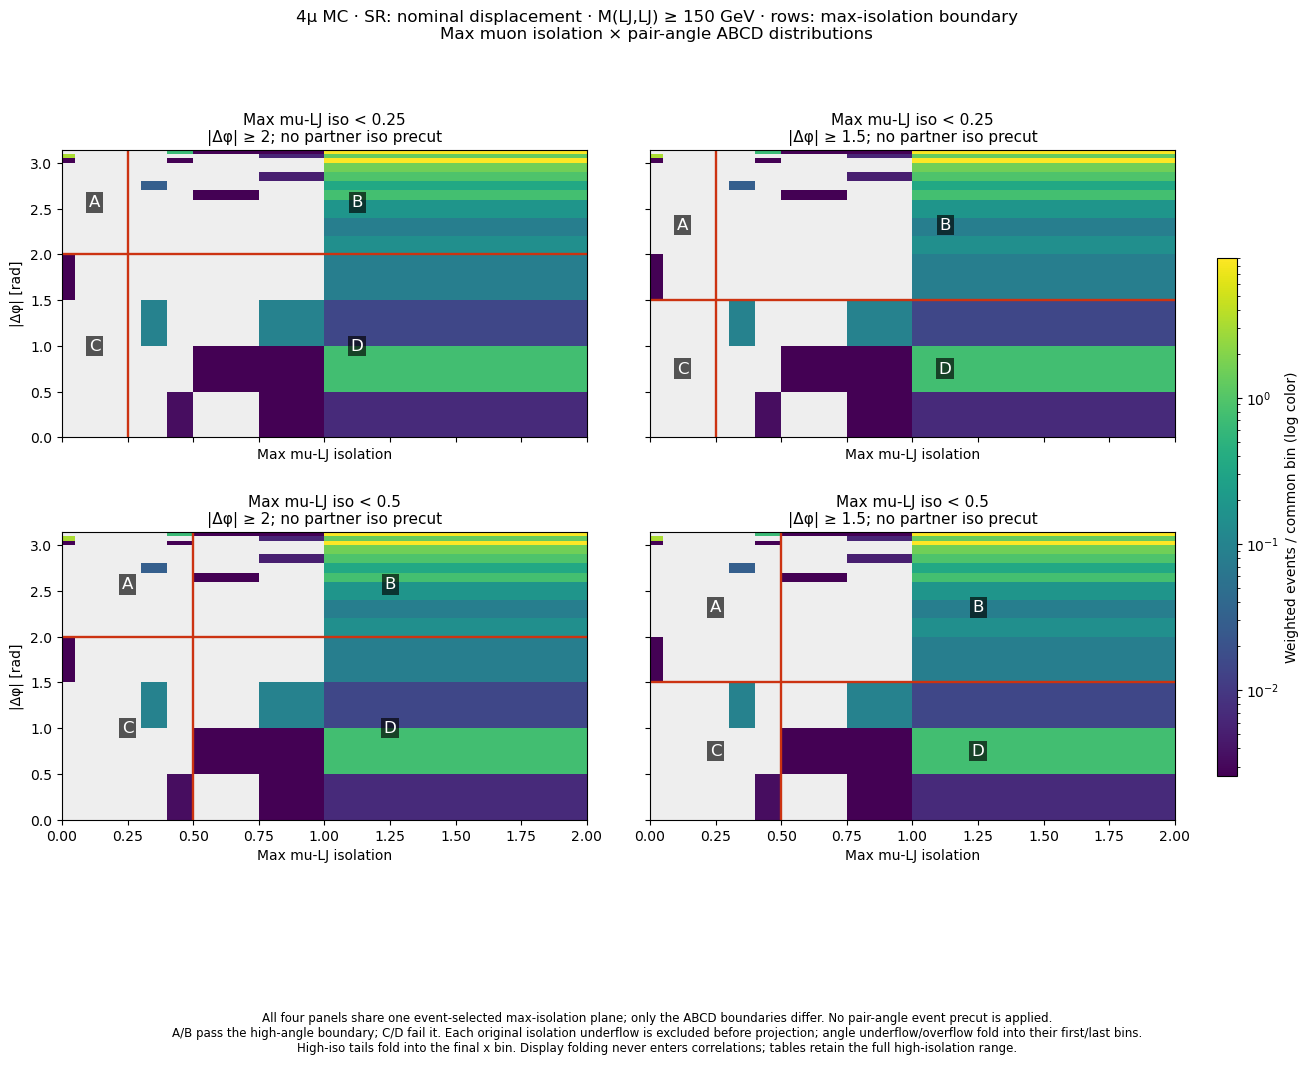

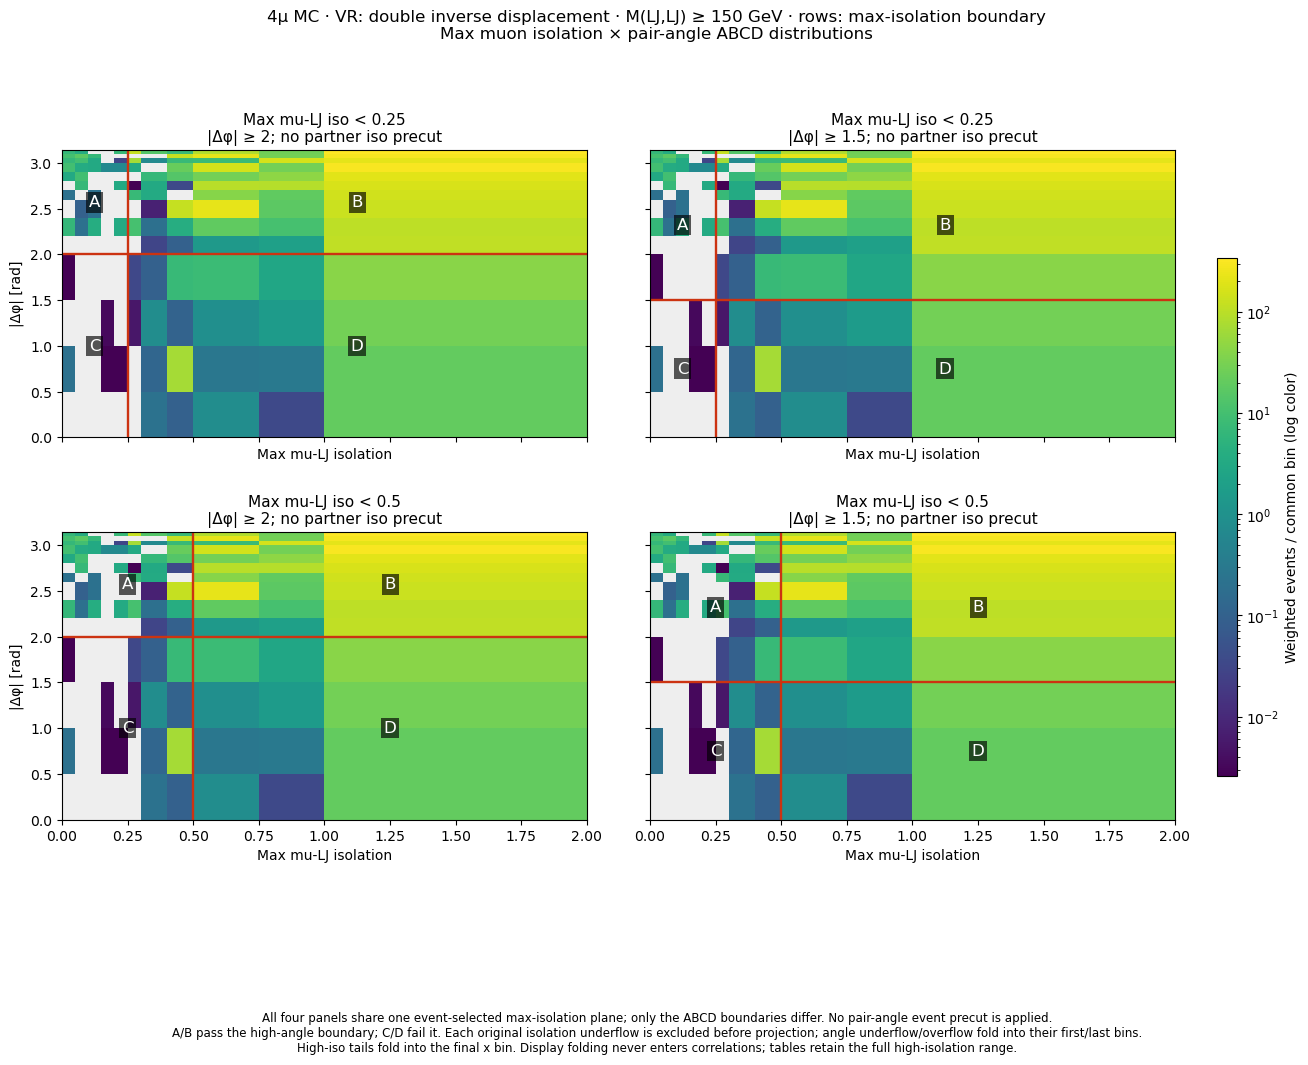

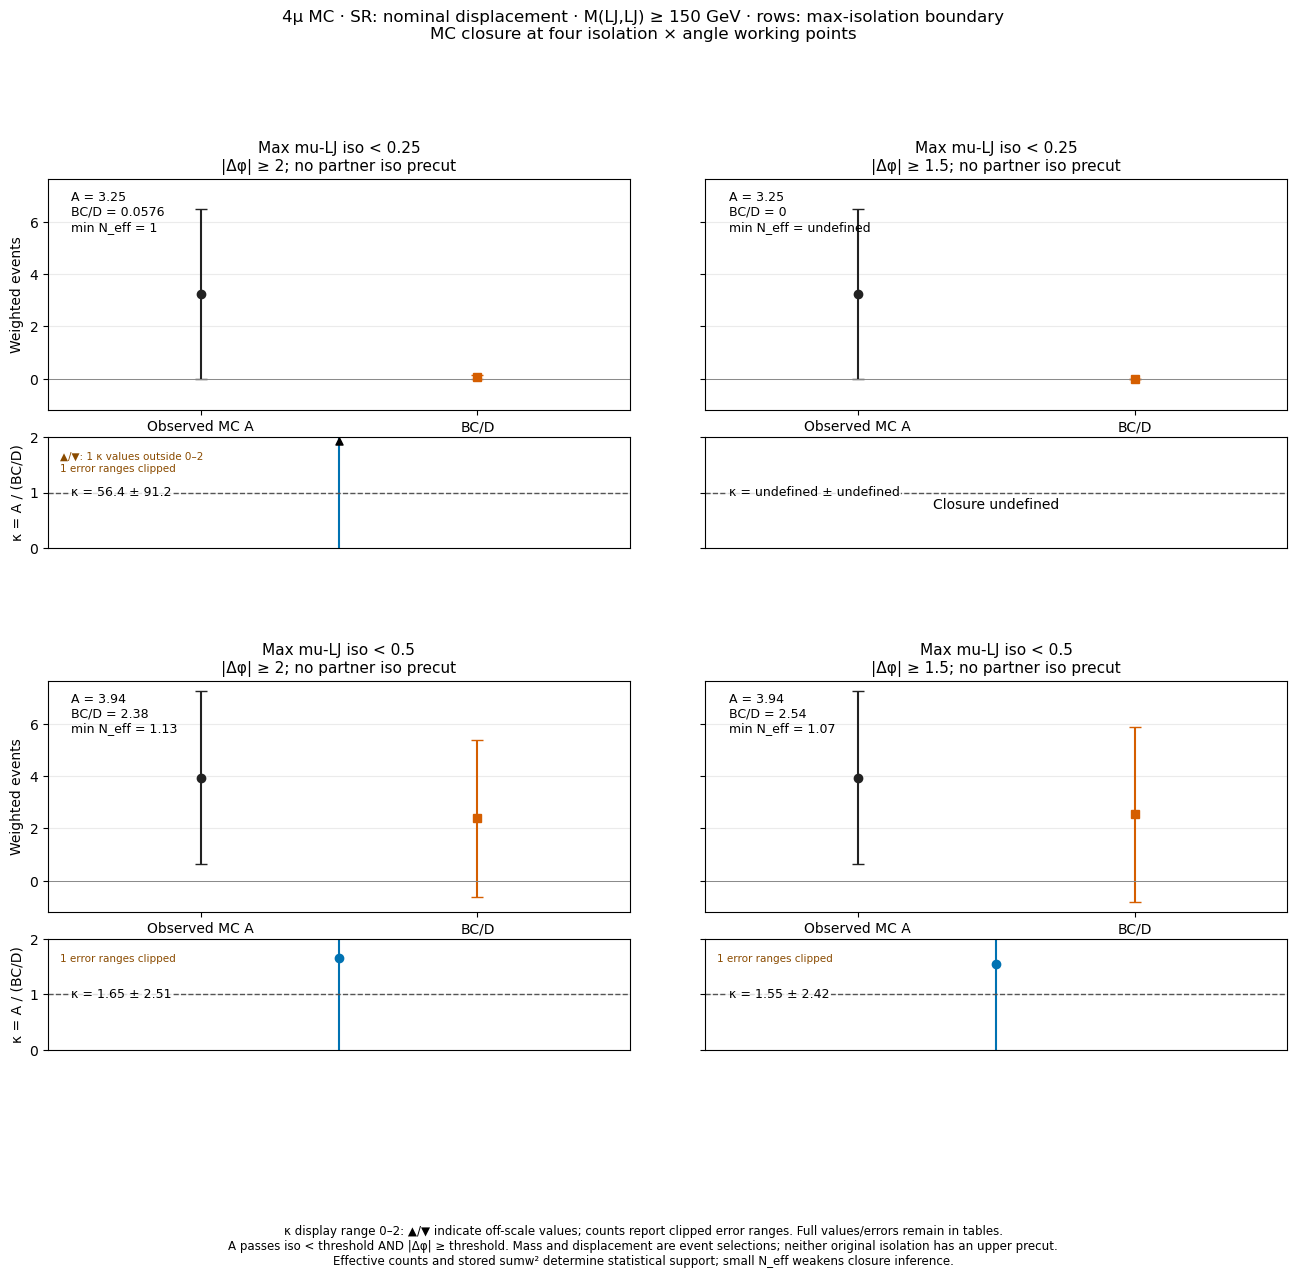

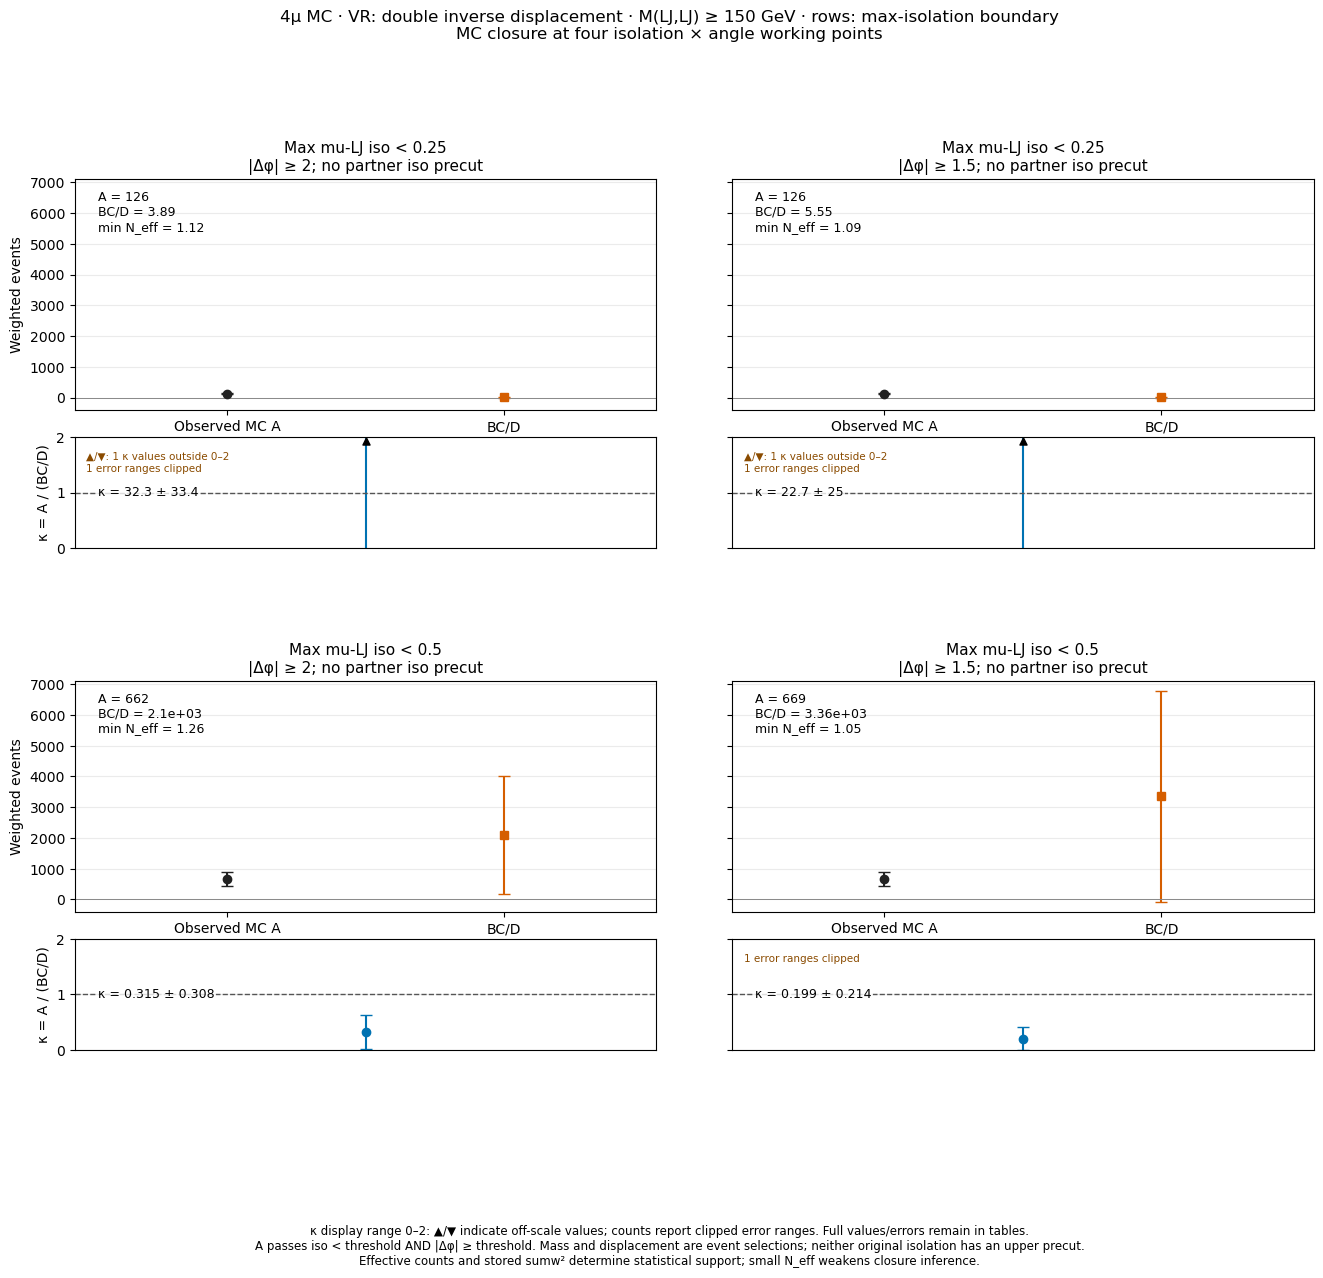

In [8]:
present_plane_figures(plot_plane_distributions(mc_results,CONFIG))
present_plane_figures(plot_plane_closure(mc_results,CONFIG))


## 전체 180 signal sample의 진단용 분포

현재 signal 파일 180개를 각각 이 노트북의 채널·선택으로 투영하고 저장된 가중치를 합친 뒤, 선택된 전체 영역에 대해 한 번 정규화한다. 두 generated topology를 모두 포함한다. 이 혼합은 진단용 시각화이며 하나의 물리 신호 가설이 아니다. S/B·leakage·DATA gate에는 네 displaced reference를 각각 사용한다.


All-grid current signal shapes: 20/180, all working-point rows and generated topologies


All-grid current signal shapes: 40/180, all working-point rows and generated topologies


All-grid current signal shapes: 60/180, all working-point rows and generated topologies


All-grid current signal shapes: 80/180, all working-point rows and generated topologies


All-grid current signal shapes: 100/180, all working-point rows and generated topologies


All-grid current signal shapes: 120/180, all working-point rows and generated topologies


All-grid current signal shapes: 140/180, all working-point rows and generated topologies


All-grid current signal shapes: 160/180, all working-point rows and generated topologies


All-grid current signal shapes: 180/180, all working-point rows and generated topologies


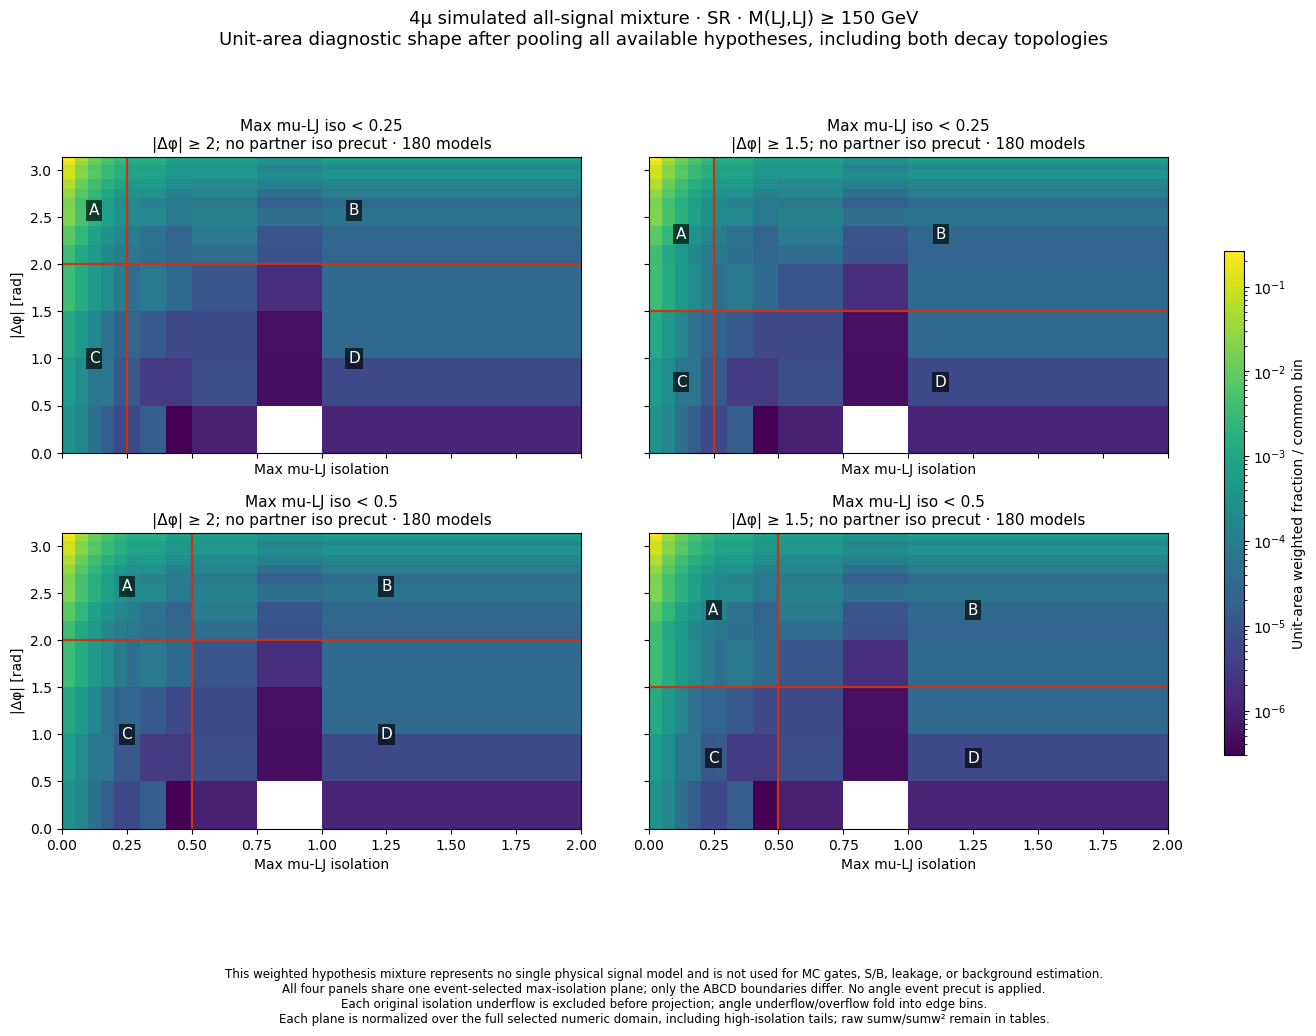

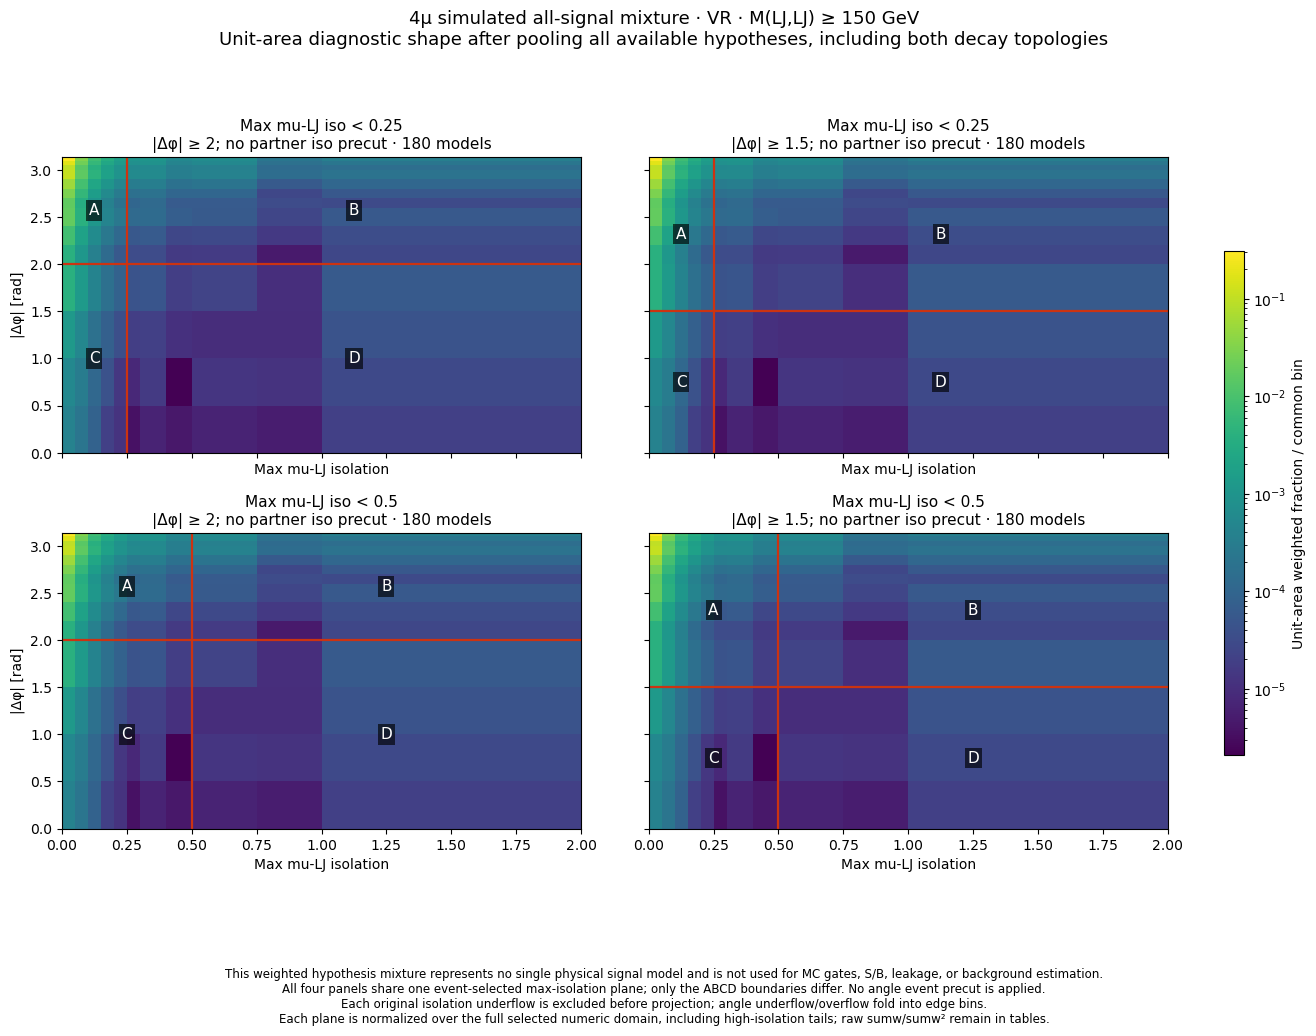

,benchmark,context,plane_kind,model_count,generated_topologies,sumw,sumw2,neff,status,source_masses,flow_policy,purpose,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,max_mu_iso,180,"2Mu2E,4Mu",510.756667,1.232484,211663.822962,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,VR,max_mu_iso,180,"2Mu2E,4Mu",2088.335581,4.922666,885931.620620,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_loose,SR,max_mu_iso,180,"2Mu2E,4Mu",510.756667,1.232484,211663.822962,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
3,p025_loose,VR,max_mu_iso,180,"2Mu2E,4Mu",2088.335581,4.922666,885931.620620,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
4,p050_tight,SR,max_mu_iso,180,"2Mu2E,4Mu",510.756667,1.232484,211663.822962,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
5,p050_tight,VR,max_mu_iso,180,"2Mu2E,4Mu",2088.335581,4.922666,885931.620620,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
6,p050_loose,SR,max_mu_iso,180,"2Mu2E,4Mu",510.756667,1.232484,211663.822962,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
7,p050_loose,VR,max_mu_iso,180,"2Mu2E,4Mu",2088.335581,4.922666,885931.620620,OK,"[100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]",Each original isolation underflow excluded; el...,Pooled diagnostic shape only; not a physical c...,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose


In [9]:
all_signal_shapes = aggregate_plane_signal_shapes(CONFIG)
mc_results["tables"].update({"all_signal_"+name: frame for name,frame in all_signal_shapes["tables"].items()})
present_plane_figures(plot_plane_all_signal_shapes(all_signal_shapes, CONFIG), source="MC")
display(all_signal_shapes["tables"]["summary"])


## 상관관계와 2D κ scan

Native regular bin의 가중 bin-centre Pearson ρ와 유효 통계를 All/A/B/C/D별로 계산한다. 상관계수에는 plane flow를 제외한다. κ grid에는 저장된 경계만 사용하며 저통계·정의 불가 지점을 유지한다.

4μ max plane은 사전 선택이 같으므로 네 grid 값이 동일하고 표시하는 anchor만 달라진다. DATA 그림은 reference gate를 통과한 지점만 수치로 표시한다.


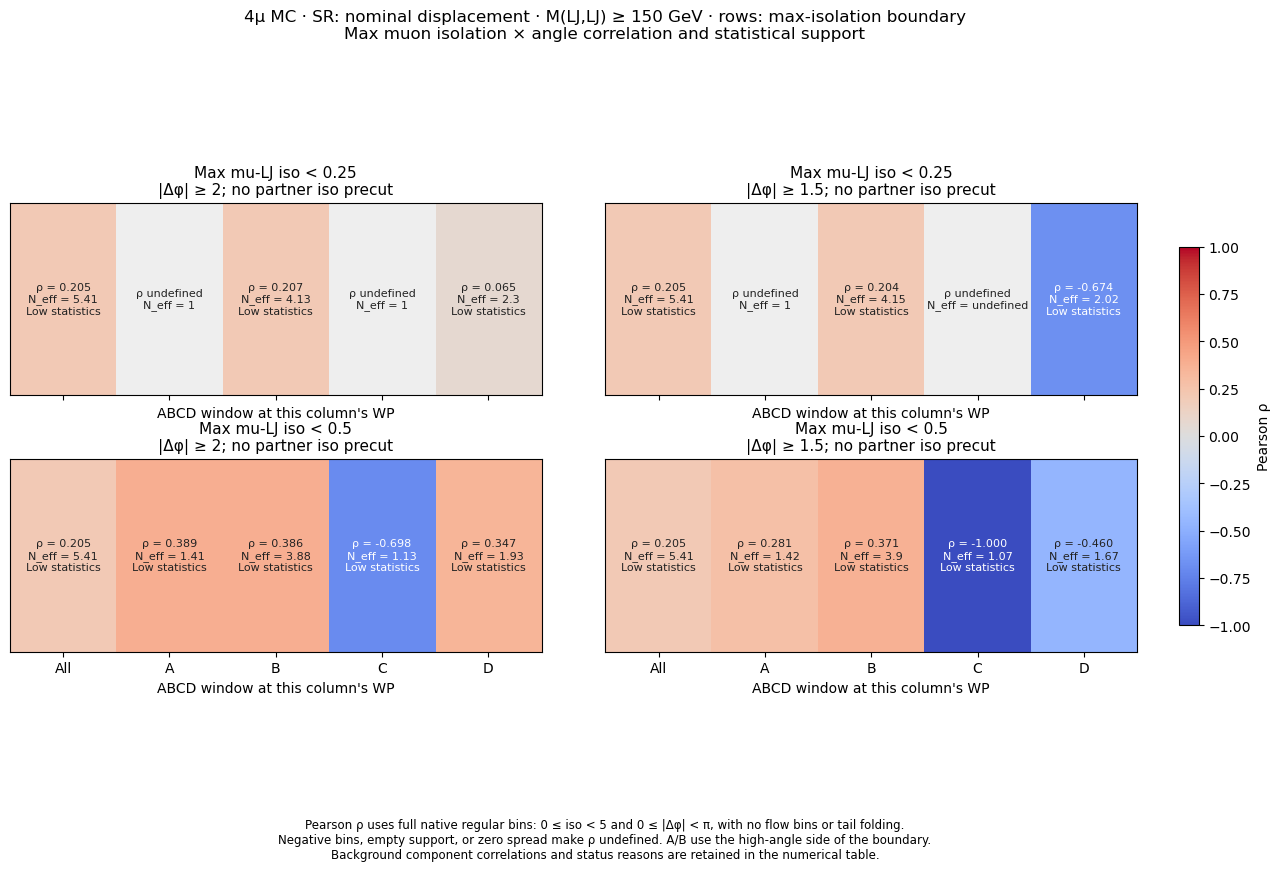

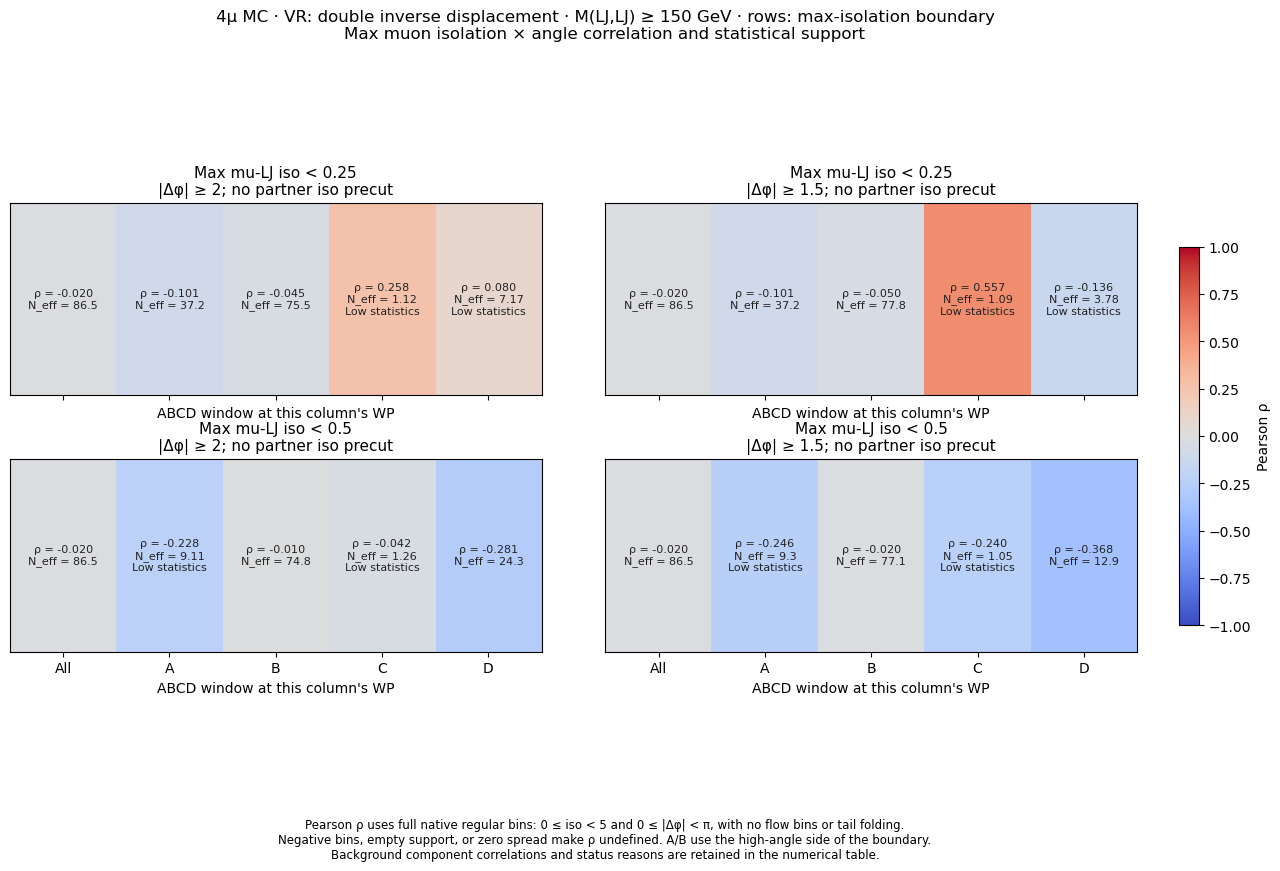

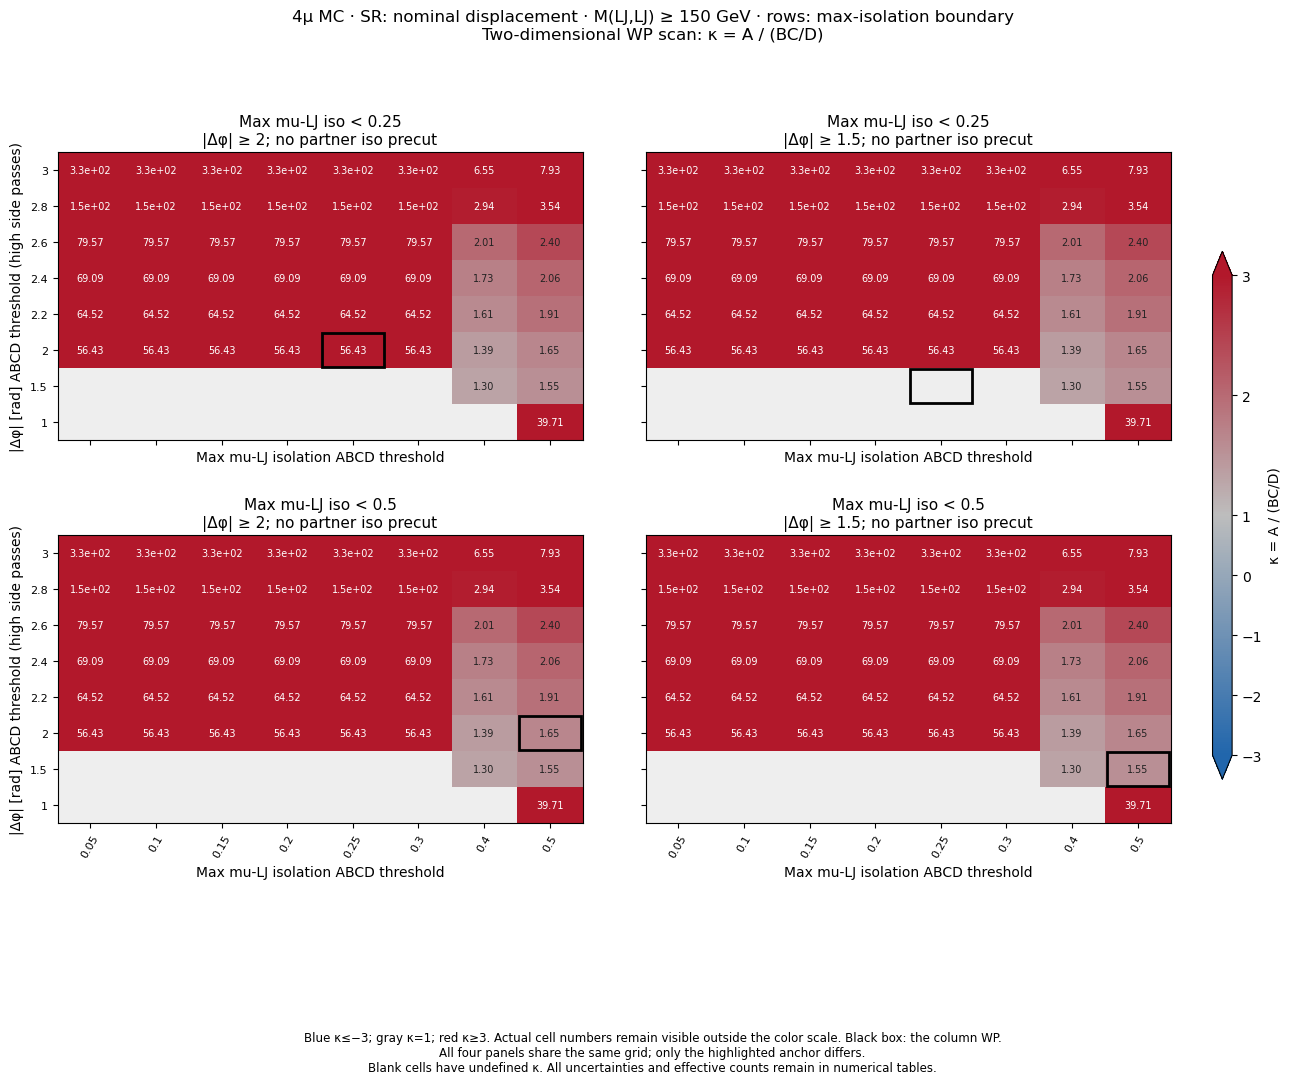

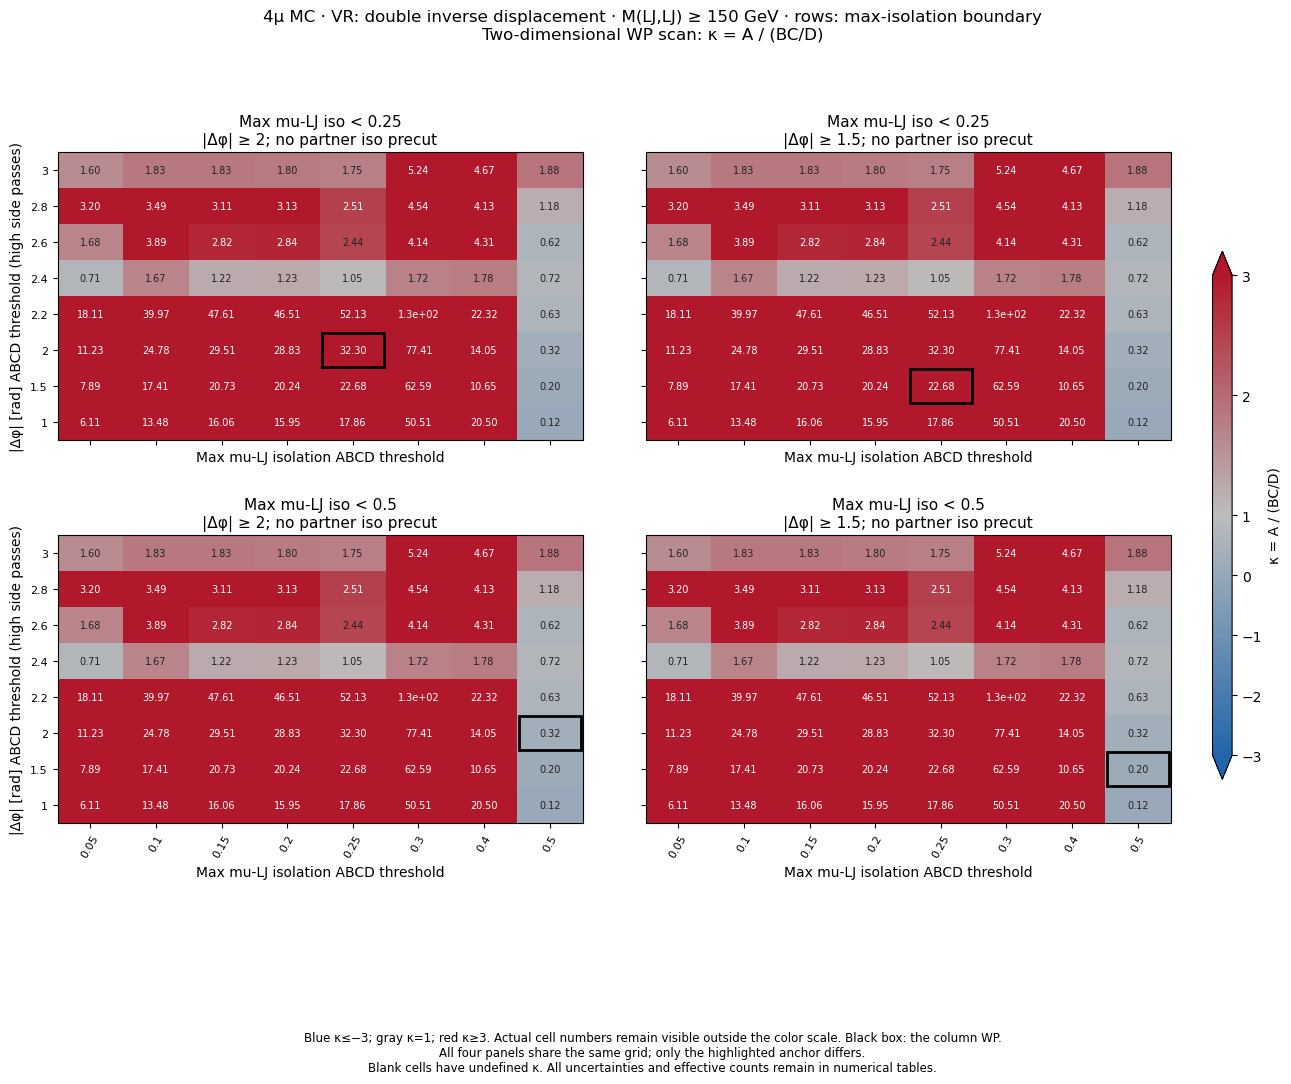

,benchmark,context,component,tx,ty,region,correlation,rho,neff,status,...,display_binning,support,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,Total,0.25,2.0,All,0.205276,0.205276,5.408777,LOW_STAT,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,SR,Total,0.25,2.0,A,NaN,NaN,1.001583,NO_SPREAD,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_tight,SR,Total,0.25,2.0,B,0.207192,0.207192,4.125853,LOW_STAT,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
3,p025_tight,SR,Total,0.25,2.0,C,NaN,NaN,1.000000,NO_SPREAD,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
4,p025_tight,SR,Total,0.25,2.0,D,0.064543,0.064543,2.304759,LOW_STAT,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,p050_loose,VR,Diboson,0.50,1.5,All,0.164936,0.164936,11.994408,OK,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
196,p050_loose,VR,Diboson,0.50,1.5,A,-0.116526,-0.116526,10.994590,OK,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
197,p050_loose,VR,Diboson,0.50,1.5,B,NaN,NaN,NaN,EMPTY,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
198,p050_loose,VR,Diboson,0.50,1.5,C,-1.000000,-1.000000,1.000000,LOW_STAT,...,"{""xedges"": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0...",Native regular-bin support only; both plane fl...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose


In [10]:
present_plane_figures(plot_plane_correlations(mc_results,CONFIG))
present_plane_figures(plot_plane_kappa_grid(mc_results,CONFIG))
display(tables["correlation_summary"])


## 한 축씩 scan 및 신호 진단

각 패널의 anchor에서 다른 축 경계를 고정하고 isolation 또는 |Δφ|를 scan한다. 고정된 plane 경계는 이벤트 사전 cut이 아니므로 양쪽 sideband를 유지한다. 네 reference의 S/B와 leakage를 각각 표시한다. 통계가 부족하거나 gate를 통과하지 못한 지점도 상태로 남긴다.


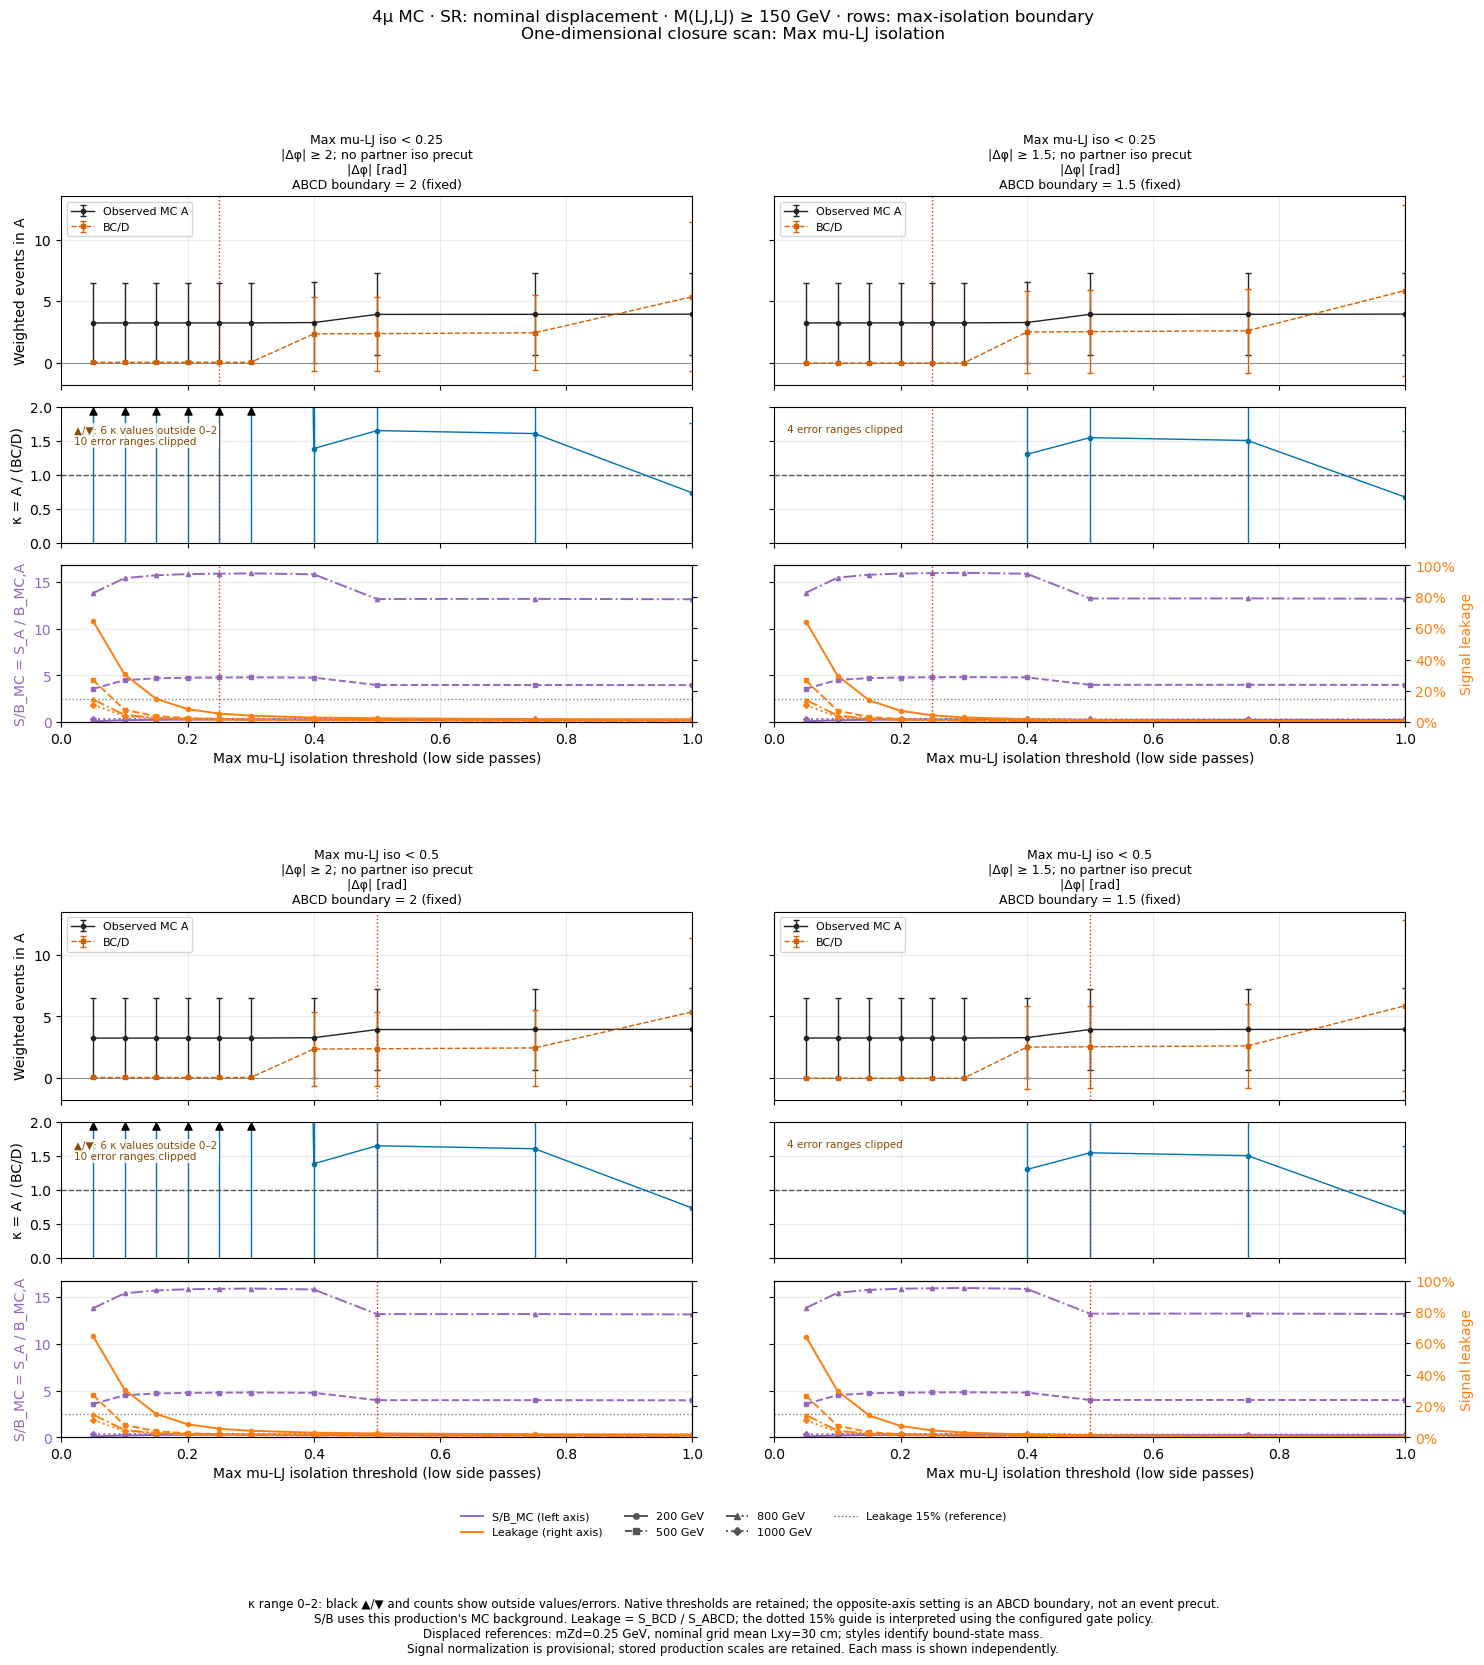

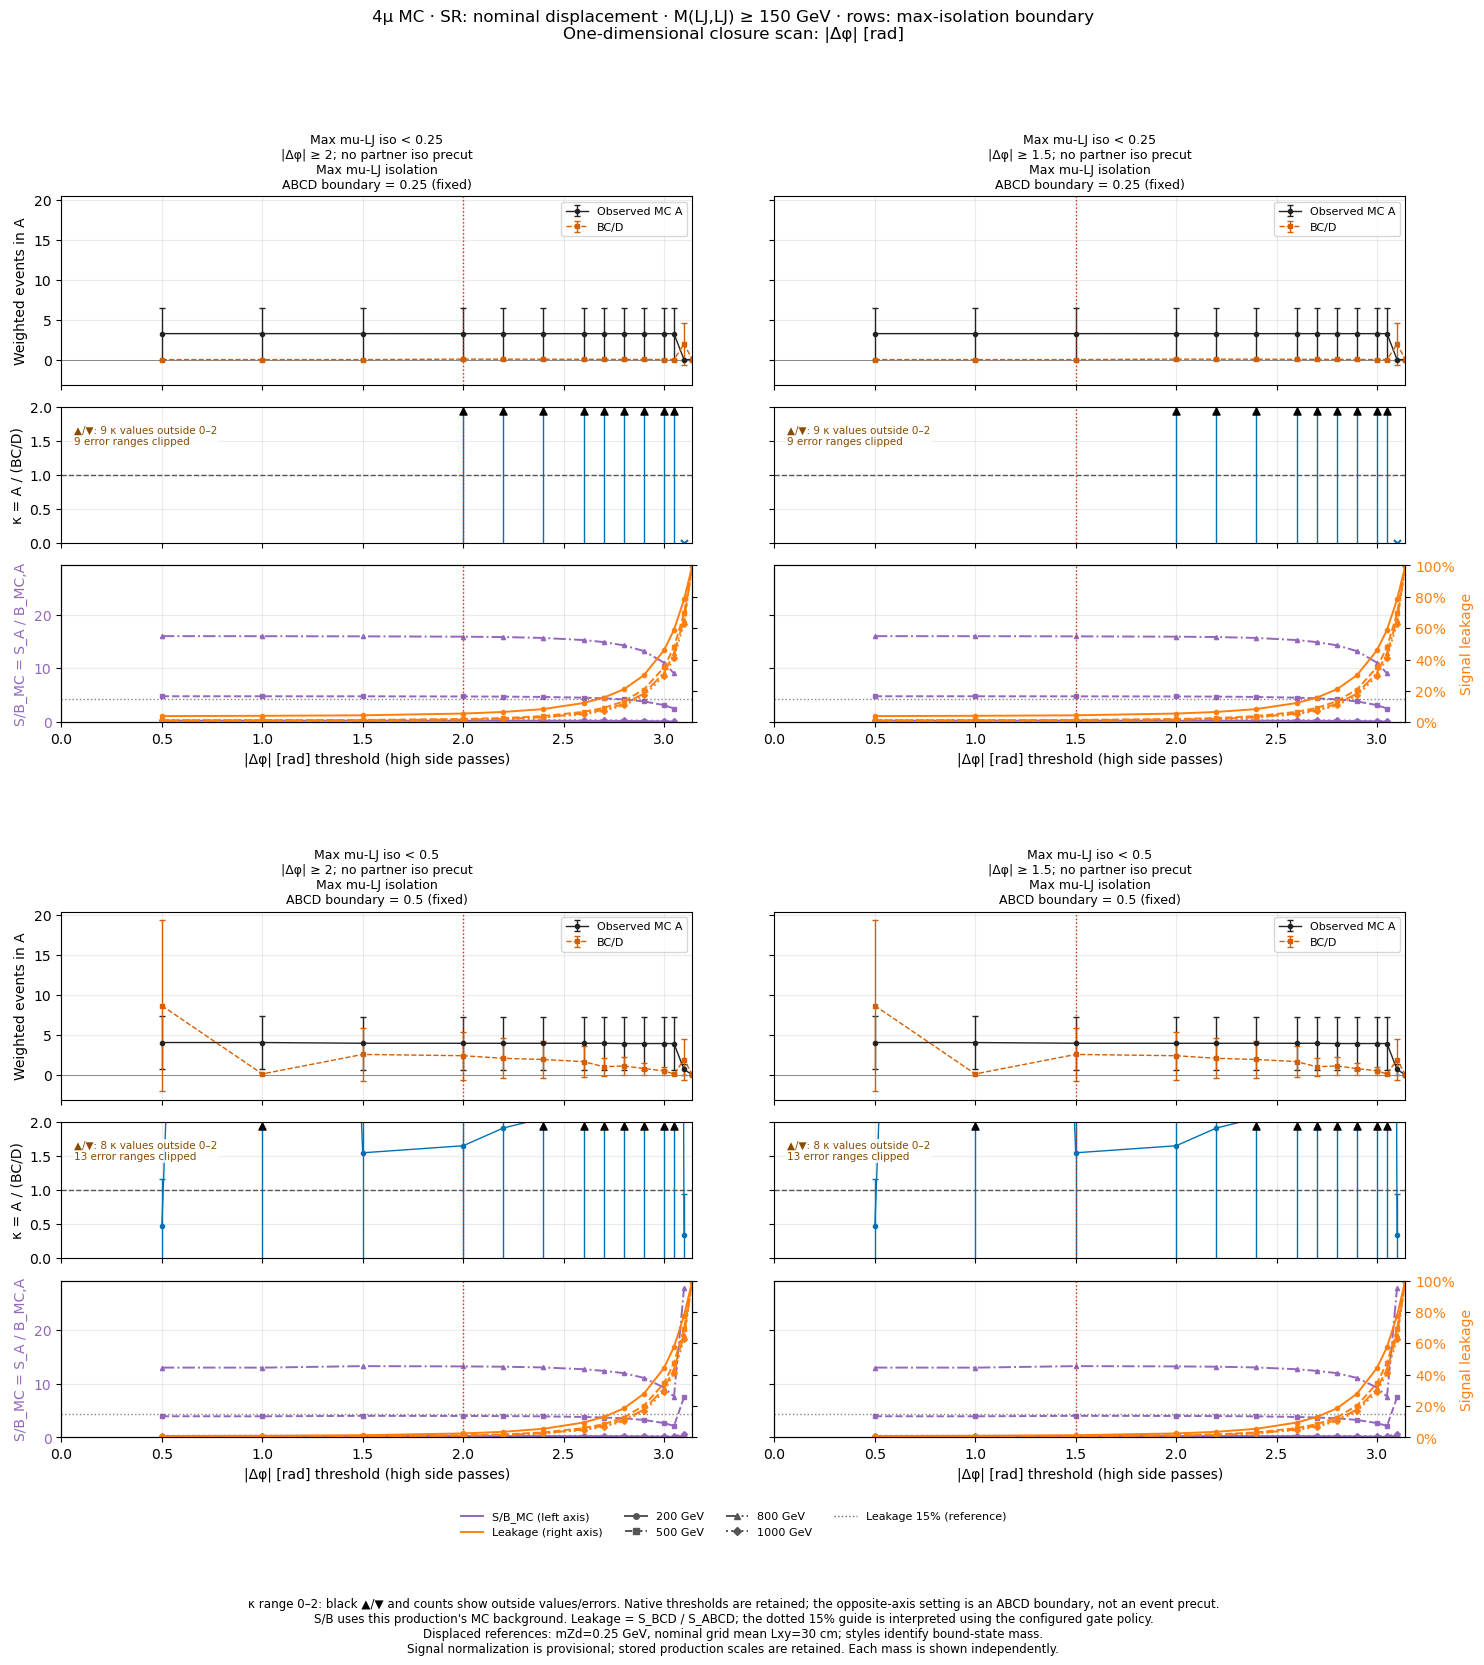

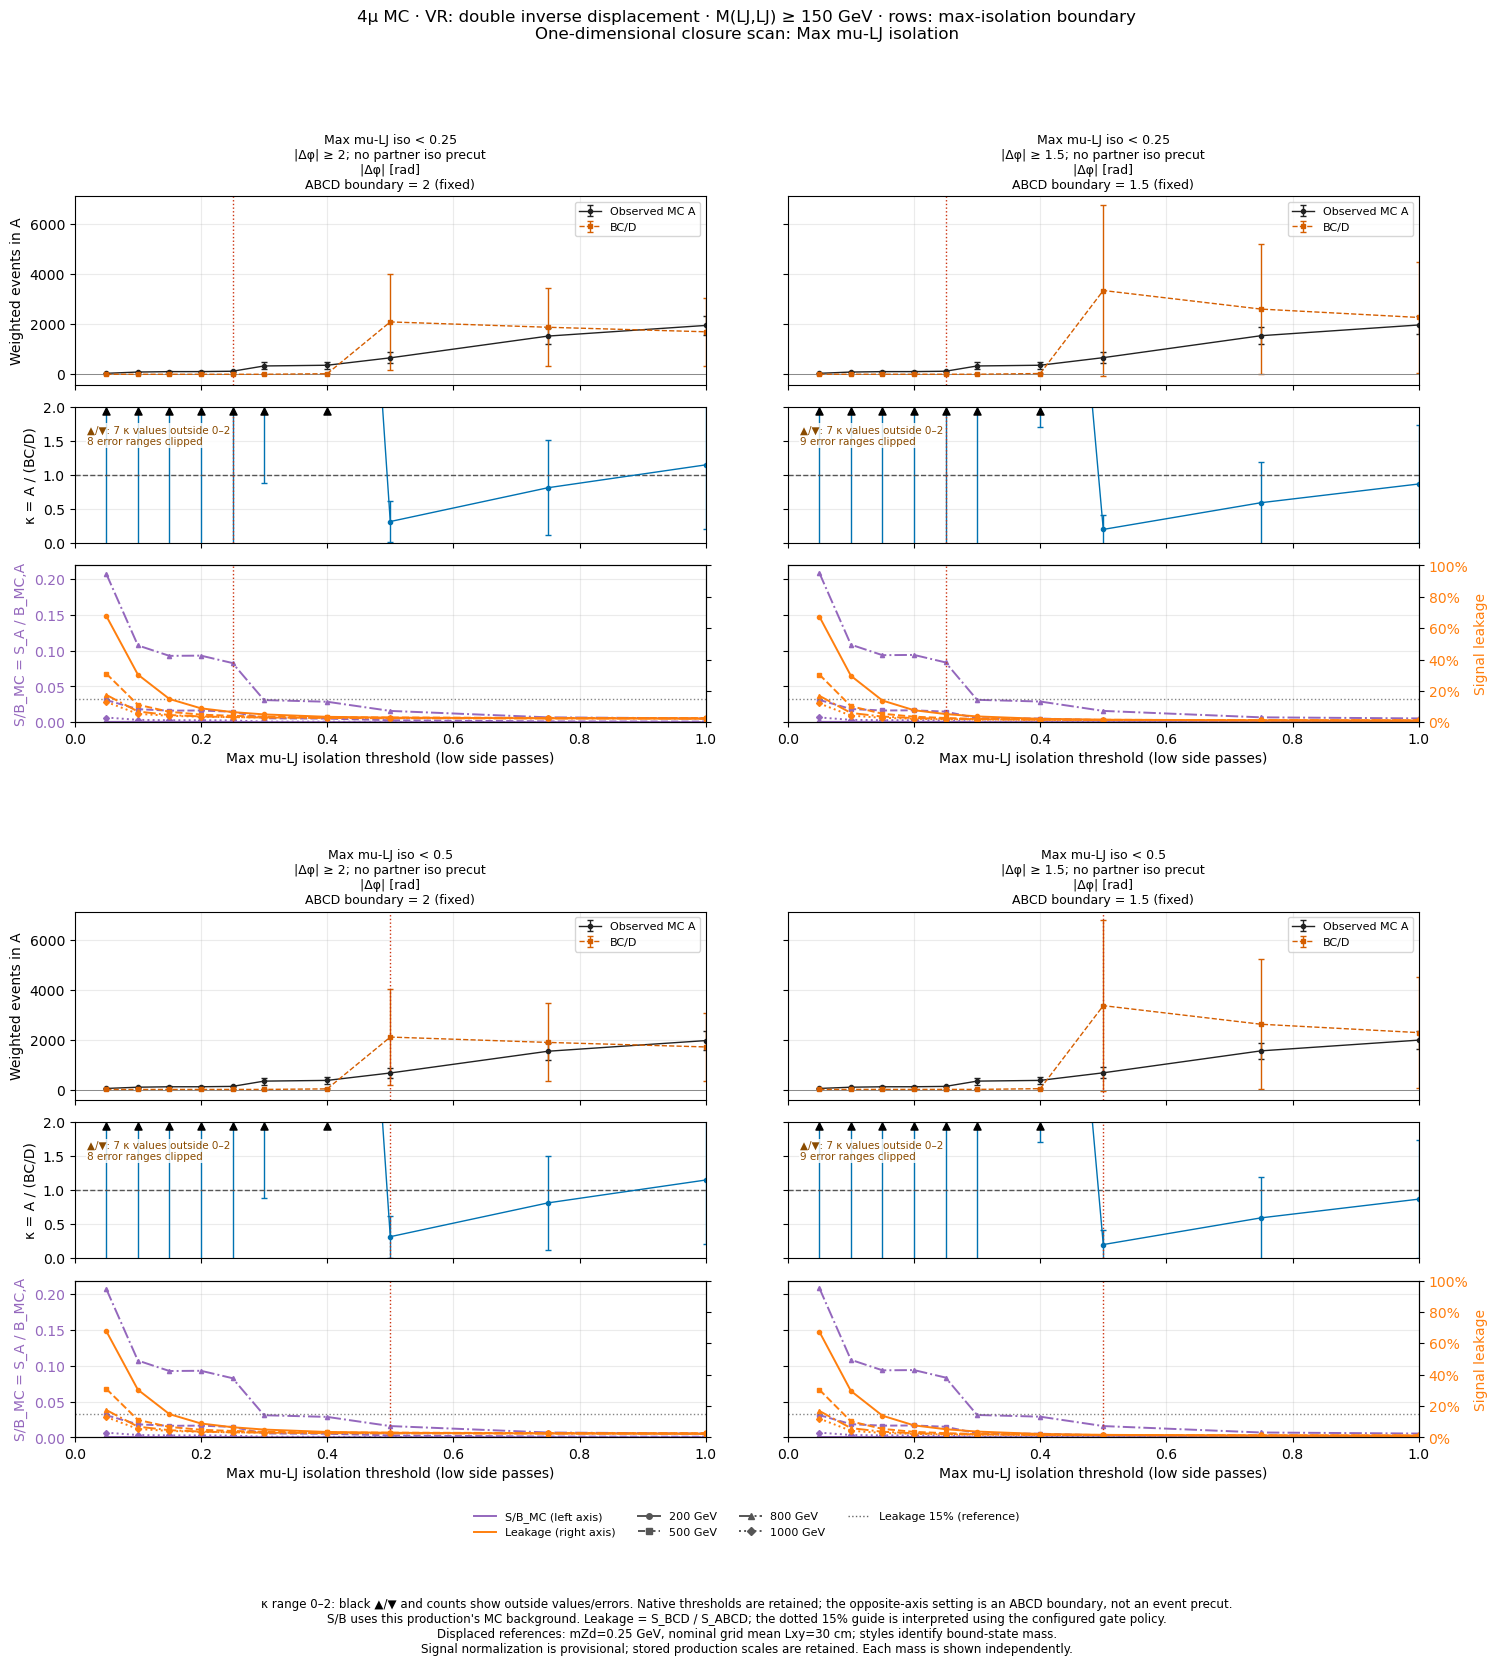

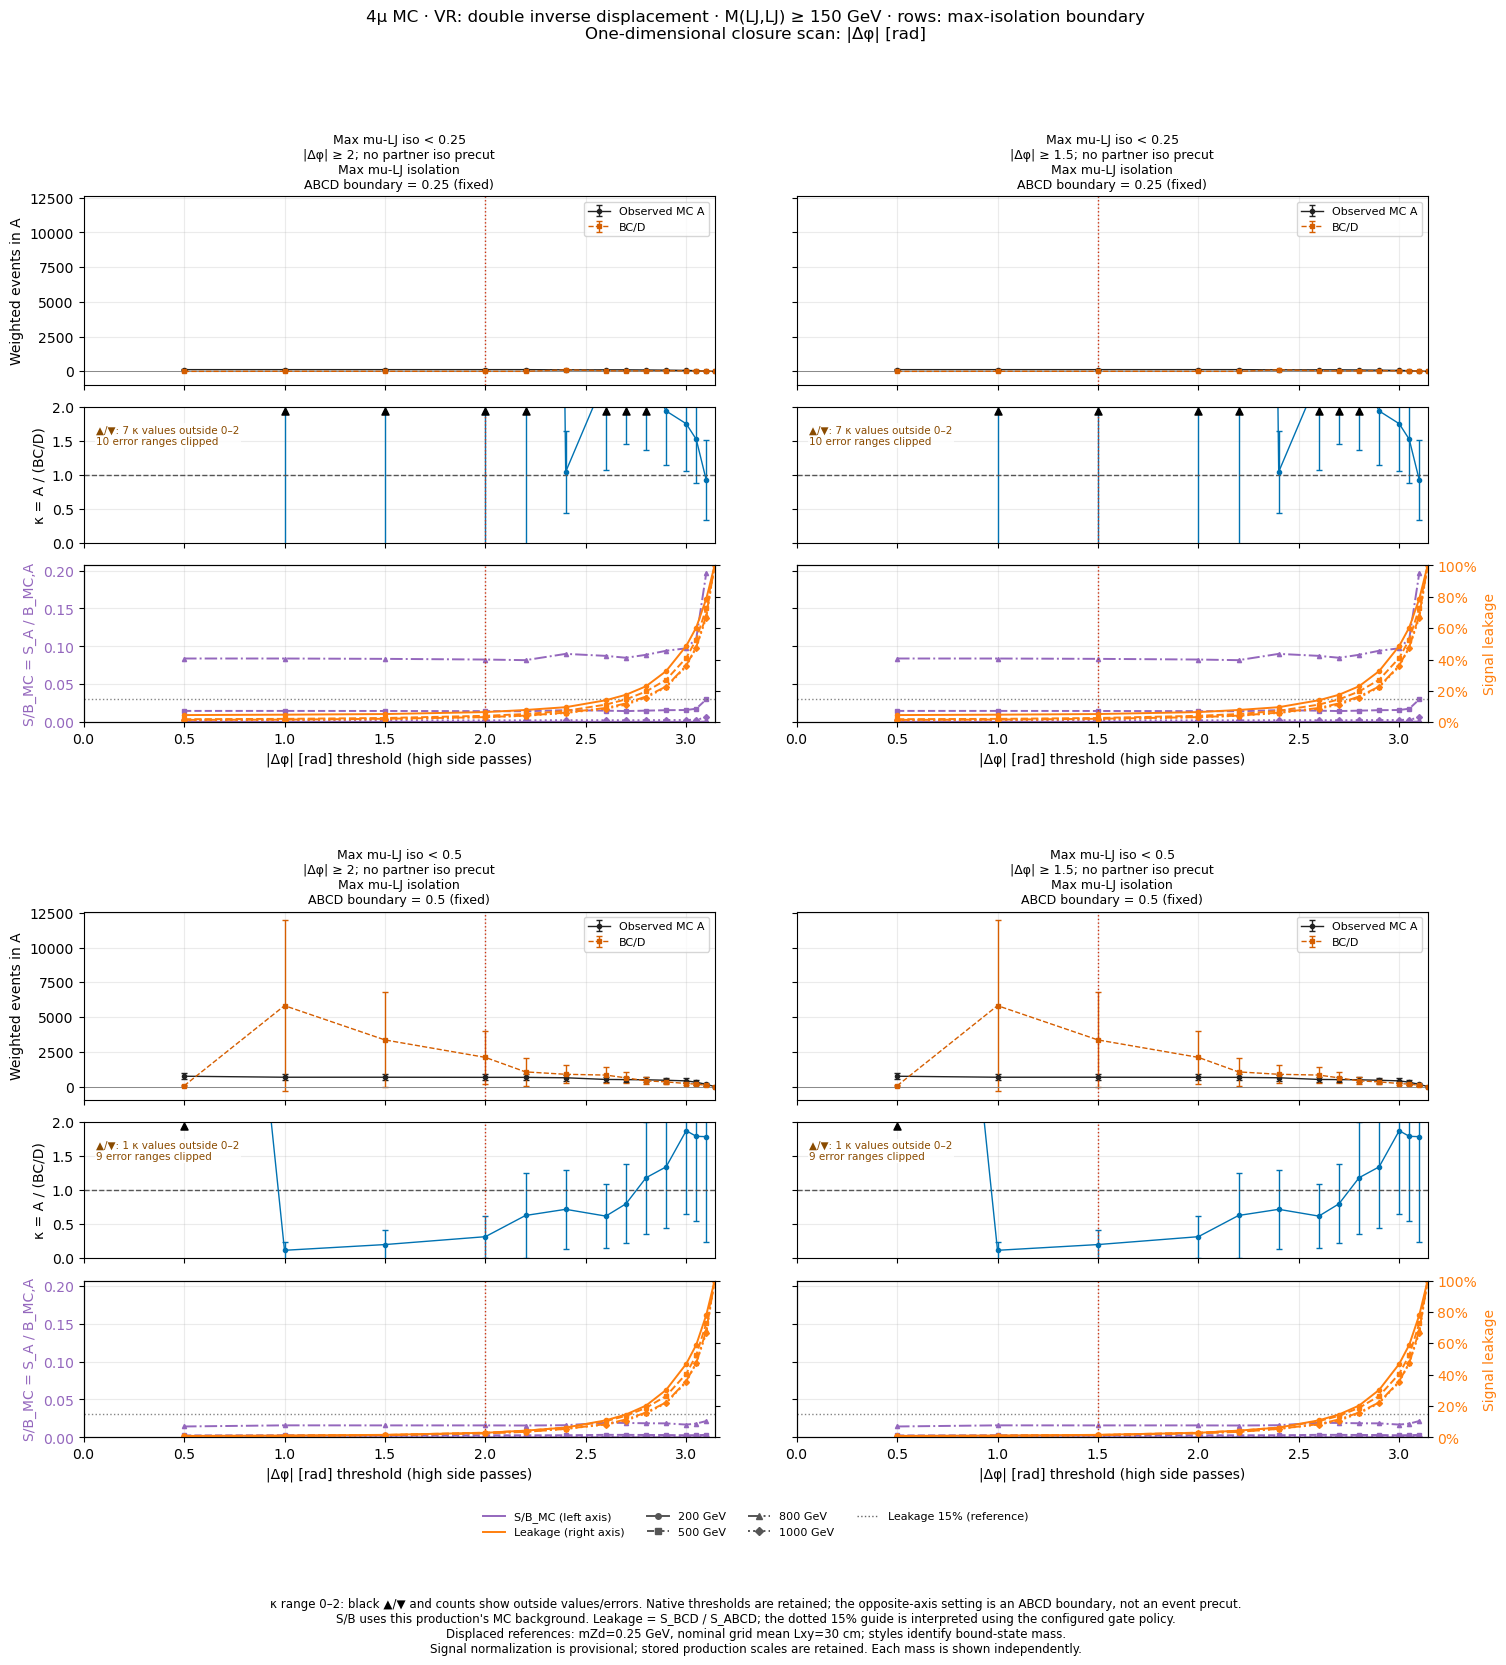

,benchmark,context,reference_role,role,sample,mA_GeV,mZd_GeV,ctau_mm,reference_kind,avg_transverse_cm,...,signal_normalization_verified,policy,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,mA200,mA200,4Mu_200GeV_0p25GeV_1p0mm,200.0,0.25,1.00,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,SR,mA500,mA500,4Mu_500GeV_0p25GeV_0p4mm,500.0,0.25,0.40,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_tight,SR,mA800,mA800,4Mu_800GeV_0p25GeV_0p25mm,800.0,0.25,0.25,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
3,p025_tight,SR,mA1000,mA1000,4Mu_1000GeV_0p25GeV_0p2mm,1000.0,0.25,0.20,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
4,p025_tight,VR,mA200,mA200,4Mu_200GeV_0p25GeV_1p0mm,200.0,0.25,1.00,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
5,p025_tight,VR,mA500,mA500,4Mu_500GeV_0p25GeV_0p4mm,500.0,0.25,0.40,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
6,p025_tight,VR,mA800,mA800,4Mu_800GeV_0p25GeV_0p25mm,800.0,0.25,0.25,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
7,p025_tight,VR,mA1000,mA1000,4Mu_1000GeV_0p25GeV_0p2mm,1000.0,0.25,0.20,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
8,p025_loose,SR,mA200,mA200,4Mu_200GeV_0p25GeV_1p0mm,200.0,0.25,1.00,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
9,p025_loose,SR,mA500,mA500,4Mu_500GeV_0p25GeV_0p4mm,500.0,0.25,0.40,displaced,30.0,...,False,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose


In [11]:
present_plane_figures(plot_plane_one_d(mc_results,CONFIG))
display(tables["signal_diagnostics"])


## 배경 조성과 유효 통계

네 조합에서 QCD/DY/TTJets/Diboson의 A/B/C/D yield와 Neff를 비교한다. 저통계 상태는 reference gate 통과 여부와 별도로 해석한다.


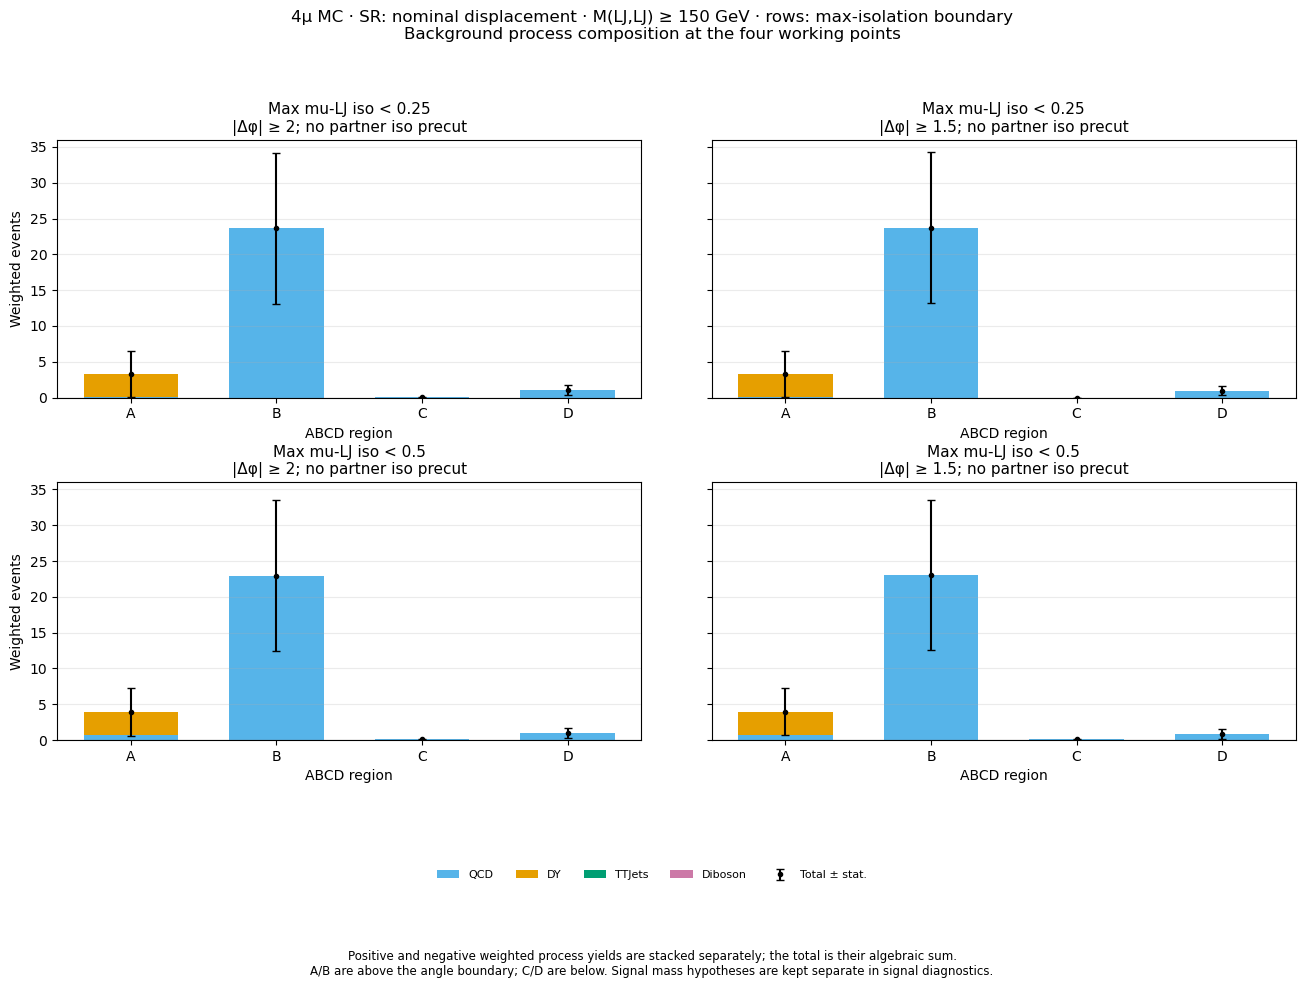

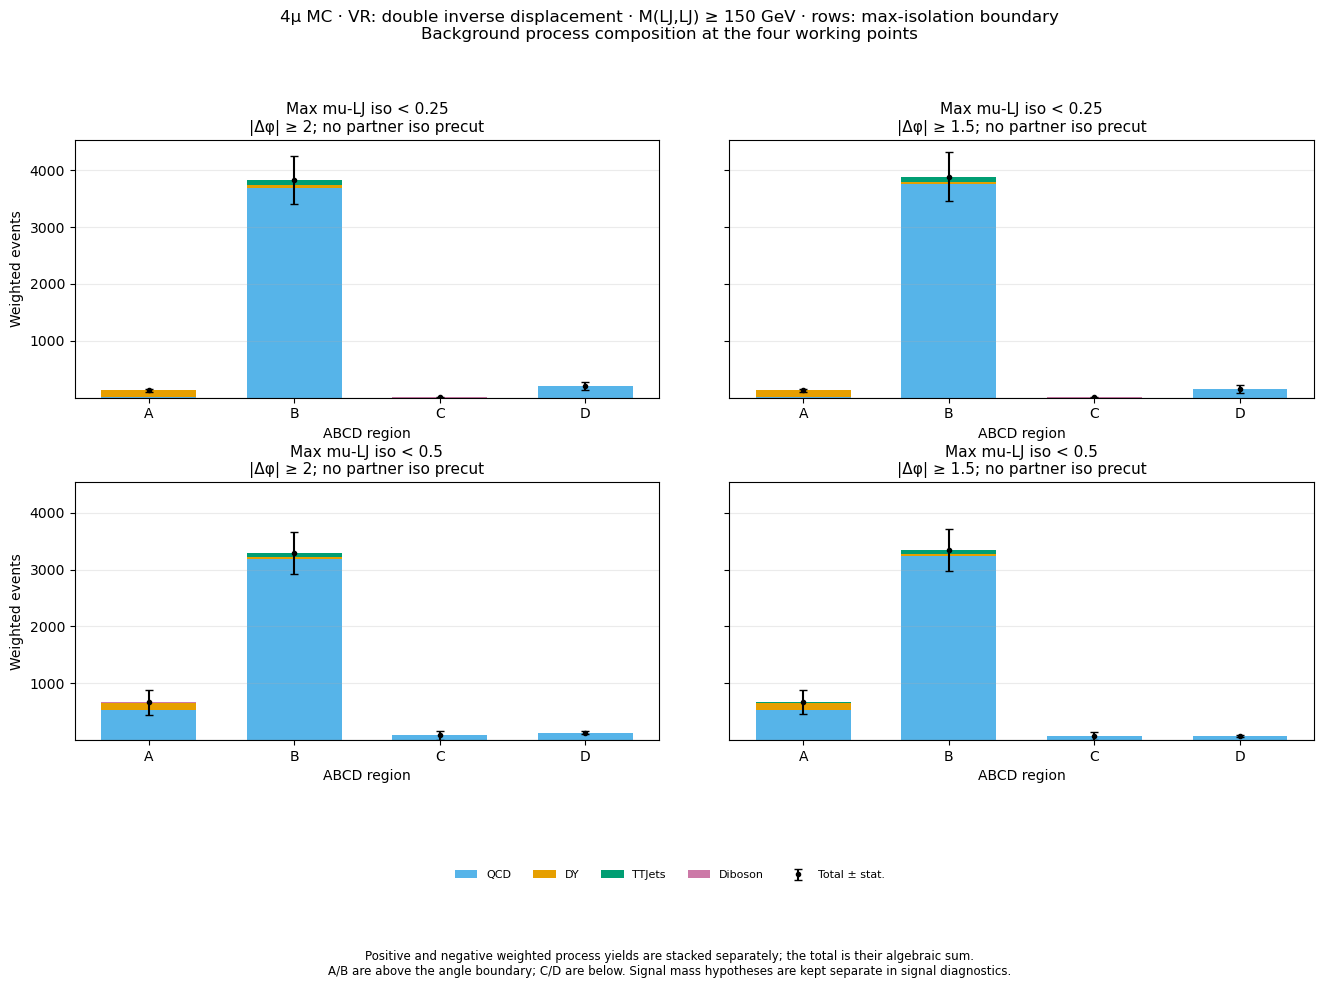

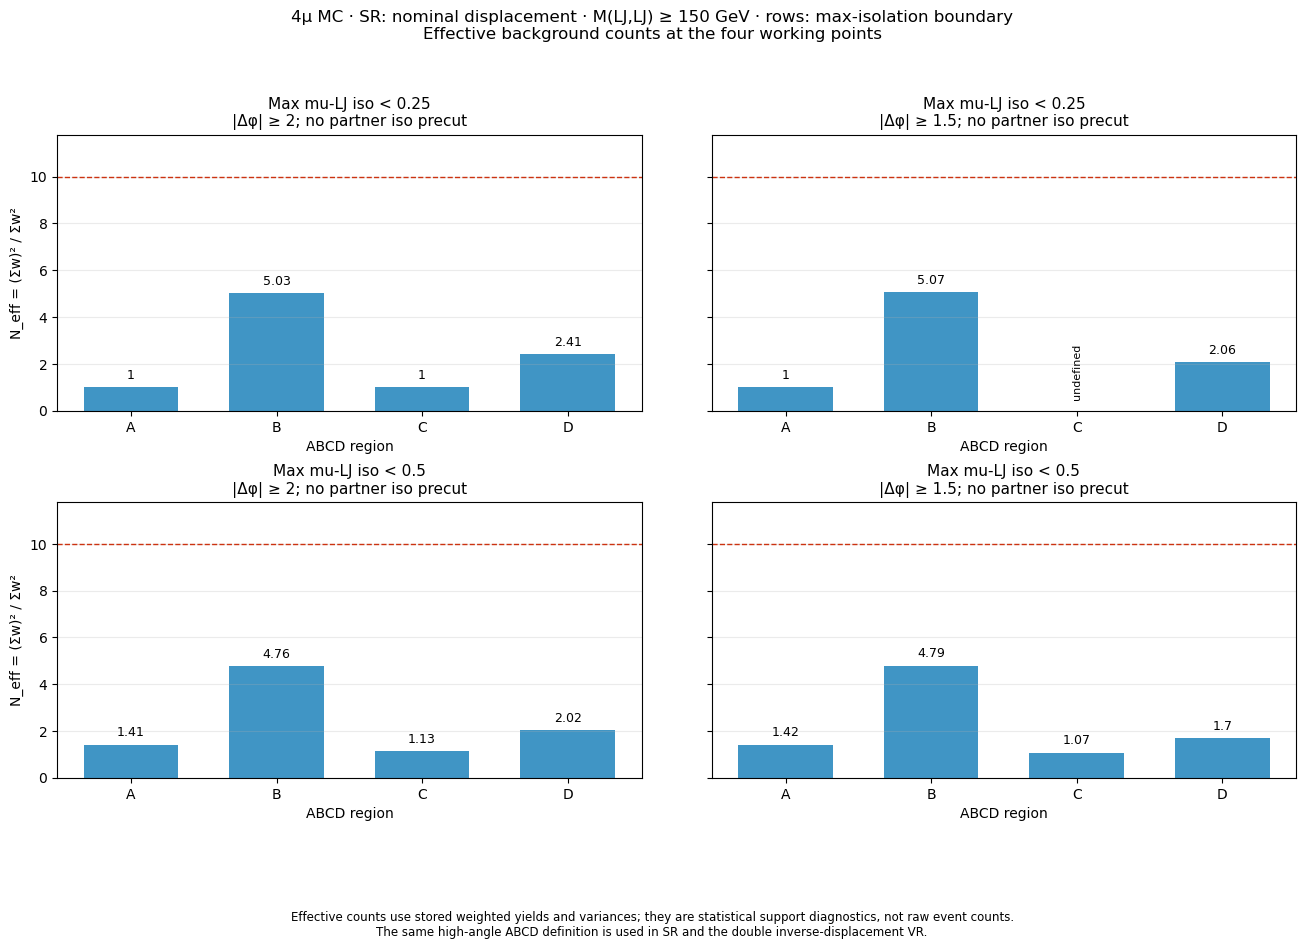

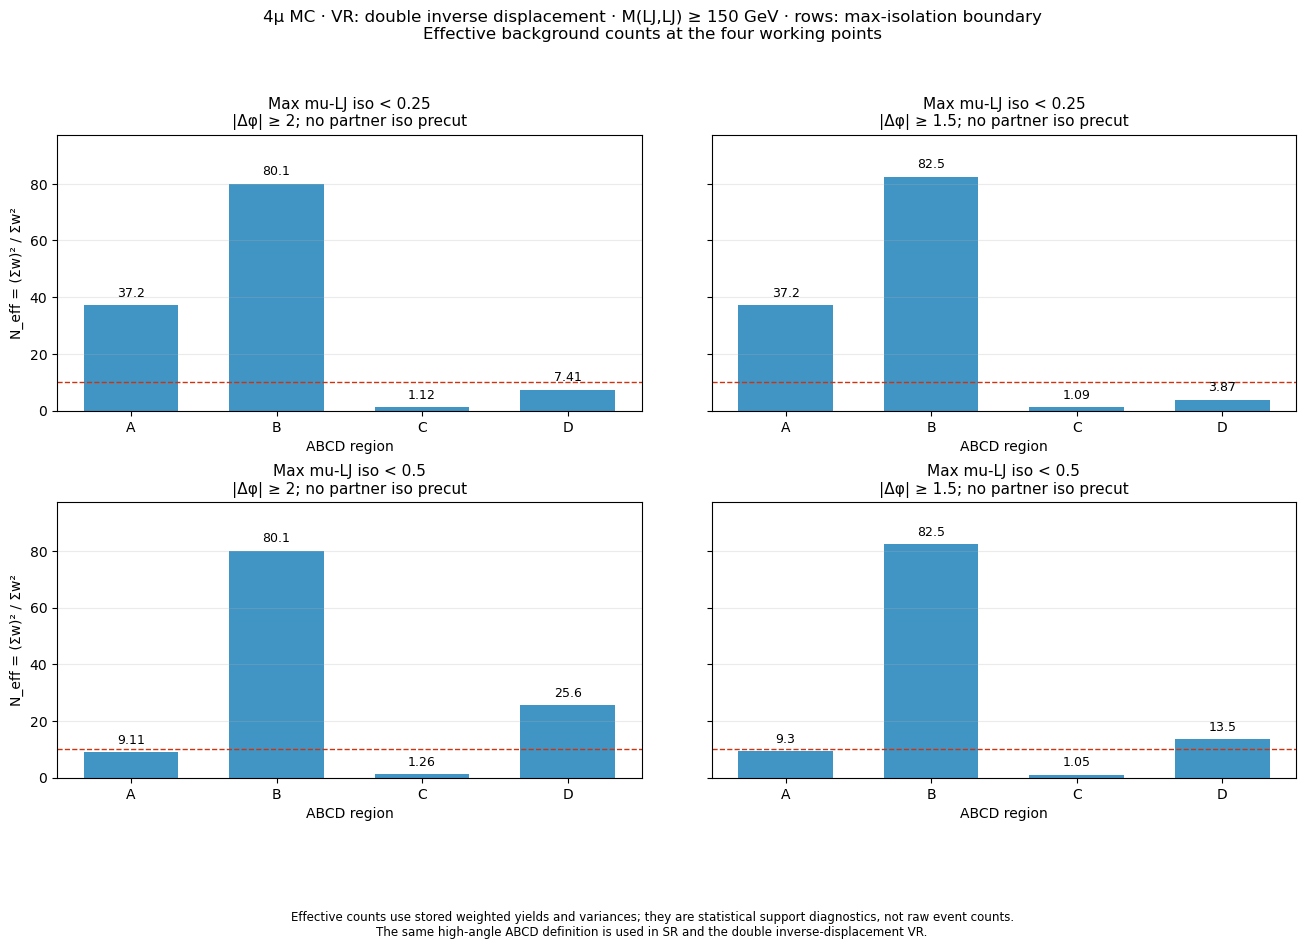

,benchmark,context,component,region,yield,variance,error,neff,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,SR,Total,A,3.250611,10.549767,3.248041,1.001583,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,SR,Total,B,23.636630,111.050330,10.538042,5.030965,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_tight,SR,Total,C,0.002571,0.000007,0.002571,1.000000,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
3,p025_tight,SR,Total,D,1.054875,0.462056,0.679747,2.408282,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
4,p025_tight,SR,QCD,A,0.002571,0.000007,0.002571,1.000000,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,p050_loose,VR,TTJets,D,0.000000,0.000000,0.000000,NaN,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
156,p050_loose,VR,Diboson,A,2.194331,0.437951,0.661778,10.994590,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
157,p050_loose,VR,Diboson,B,0.196775,0.038720,0.196775,1.000000,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose
158,p050_loose,VR,Diboson,C,0.196775,0.038720,0.196775,1.000000,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose


In [12]:
present_plane_figures(plot_plane_composition(mc_results,CONFIG))
present_plane_figures(plot_plane_neff(mc_results,CONFIG))
display(tables["region_yields"])


## 조건부 DATA VR 검증

MC에서 새로 계산한 네 displaced reference가 각각 SR leakage<0.15를 만족한 지점만 VR DATA를 평가한다. S/(S+B_MC)는 진단값이며 현재 leakage mode의 veto는 아니다. SR DATA는 투영하거나 적분하지 않는다.

Gate 차단, DATA 미로드, 예측 정의 불가, 낮은 유효 통계, 그림 범위 밖의 값을 구분한다. 그림을 위해 새 경계를 추가하거나 조건을 완화하지 않는다.


In [13]:
data_results = run_plane_data(mc_results,dict(CONFIG,run_data=RUN_DATA))
data_tables = data_results["tables"]
DATA_CONFIG = dict(CONFIG,source_label="DATA")
with pd.option_context("display.max_columns",None,"display.max_colwidth",100):
    for name in ("data_access","closure_summary","data_scan_status"):
        if name in data_tables:
            display(data_tables[name])


Current DATA VR: 20/68 after the four-reference MC gate


Current DATA VR: 40/68 after the four-reference MC gate


Current DATA VR: 60/68 after the four-reference MC gate


Current DATA VR: 68/68 after the four-reference MC gate
DATA VR scan p025_tight/x: 10 native points; {'AVAILABLE': 8, 'GATE_BLOCKED': 2}
DATA VR scan p025_tight/y: 14 native points; {'GATE_BLOCKED': 7, 'AVAILABLE': 5, 'AVAILABLE_LOW_STAT': 2}
DATA VR scan p025_loose/x: 10 native points; {'AVAILABLE': 7, 'GATE_BLOCKED': 2, 'AVAILABLE_LOW_STAT': 1}
DATA VR scan p025_loose/y: 14 native points; {'GATE_BLOCKED': 7, 'AVAILABLE': 5, 'AVAILABLE_LOW_STAT': 2}
DATA VR scan p050_tight/x: 10 native points; {'AVAILABLE': 8, 'GATE_BLOCKED': 2}
DATA VR scan p050_tight/y: 14 native points; {'AVAILABLE': 6, 'GATE_BLOCKED': 6, 'AVAILABLE_LOW_STAT': 2}
DATA VR scan p050_loose/x: 10 native points; {'AVAILABLE': 7, 'GATE_BLOCKED': 2, 'AVAILABLE_LOW_STAT': 1}
DATA VR scan p050_loose/y: 14 native points; {'AVAILABLE': 6, 'GATE_BLOCKED': 6, 'AVAILABLE_LOW_STAT': 2}


,source,data_payloads_opened,approved_points,data_context,permitted_row_profiles,signal_normalization_verified,policy,gate_mode,leakage_limit,leakage_contexts,plane_kind,row_meaning,row_iso_values
0,current6d,68,146,VR only,"[""p025"", ""p050""]",False,Each displaced reference: Signal leakage < 15% in SR (strict),leakage,0.15,"[""SR""]",max_mu_iso,max_iso_boundary,"{""p025"": 0.25, ""p050"": 0.5}"


,benchmark,context,tx,ty,pred,pred_error,kappa,kappa_error,pull,status,kappa_status,A,var_A,A_error,neff_A,B,var_B,B_error,neff_B,C,var_C,C_error,neff_C,D,var_D,D_error,neff_D,neff_min,min_neff,min_sideband_neff,low_stat,anchor,approved,gate_passed,gate_reason,gate_max_fraction,gate_worst,gate_worst_reference,gate_worst_context,gate_worst_region,gate_worst_criterion,gate_active_fraction,gate_active_limit,gate_worst_ratio_to_limit,gate_mode,gate_criterion,max_signal_fraction,contamination_gate_passed,contamination_gate_reason,contamination_gate_worst,leakage_gate_passed,leakage_gate_reason,gate_max_leakage,leakage_gate_worst,leakage_limit,leakage_contexts,leakage_comparison,vr_only_gate_passed,vr_only_gate_reason,vr_only_gate_max_fraction,vr_only_gate_worst,vr_only_gate_policy,reference_count,gate_reference_mode,envelope_policy,signal_normalization_verified,policy,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,VR,0.25,2.0,268.270677,71.214232,0.700785,0.192921,-1.106843,OK,OK,188.0,188.0,13.711309,188.0,2230.0,2230.0,47.222876,2230.0,16.0,16.0,4.000000,16.0,133.0,133.0,11.532563,133.0,16.0,16.0,16.0,False,True,True,True,,0.993375,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.055434,0.15,0.369557,leakage,Signal leakage strictly < limit in configured contexts,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,mA800_SR_C,True,,0.055434,mA200_SR,0.15,SR,strict <; equality fails,False,mA500_VR_C:signal_fraction_exceeds_limit; mA800_VR_C:signal_fraction_exceeds_limit,0.500029,mA800_VR_C,Hypothetical contamination diagnostic only; not the active DATA criterion,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; reference signals are not summed,False,Conditional four-reference leakage gate; full signal-grid safety and normalization are not estab...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_loose,VR,0.25,1.5,388.892308,127.048723,0.496281,0.166021,-1.532731,OK,OK,193.0,193.0,13.892444,193.0,2298.0,2298.0,47.937459,2298.0,11.0,11.0,3.316625,11.0,65.0,65.0,8.062258,65.0,11.0,11.0,11.0,False,True,True,True,,0.316043,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.044327,0.15,0.295513,leakage,Signal leakage strictly < limit in configured contexts,0.1,False,mA200_SR_C:nonpositive_or_undefined_MC_background; mA500_SR_C:nonpositive_or_undefined_MC_backgr...,mA800_VR_C,True,,0.044327,mA200_SR,0.15,SR,strict <; equality fails,False,mA800_VR_C:signal_fraction_exceeds_limit,0.316043,mA800_VR_C,Hypothetical contamination diagnostic only; not the active DATA criterion,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; reference signals are not summed,False,Conditional four-reference leakage gate; full signal-grid safety and normalization are not estab...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose
2,p050_tight,VR,0.50,2.0,646.839286,123.521450,0.711150,0.139792,-1.490307,OK,OK,460.0,460.0,21.447611,460.0,1958.0,1958.0,44.249294,1958.0,37.0,37.0,6.082763,37.0,112.0,112.0,10.583005,112.0,37.0,37.0,37.0,False,True,True,True,,0.797343,mA200_SR,mA200,SR,BCD/ABCD,leakage,0.025316,0.15,0.168770,leakage,Signal leakage strictly < limit in configured contexts,0.1,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,mA800_SR_C,True,,0.025316,mA200_SR,0.15,SR,strict <; equality fails,True,,0.015583,mA800_VR_A,Hypothetical contamination diagnostic only; not the active DATA criterion,4,Each named displaced mass reference independently,Maximum fraction is an audit summary only; reference signals are not summed,False,Conditional four-reference leakage gate; full signal-grid safety and normalization are not estab...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight
3,p050_loose,VR,0.50,1.5,769.363636,198.097532,0.618693,0.161807,-1.472005,OK,OK,476.0,476.0,21.817424,476.0,2015.0,2015.0,44.888751

,benchmark,context,direction,scan_axis,threshold,fixed_threshold,tx,ty,approved,gate_passed,worst,gatefraction,gate_max_fraction,vr_only_gate_passed,vr_only_gate_policy,A,pred,kappa,data_A,data_pred,data_kappa,data_A_available,data_prediction_available,data_kappa_available,raw_status,raw_kappa_status,signal_normalization_verified,gate_mode,gate_criterion,gate_max_leakage,leakage_limit,leakage_contexts,gate_active_fraction,gate_active_limit,gate_worst_ratio_to_limit,gate_worst_reference,gate_worst_context,gate_worst_region,gate_worst_criterion,contamination_gate_passed,contamination_gate_reason,leakage_gate_passed,leakage_gate_reason,status,reason,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column
0,p025_tight,VR,x,x,0.050000,2.0,0.05,2.000000,False,False,mA200_SR,0.646744,0.991351,False,Hypothetical contamination diagnostic; does not set the active DATA criterion,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,GATE_BLOCKED,GATE_BLOCKED,False,leakage,Signal leakage strictly < limit in configured contexts,0.646744,0.15,SR,0.646744,0.15,4.311626,mA200,SR,BCD/ABCD,leakage,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_B:signal_fraction_exceeds_limit; mA500_SR_C:s...,False,mA200_SR:leakage_not_strictly_below_limit; mA500_SR:leakage_not_strictly_below_limit,GATE_BLOCKED,mA200_SR:leakage_not_strictly_below_limit; mA500_SR:leakage_not_strictly_below_limit,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
1,p025_tight,VR,x,x,0.100000,2.0,0.10,2.000000,False,False,mA200_SR,0.305402,0.993012,False,Hypothetical contamination diagnostic; does not set the active DATA criterion,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,GATE_BLOCKED,GATE_BLOCKED,False,leakage,Signal leakage strictly < limit in configured contexts,0.305402,0.15,SR,0.305402,0.15,2.036011,mA200,SR,BCD/ABCD,leakage,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,False,mA200_SR:leakage_not_strictly_below_limit,GATE_BLOCKED,mA200_SR:leakage_not_strictly_below_limit,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
2,p025_tight,VR,x,x,0.150000,2.0,0.15,2.000000,True,True,mA200_SR,0.149896,0.993270,False,Hypothetical contamination diagnostic; does not set the active DATA criterion,134.0,200.058394,0.669804,134.0,200.058394,0.669804,True,True,True,OK,OK,False,leakage,Signal leakage strictly < limit in configured contexts,0.149896,0.15,SR,0.149896,0.15,0.999306,mA200,SR,BCD/ABCD,leakage,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,True,,AVAILABLE,OK,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
3,p025_tight,VR,x,x,0.200000,2.0,0.20,2.000000,True,True,mA200_SR,0.083682,0.993305,False,Hypothetical contamination diagnostic; does not set the active DATA criterion,157.0,234.474074,0.669584,157.0,234.474074,0.669584,True,True,True,OK,OK,False,leakage,Signal leakage strictly < limit in configured contexts,0.083682,0.15,SR,0.083682,0.15,0.557877,mA200,SR,BCD/ABCD,leakage,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,True,,AVAILABLE,OK,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
4,p025_tight,VR,x,x,0.250000,2.0,0.25,2.000000,True,True,mA200_SR,0.055434,0.993375,False,Hypothetical contamination diagnostic; does not set the active DATA criterion,188.0,268.270677,0.700785,188.0,268.270677,0.700785,True,True,True,OK,OK,False,leakage,Signal leakage strictly < limit in configured contexts,0.055434,0.15,SR,0.055434,0.15,0.369557,mA200,SR,BCD/ABCD,leakage,False,mA200_SR_C:signal_fraction_exceeds_limit; mA500_SR_C:signal_fraction_exceeds_limit; mA800_SR_C:s...,True,,AVAILABLE,OK,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91

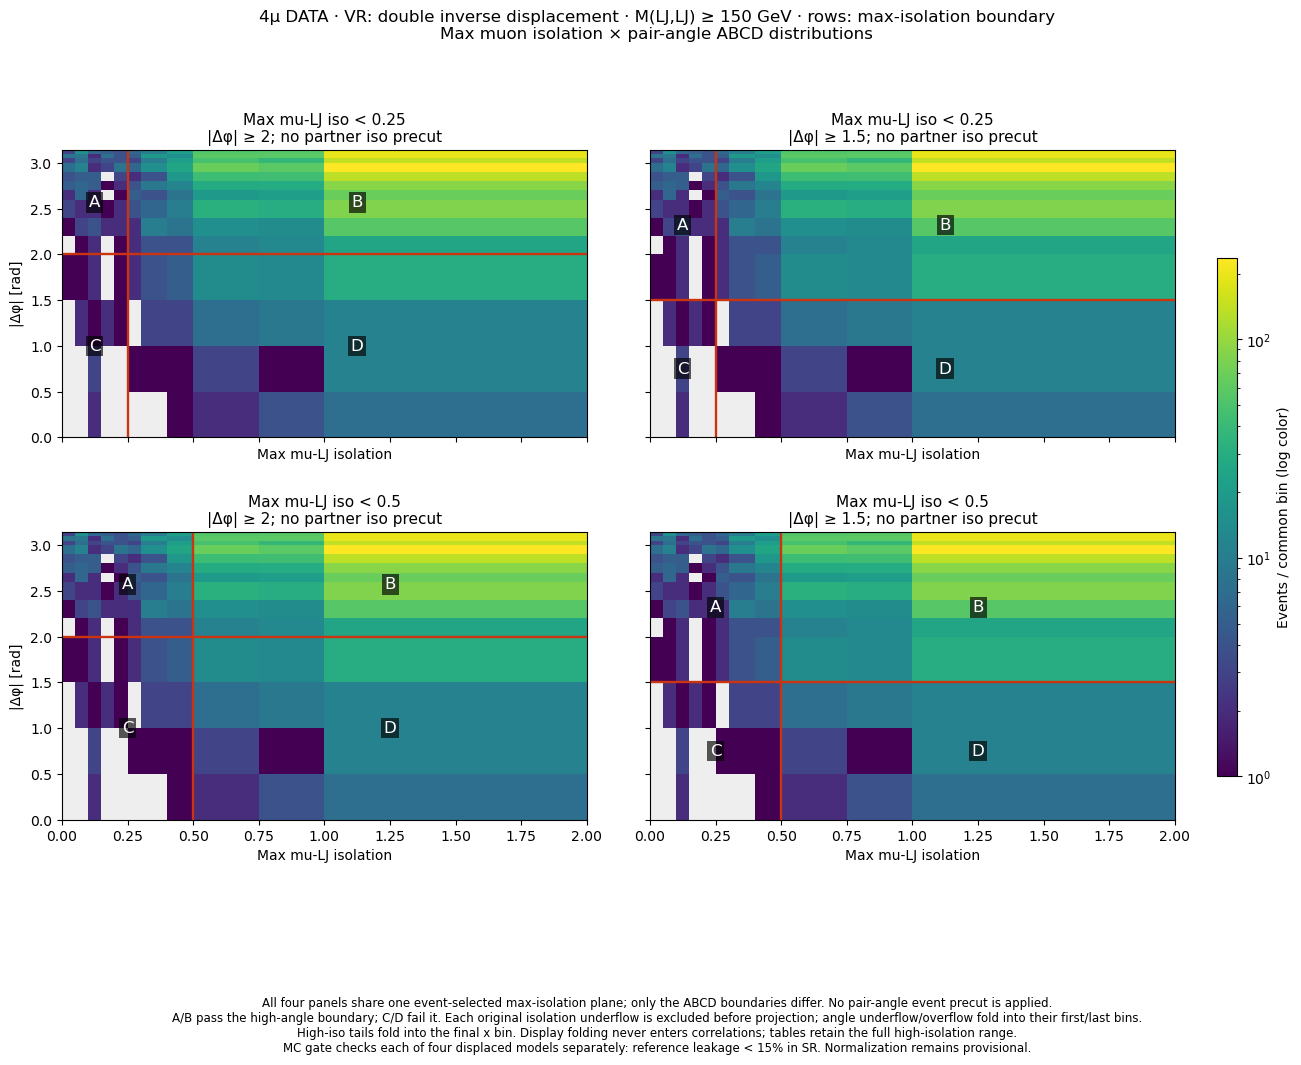

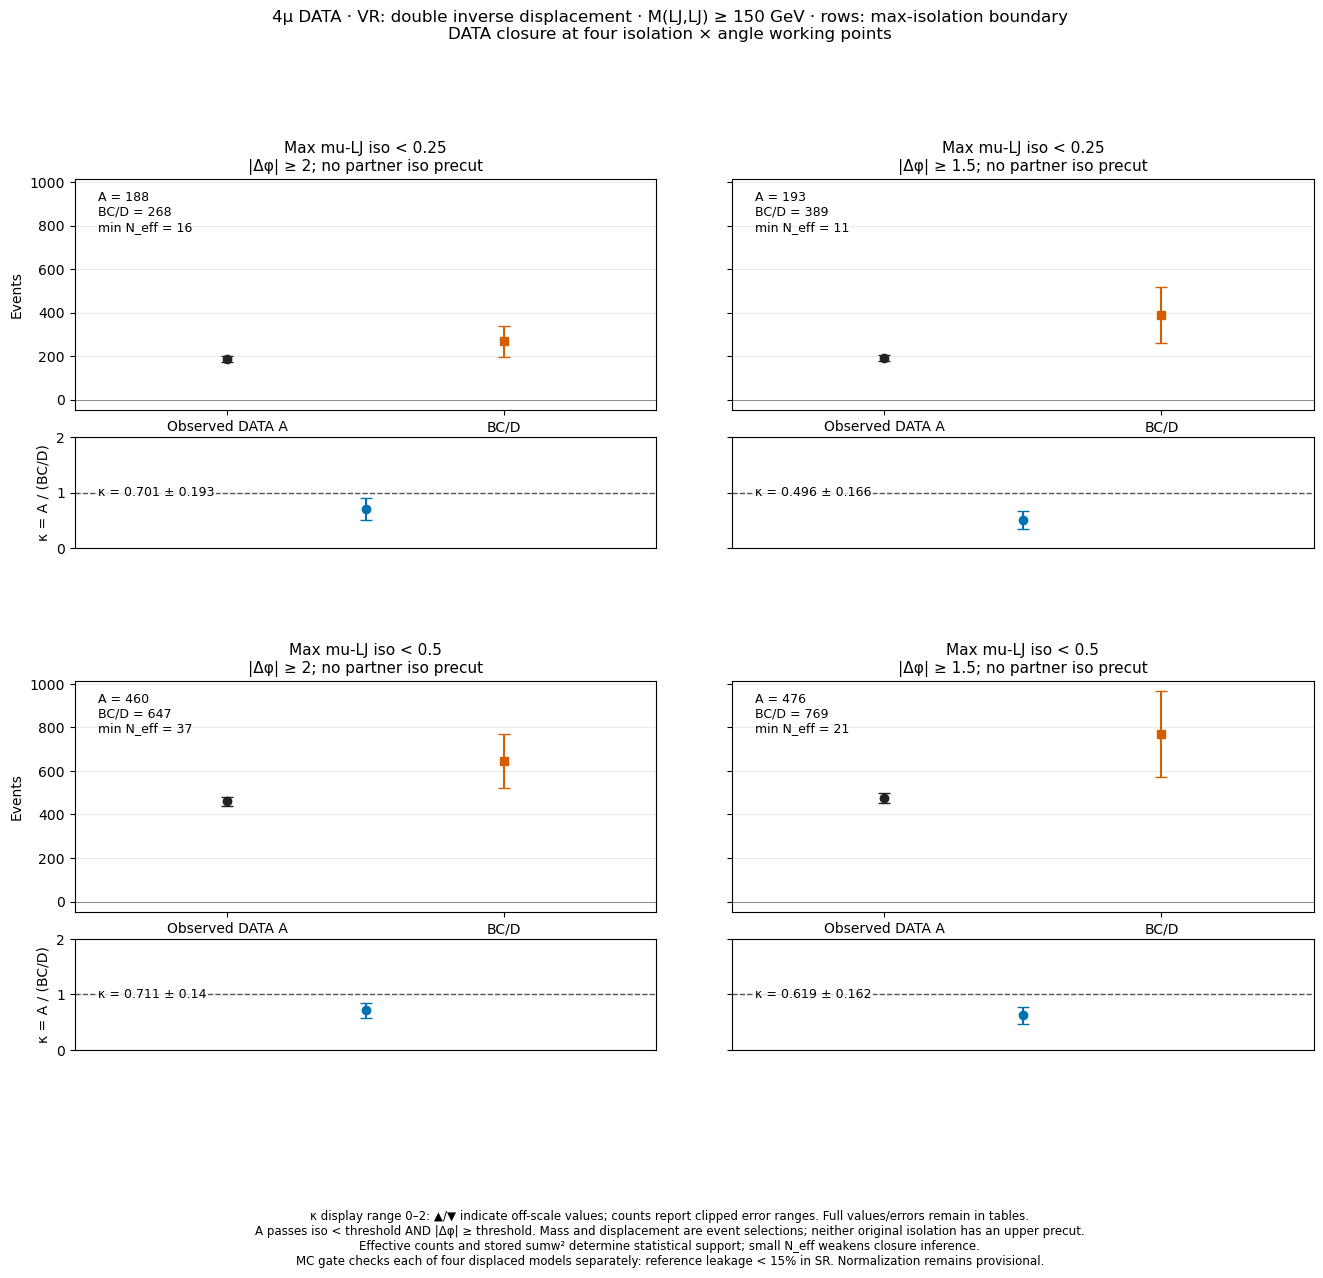

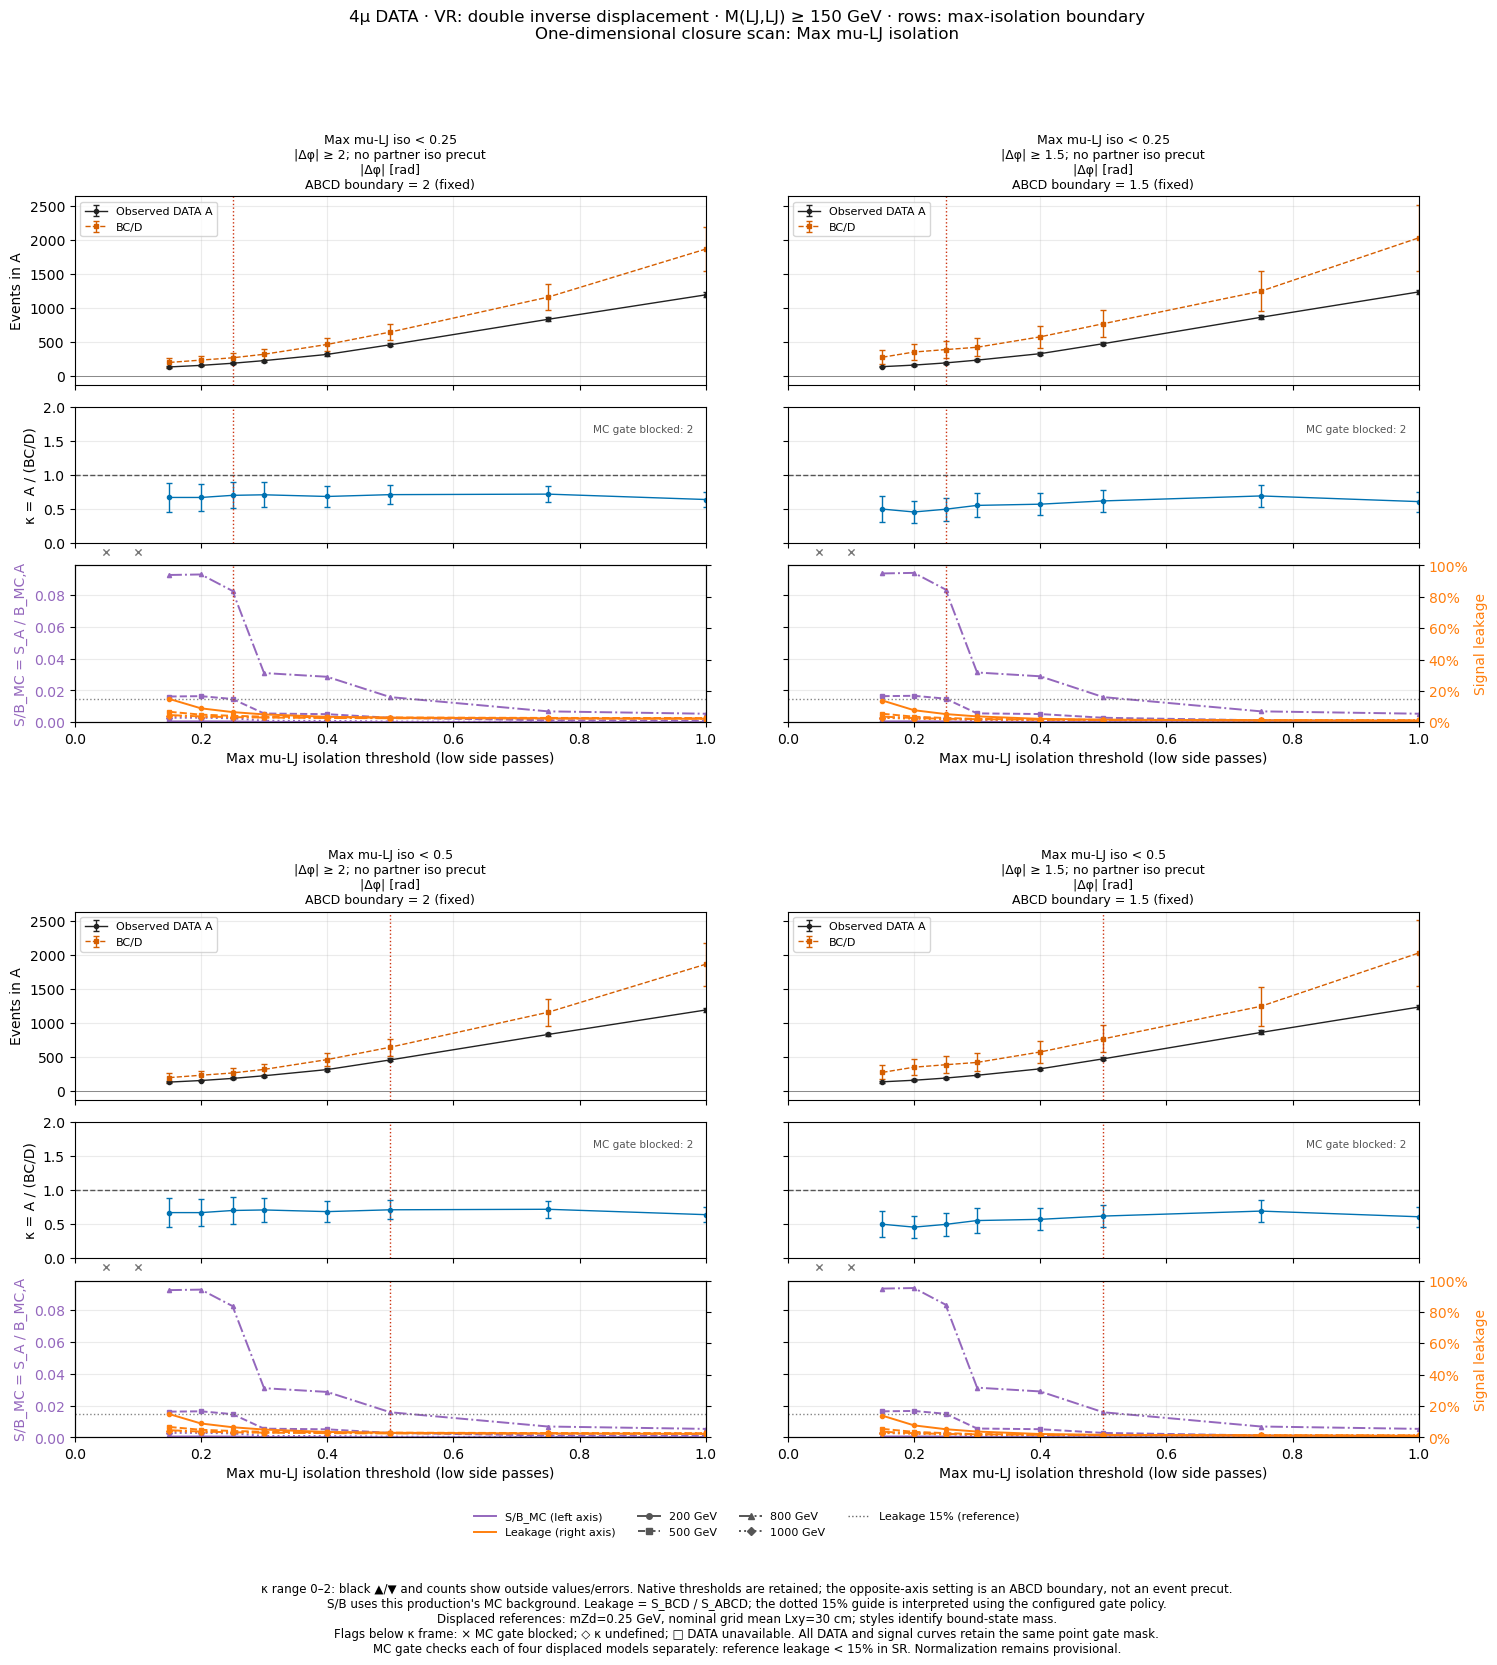

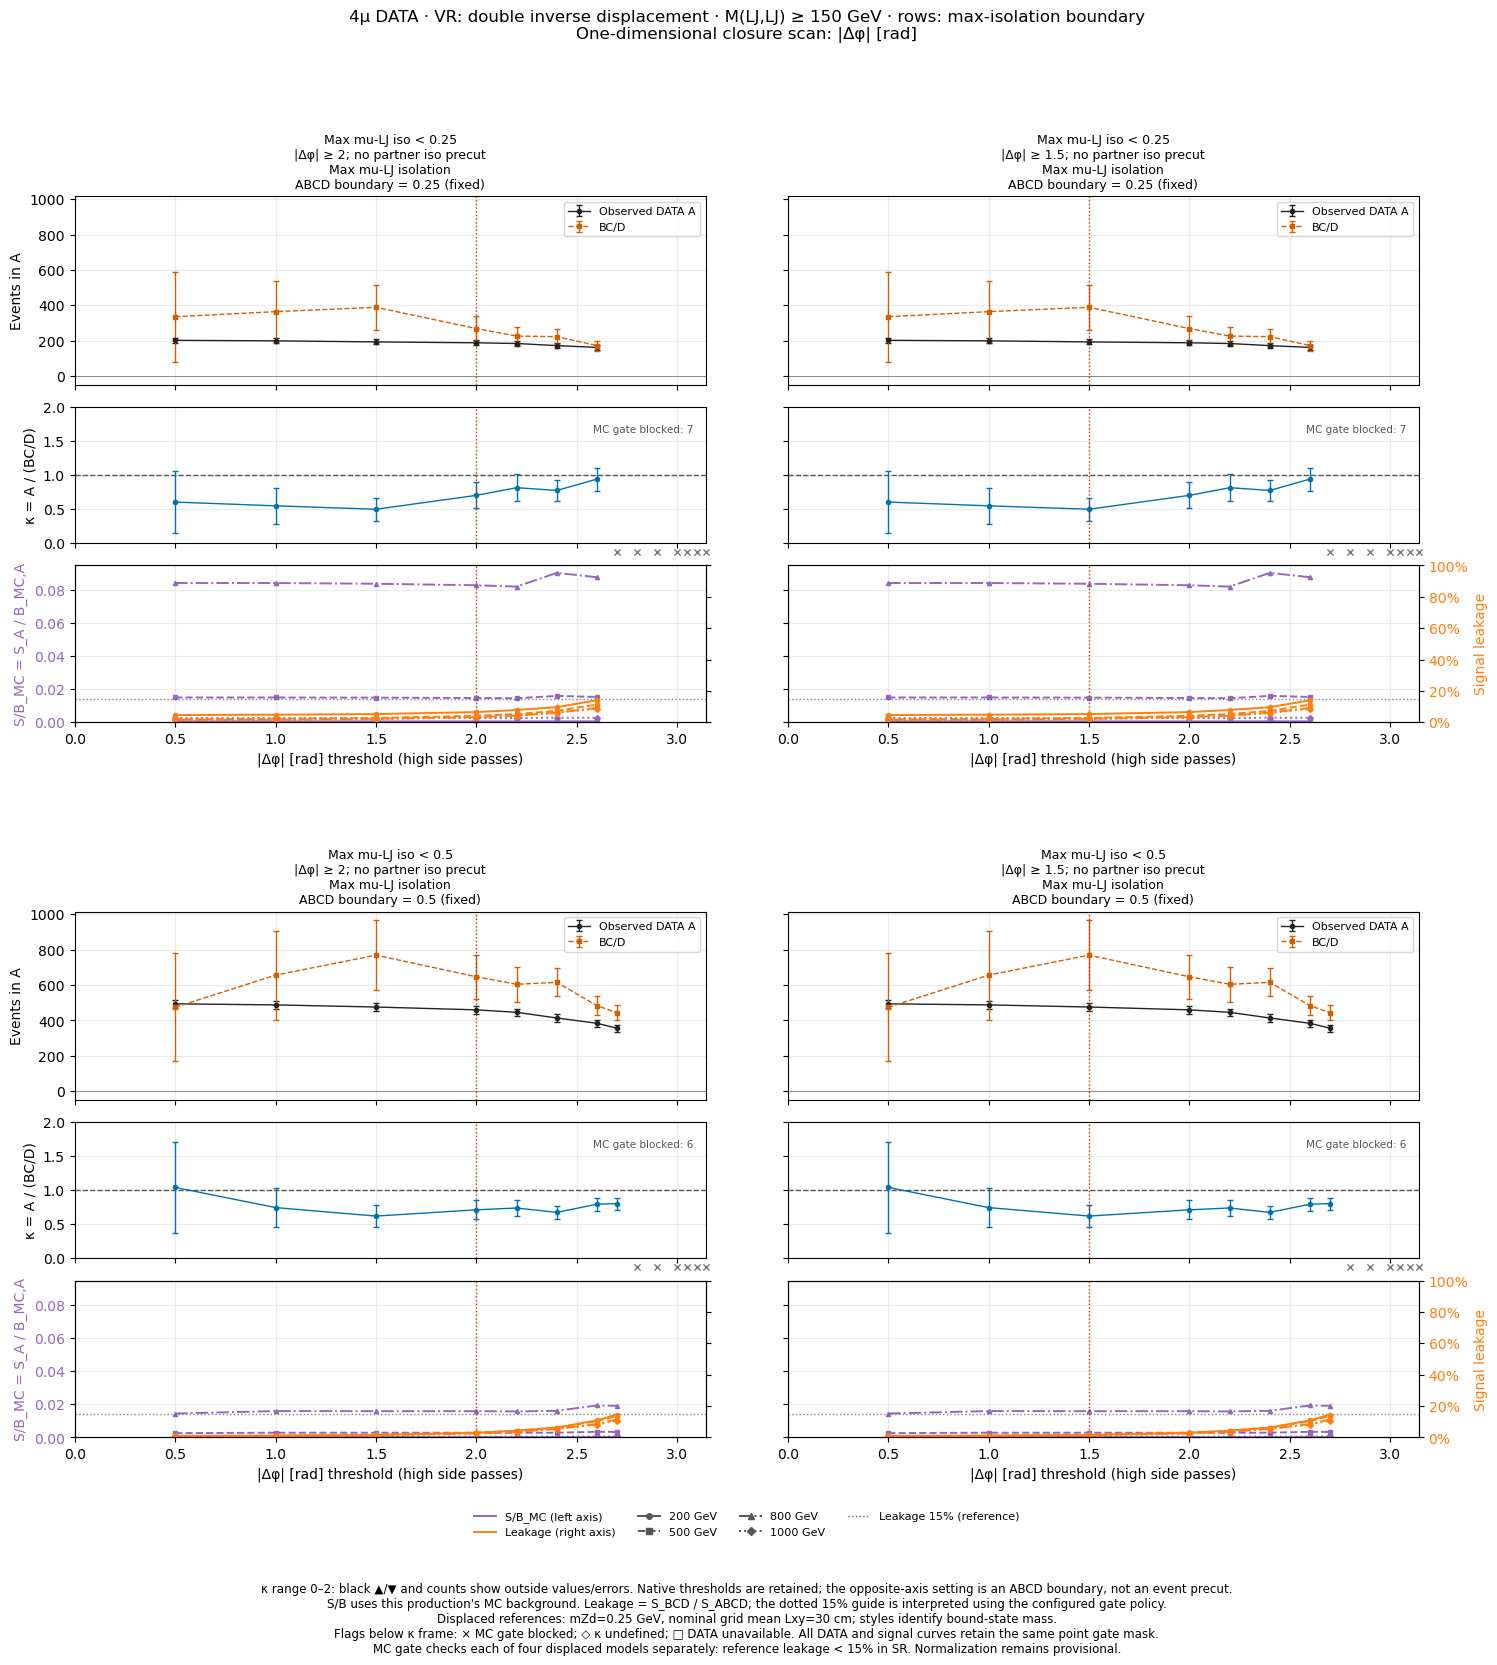

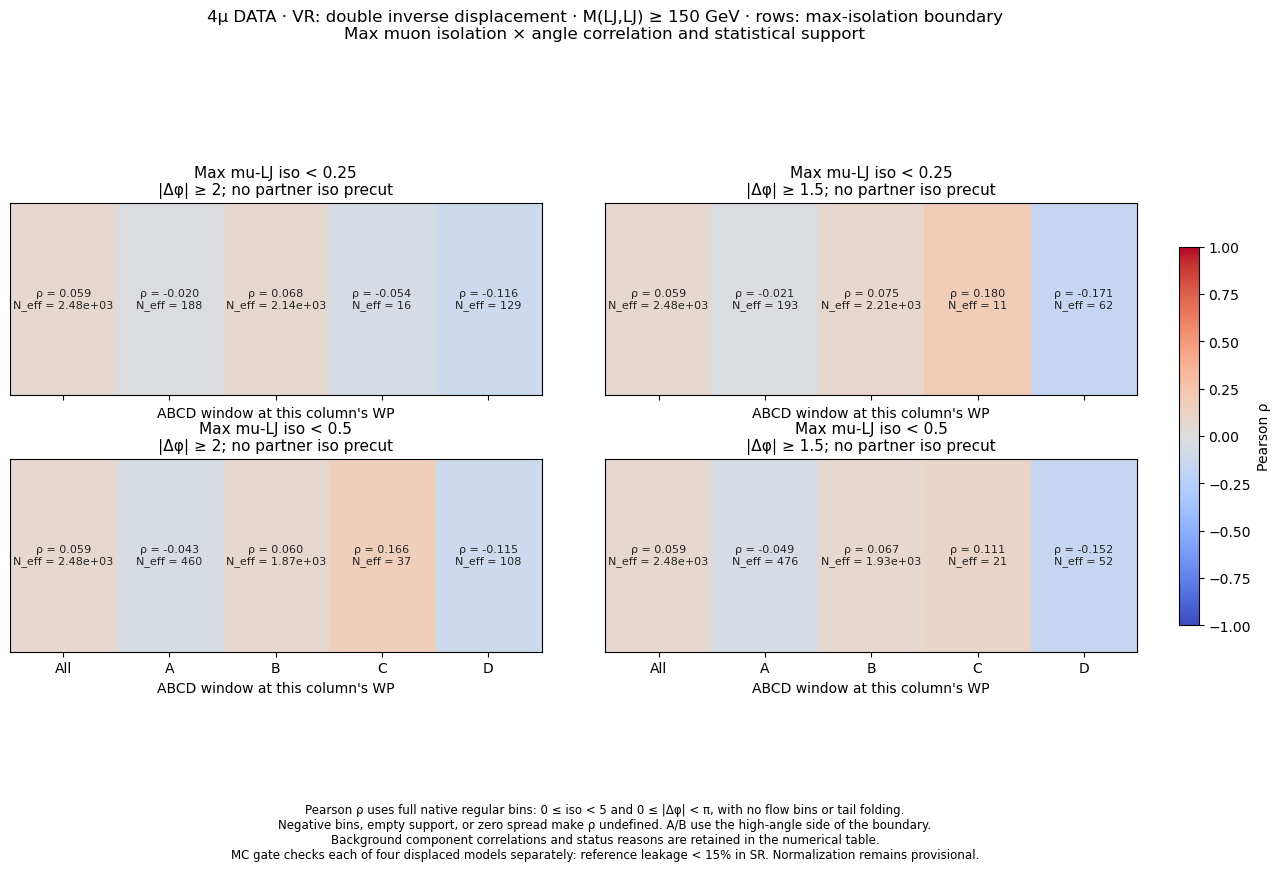

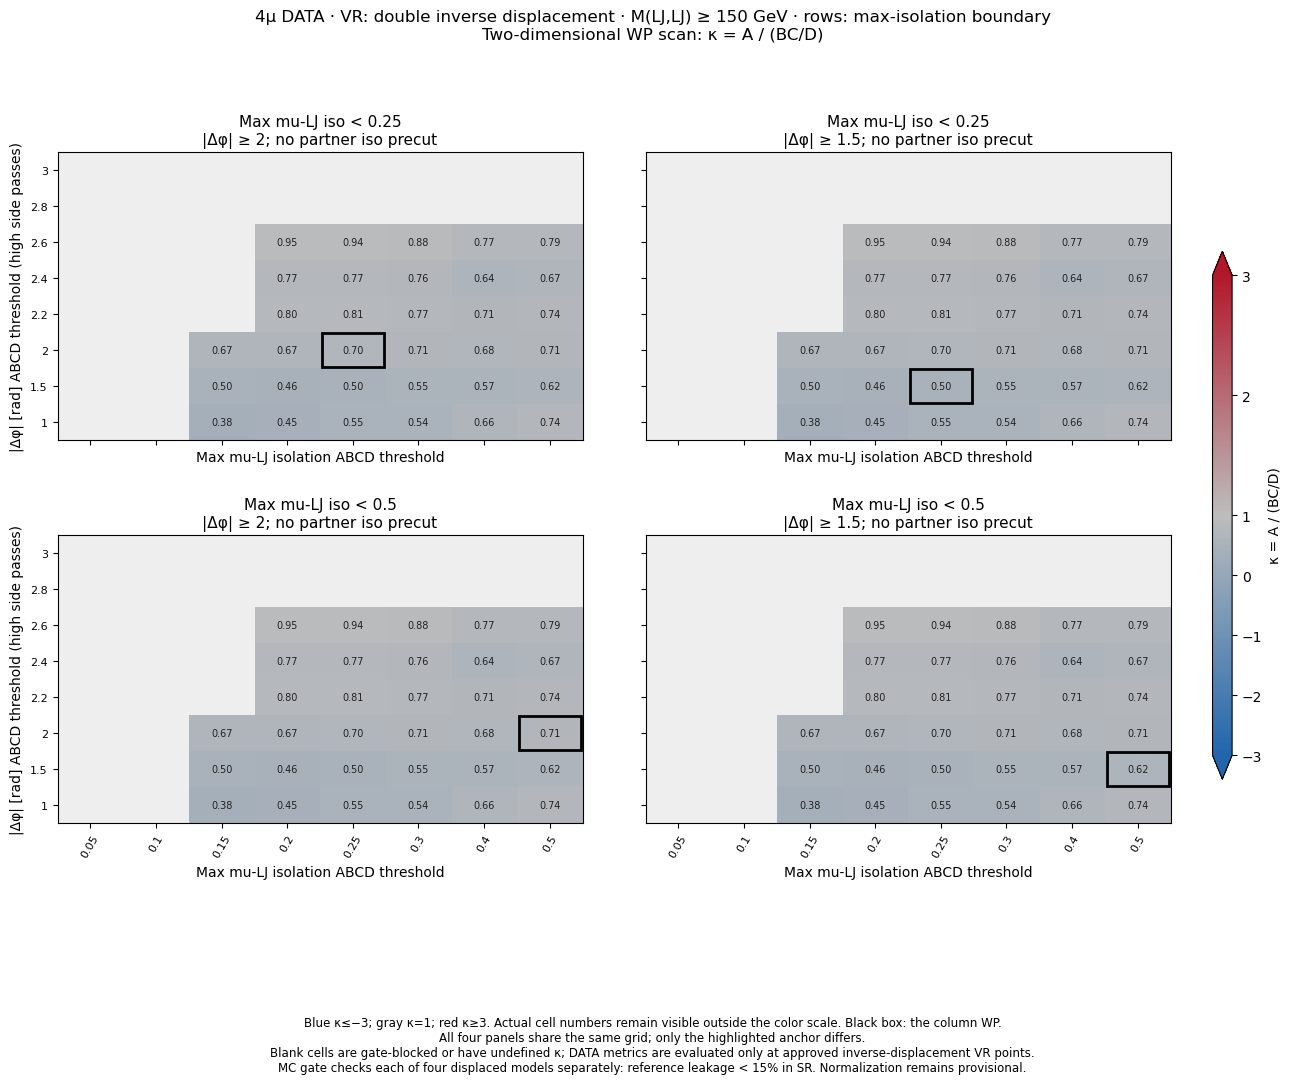

In [14]:
if RUN_DATA:
    present_plane_figures(plot_plane_distributions(data_results,DATA_CONFIG),source="DATA")
    present_plane_figures(plot_plane_closure(data_results,DATA_CONFIG),source="DATA")
    present_plane_figures(plot_plane_one_d(data_results,DATA_CONFIG),source="DATA")
    present_plane_figures(plot_plane_correlations(data_results,DATA_CONFIG),source="DATA")
    present_plane_figures(plot_plane_kappa_grid(data_results,DATA_CONFIG),source="DATA")
else:
    print("The conditional DATA VR section is disabled.")


## 검진 요약과 기존 μ-isolation 평면 참고

MC SR/VR와 허용된 DATA VR 결과를 정리한다. 기존 07/08의 저장된 CSV가 있으면 참고 표에 함께 표시하되 새로 실행하거나 수정하지 않는다. 동일 benchmark ID라도 두 노트북의 isolation 축·사전 선택 또는 경계 의미가 다를 수 있으므로 같은 이벤트 선택으로 간주하지 않는다.

검진에서는 κ≈1 여부와 오차, pull, sideband Neff 및 신호 누출을 함께 확인한다. 네 조합 중 좋은 결과만 추려 내보내지 않으며 이 결과만으로 최종 WP를 확정하지 않는다.


In [15]:
slide_facts = tables["closure_summary"].copy()
slide_facts["mass_min_GeV"] = MASS_MIN
slide_facts["plane_pass_directions"] = "Max mu-LJ isolation low; absolute delta phi high"
slide_facts["status"] = "Boundary comparison on current 6D; not a selected final working point"
data_slide_facts = data_tables["closure_summary"].copy()
data_slide_facts["scope"] = "Inverse-displacement VR only; four displaced-reference MC gate"
display(slide_facts)
display(data_slide_facts)

# Preserve existing notebook results as labeled context, without re-running or changing them.
prior_path = NOTEBOOK_DIR / PRIOR_NOTEBOOK_OUTPUT / "closure_summary.csv"
prior_data_path = NOTEBOOK_DIR / PRIOR_NOTEBOOK_OUTPUT / "data_VR_closure_summary.csv"
comparison_frames = []
for label, source, frame in (("Current plane", "MC", tables["closure_summary"]),
                              ("Current plane", "DATA", data_tables["closure_summary"]),
                              ("Previous mu-iso plane (saved)", "MC", pd.read_csv(prior_path) if prior_path.is_file() else pd.DataFrame()),
                              ("Previous mu-iso plane (saved)", "DATA", pd.read_csv(prior_data_path) if prior_data_path.is_file() else pd.DataFrame())):
    if not frame.empty:
        columns = [c for c in ("benchmark", "context", "tx", "ty", "A", "pred", "pred_error", "kappa", "kappa_error", "pull", "min_sideband_neff", "status", "approved") if c in frame]
        comparison_frames.append(frame[columns].assign(plane=label, source=source))
screening_summary = pd.concat(comparison_frames, ignore_index=True)
screening_summary["comparison_scope"] = "Shared mass/displacement; isolation preselection and/or axis differ. Benchmark IDs have notebook-specific meanings."
display(screening_summary)


,benchmark,context,tx,ty,pred,pred_error,kappa,kappa_error,pull,status,...,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column,mass_min_GeV,plane_pass_directions
0,p025_tight,SR,0.25,2.0,0.057608,0.073188,56.426115,91.201469,0.982805,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight,150.0,Max mu-LJ isolation low; absolute delta phi high
1,p025_tight,VR,0.25,2.0,3.893106,3.978259,32.304967,33.433660,5.804128,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight,150.0,Max mu-LJ isolation low; absolute delta phi high
2,p025_loose,SR,0.25,1.5,0.000000,0.000000,NaN,NaN,1.001582,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose,150.0,Max mu-LJ isolation low; absolute delta phi high
3,p025_loose,VR,0.25,1.5,5.545241,6.048765,22.680574,25.017856,5.595349,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose,150.0,Max mu-LJ isolation low; absolute delta phi high
4,p050_tight,SR,0.50,2.0,2.383958,3.005928,1.653168,2.505560,0.348008,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight,150.0,Max mu-LJ isolation low; absolute delta phi high
5,p050_tight,VR,0.50,2.0,2098.444810,1927.379360,0.315362,0.307931,-0.740624,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight,150.0,Max mu-LJ isolation low; absolute delta phi high
6,p050_loose,SR,0.50,1.5,2.544445,3.344619,1.549908,2.418128,0.297160,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose,150.0,Max mu-LJ isolation low; absolute delta phi high
7,p050_loose,VR,0.50,1.5,3355.116035,3421.784834,0.199465,0.213683,-0.783329,Boundary comparison on current 6D; not a selec...,...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose,150.0,Max mu-LJ isolation low; absolute delta phi high


,benchmark,context,tx,ty,pred,pred_error,kappa,kappa_error,pull,status,...,policy,plane_kind,row_meaning,profile,row_iso_value,mu_iso_precut,anchor_iso,anchor_dphi,column,scope
0,p025_tight,VR,0.25,2.0,268.270677,71.214232,0.700785,0.192921,-1.106843,OK,...,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,2.0,tight,Inverse-displacement VR only; four displaced-r...
1,p025_loose,VR,0.25,1.5,388.892308,127.048723,0.496281,0.166021,-1.532731,OK,...,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p025,0.25,NaN,0.25,1.5,loose,Inverse-displacement VR only; four displaced-r...
2,p050_tight,VR,0.50,2.0,646.839286,123.521450,0.711150,0.139792,-1.490307,OK,...,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,2.0,tight,Inverse-displacement VR only; four displaced-r...
3,p050_loose,VR,0.50,1.5,769.363636,198.097532,0.618693,0.161807,-1.472005,OK,...,Conditional four-reference leakage gate; full ...,max_mu_iso,max_iso_boundary,p050,0.50,NaN,0.50,1.5,loose,Inverse-displacement VR only; four displaced-r...


,benchmark,context,tx,ty,A,pred,pred_error,kappa,kappa_error,pull,min_sideband_neff,status,plane,source,approved,comparison_scope
0,p025_tight,SR,0.25,2.0,3.250611,0.057608,0.073188,56.426115,91.201469,0.982805,1.000000,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
1,p025_tight,VR,0.25,2.0,125.766675,3.893106,3.978259,32.304967,33.433660,5.804128,1.115032,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
2,p025_loose,SR,0.25,1.5,3.253182,0.000000,0.000000,NaN,NaN,1.001582,NaN,ZERO_SIDEBAND_LEGACY_ZERO_PREDICTION_ERROR,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
3,p025_loose,VR,0.25,1.5,125.769246,5.545241,6.048765,22.680574,25.017856,5.595349,1.087806,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
4,p050_tight,SR,0.50,2.0,3.941083,2.383958,3.005928,1.653168,2.505560,0.348008,1.128931,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
5,p050_tight,VR,0.50,2.0,661.769800,2098.444810,1927.379360,0.315362,0.307931,-0.740624,1.262527,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
6,p050_loose,SR,0.50,1.5,3.943654,2.544445,3.344619,1.549908,2.418128,0.297160,1.072164,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
7,p050_loose,VR,0.50,1.5,669.228579,3355.116035,3421.784834,0.199465,0.213683,-0.783329,1.048333,LOW_STAT_SIDEBAND,Current plane,MC,NaN,Shared mass/displacement; isolation preselecti...
8,p025_tight,VR,0.25,2.0,188.000000,268.270677,71.214232,0.700785,0.192921,-1.106843,16.000000,OK,Current plane,DATA,True,Shared mass/displacement; isolation preselecti...
9,p025_loose,VR,0.25,1.5,193.000000,388.892308,127.048723,0.496281,0.166021,-1.532731,11.000000,OK,Current plane,DATA,True,Shared mass/displacement; isolation preselecti...


## 결과 저장

정확한 plane 정의와 네 조합, 입력 manifest, 선택 검증, A/B/C/D yield·sumw², closure, κ grid, 1D scan, 상관관계, 신호 진단, DATA gate와 VR 상태를 CSV로 저장한다. 그림은 PNG/PDF로 저장한다.

전체 signal 혼합은 진단용으로만 유지한다. DATA VR closure와 MC SR의 저통계 한계를 별도로 보고하며 최종 SR 예측 검증으로 확대 해석하지 않는다. 원래 isolation underflow는 각각 제외하고 flow folding은 표시용으로만 사용한다.


In [16]:
export_plane_results(mc_results,data_results,{"slide_facts":slide_facts,
    "data_VR_slide_facts":data_slide_facts,"figure_audit":pd.DataFrame(FIGURE_RECORDS), "screening_summary":screening_summary})
print("Complete: current 6D max_mu_iso versus delta-phi tight/loose comparison.")


Saved plane comparison artifacts: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/10_MaxIso_DPhi_4mu_6D_comparison_outputs
Complete: current 6D max_mu_iso versus delta-phi tight/loose comparison.
